In [ ]:

import os
import zipfile
import glob
import pandas as pd

# Find the uploaded ZIP in Colab's /content folder
zip_files = glob.glob("/content/*.zip")

print("ZIP files found:", zip_files)

if not zip_files:
    from google.colab import files
    uploaded = files.upload()
    zip_files = [
        "/content/" + name
        for name in uploaded.keys()
        if name.lower().endswith(".zip")
    ]

if not zip_files:
    raise FileNotFoundError("Please upload the SHE-GUARD ZIP file.")

ZIP_PATH = zip_files[0]
DATA_DIR = "/content/she_guard_data"

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(DATA_DIR)

print("\nExtraction successful!")

csv_files = glob.glob(
    DATA_DIR + "/**/*.csv",
    recursive=True
)

print("Total CSV files:", len(csv_files))

for path in sorted(csv_files):
    df = pd.read_csv(path)
    print("\nFILE:", os.path.basename(path))
    print("Shape:", df.shape)
    print("Columns:", list(df.columns))
    print(df.head(3).to_string(index=False))


ZIP files found: ['/content/she_guard_geodata_nextstep (1).zip']

Extraction successful!
Total CSV files: 5

FILE: bengaluru_candidate_police_station_locations.csv
Shape: (147, 12)
Columns: ['OBJECTID', 'DepartmentCode', 'KGISVillageID', 'KGISCode', 'KGISPOL_STAID', 'POL_STAName', 'KGISPSCode', 'longitude', 'latitude', 'source_file', 'location_type', 'filter_note']
 OBJECTID  DepartmentCode  KGISVillageID                              KGISCode  KGISPOL_STAID       POL_STAName KGISPSCode  longitude  latitude                              source_file                              location_type                                                                                                              filter_note
       81       164431398        30092.0 29572055428031620000HMPOLPUOFFPOS0003           84.0    Cubbon Park PS    PS - 84  77.597964 12.980030 9181e6ed-6164-430b-8b10-238ad7b8ab45.kml police_station_location_not_crime_incident Approximate coordinate bounding box only; includes near

In [ ]:

import os
import glob
import pandas as pd

DATA_DIR = "/content/she_guard_data"

csv_files = glob.glob(
    DATA_DIR + "/**/*.csv",
    recursive=True
)

for path in sorted(csv_files):
    df = pd.read_csv(path)

    print("\n" + "=" * 65)
    print("FILE:", os.path.basename(path))
    print("Rows:", df.shape[0], "| Columns:", df.shape[1])

    print("\nMissing values:")
    print(df.isnull().sum().to_string())

    print("\nDuplicate rows:", df.duplicated().sum())

    print("\nColumn data types:")
    print(df.dtypes.to_string())

    # Check whether usable coordinates exist
    coord_cols = [
        c for c in df.columns
        if any(x in c.lower() for x in
               ["latitude", "longitude", "district", "station", "crime"])
    ]

    print("\nLocation/crime-related columns:", coord_cols)



FILE: bengaluru_candidate_police_station_locations.csv
Rows: 147 | Columns: 12

Missing values:
OBJECTID           0
DepartmentCode     0
KGISVillageID     18
KGISCode          18
KGISPOL_STAID     18
POL_STAName        0
KGISPSCode        18
longitude          0
latitude           0
source_file        0
location_type      0
filter_note        0

Duplicate rows: 0

Column data types:
OBJECTID            int64
DepartmentCode      int64
KGISVillageID     float64
KGISCode           object
KGISPOL_STAID     float64
POL_STAName        object
KGISPSCode         object
longitude         float64
latitude          float64
source_file        object
location_type      object
filter_note        object

Location/crime-related columns: ['longitude', 'latitude']

FILE: bengaluru_crime_type_annual_counts_2021_2023_clean.csv
Rows: 12 | Columns: 7

Missing values:
Type of Crime    0
2021 Reported    0
2021 Detected    0
2022 Reported    0
2022 Detected    0
2023 Reported    0
2023 Detected    0

Duplic

In [ ]:

import pandas as pd
import glob
import os

DATA_DIR = "/content/she_guard_data"

crime_file = glob.glob(
    DATA_DIR + "/**/bengaluru_crime_type_annual_counts_2021_2023_clean.csv",
    recursive=True
)[0]

crime_df = pd.read_csv(crime_file)

print("Crime categories:")
print(crime_df["Type of Crime"].tolist())

print("\nFull annual crime data:")
display(crime_df)

print("\nReported crime totals:")
for year in [2021, 2022, 2023]:
    col = f"{year} Reported"
    print(year, ":", crime_df[col].sum())


Crime categories:
['Murder', 'Murder (Gain)', 'Dacoity', 'Robbery', 'Chain Snatching', 'HBT (Day)', 'HBT( Night)', 'House Thefts', 'Servant Thefts', 'M.V.Thefts', 'Ordinary Thefts', 'TOTAL']

Full annual crime data:


,Type of Crime,2021 Reported,2021 Detected,2022 Reported,2022 Detected,2023 Reported,2023 Detected
0,Murder,145,143,156,156,205,200
1,Murder (Gain),8,8,17,17,2,2
2,Dacoity,35,35,23,23,36,34
3,Robbery,364,317,478,414,673,437
4,Chain Snatching,166,166,151,139,153,114
5,HBT (Day),135,82,179,99,265,118
6,HBT( Night),654,361,702,333,879,264
7,House Thefts,591,290,912,339,1692,376
8,Servant Thefts,177,132,205,146,320,141
9,M.V.Thefts,4124,1563,5062,1965,5909,1437



Reported crime totals:
2021 : 15132
2022 : 18508
2023 : 25254


In [ ]:

import os
import glob
import zipfile
import pandas as pd

from google.colab import files

# Upload the downloaded audit ZIP from your computer
uploaded = files.upload()

zip_files = [
    name for name in uploaded
    if name.lower().endswith(".zip")
]

if not zip_files:
    raise ValueError("Please upload the SHE-GUARD Data Audit ZIP.")

ZIP_PATH = "/content/" + zip_files[0]
DATA_DIR = "/content/she_guard_final_audit"

# Extract the ZIP
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(DATA_DIR)

# Find the consolidated annual crime dataset
matches = glob.glob(
    DATA_DIR + "/**/district_crime_totals_2023_2025.csv",
    recursive=True
)

if not matches:
    raise FileNotFoundError(
        "Consolidated crime totals CSV was not found in the ZIP."
    )

df = pd.read_csv(matches[0])

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nYear-wise record counts:")
print(df.groupby("year").size())

print("\nBengaluru-related records:")
bengaluru = df[
    df["district_or_unit"].str.contains(
        "bengaluru|bangalore", case=False, na=False
    )
]

display(
    bengaluru[
        ["year", "district_or_unit",
         "ipc_or_bns_cases", "sll_cases",
         "total_reported_cases"]
    ].sort_values(["year", "district_or_unit"])
)


Saving SHE_GUARD_Data_Audit_Download.zip to SHE_GUARD_Data_Audit_Download.zip
Dataset loaded successfully!
Shape: (124, 7)

Columns:
['year', 'district_or_unit', 'ipc_or_bns_cases', 'sll_cases', 'total_reported_cases', 'geographic_level', 'source_file']

Year-wise record counts:
year
2023    39
2024    39
2025    46
dtype: int64

Bengaluru-related records:


,year,district_or_unit,ipc_or_bns_cases,sll_cases,total_reported_cases
1,2023,Bengaluru City,28666.0,17521.0,46187.0
2,2023,Bengaluru District,6031.0,961.0,6992.0
40,2024,Bengaluru City,41637.0,26883.0,68520.0
41,2024,Bengaluru District,7568.0,1853.0,9421.0
78,2025,Bengaluru City,37181.0,19291.0,56472.0
85,2025,Bengaluru Dist,6433.0,1187.0,7620.0
86,2025,Bengaluru South,3644.0,936.0,4580.0


In [ ]:

# STEP 4: Validate the consolidated dataset

print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nRecords by year and geographical unit:")
print(
    df.sort_values(["year", "district_or_unit"])[
        ["year", "district_or_unit", "total_reported_cases"]
    ].to_string(index=False)
)

print("\nCheck for negative counts:")
count_cols = [
    "ipc_or_bns_cases",
    "sll_cases",
    "total_reported_cases"
]

for col in count_cols:
    print(col, ":", (df[col].dropna() < 0).sum())

print("\nBengaluru-related records:")
display(
    df[
        df["district_or_unit"].str.contains(
            "bengaluru|bangalore", case=False, na=False
        )
    ].sort_values(["year", "district_or_unit"])
)


Dataset shape: (124, 7)

Missing values:
year                    0
district_or_unit        0
ipc_or_bns_cases        7
sll_cases               7
total_reported_cases    7
geographic_level        0
source_file             0
dtype: int64

Duplicate rows: 0

Records by year and geographical unit:
 year      district_or_unit  total_reported_cases
 2023              Bagalkot                2934.0
 2023               Ballari                3226.0
 2023         Belagavi City                2127.0
 2023     Belagavi District                6027.0
 2023        Bengaluru City               46187.0
 2023    Bengaluru District                6992.0
 2023                 Bidar                4022.0
 2023         Chamarajnagar                2373.0
 2023       Chikkaballapura                4320.0
 2023        Chikkamagaluru                3855.0
 2023           Chitradurga                5321.0
 2023      Dakshina Kannada                2078.0
 2023            Davanagere                4391.0
 2023

,year,district_or_unit,ipc_or_bns_cases,sll_cases,total_reported_cases,geographic_level,source_file
1,2023,Bengaluru City,28666.0,17521.0,46187.0,district_or_unit_aggregate,646a37e6-e4a4-4cd7-ae69-ebc37d4fa7e5.csv
2,2023,Bengaluru District,6031.0,961.0,6992.0,district_or_unit_aggregate,646a37e6-e4a4-4cd7-ae69-ebc37d4fa7e5.csv
40,2024,Bengaluru City,41637.0,26883.0,68520.0,district_or_unit_aggregate,ffce2bf3-1202-489d-8af5-f156c2e9b793.csv
41,2024,Bengaluru District,7568.0,1853.0,9421.0,district_or_unit_aggregate,ffce2bf3-1202-489d-8af5-f156c2e9b793.csv
78,2025,Bengaluru City,37181.0,19291.0,56472.0,district_or_unit_aggregate,ka-district-wise-2025.csv
85,2025,Bengaluru Dist,6433.0,1187.0,7620.0,district_or_unit_aggregate,ka-district-wise-2025.csv
86,2025,Bengaluru South,3644.0,936.0,4580.0,district_or_unit_aggregate,ka-district-wise-2025.csv


In [ ]:

# STEP 5: Check whether the dataset supports location-level ML

print("Total rows:", len(df))

print("\nAvailable columns:")
for col in df.columns:
    print("-", col)

location_columns = [
    col for col in df.columns
    if any(term in col.lower() for term in [
        "latitude", "longitude", "station",
        "location", "area", "address", "pincode"
    ])
]

incident_columns = [
    col for col in df.columns
    if any(term in col.lower() for term in [
        "incident_date", "crime_date", "timestamp",
        "date_of_crime", "time_of_crime"
    ])
]

print("\nLocation-related columns:", location_columns)
print("Incident date/time columns:", incident_columns)

if not location_columns:
    print("\nRESULT: No direct location fields in the annual totals.")

if not incident_columns:
    print("RESULT: No incident-level date/time fields found.")

print("\nConclusion:")
print("Annual aggregates alone are insufficient for street-level ML.")


Total rows: 124

Available columns:
- year
- district_or_unit
- ipc_or_bns_cases
- sll_cases
- total_reported_cases
- geographic_level
- source_file

Location-related columns: []
Incident date/time columns: []

RESULT: No direct location fields in the annual totals.
RESULT: No incident-level date/time fields found.

Conclusion:
Annual aggregates alone are insufficient for street-level ML.


In [ ]:

import requests

# Example coordinates only: Bengaluru
# Format: longitude, latitude
start = (77.5946, 12.9716)
destination = (77.6245, 12.9352)

url = (
    "https://router.project-osrm.org/route/v1/driving/"
    f"{start[0]},{start[1]};"
    f"{destination[0]},{destination[1]}"
)

params = {
    "overview": "false",
    "alternatives": "true",
    "steps": "false"
}

try:
    response = requests.get(url, params=params, timeout=20)
    response.raise_for_status()
    data = response.json()

    if data.get("code") == "Ok" and data.get("routes"):
        print("✅ ROUTE ENGINE WORKING")
        print("Routes returned:", len(data["routes"]))

        for i, route in enumerate(data["routes"], start=1):
            print(f"\nRoute {i}")
            print(f"Distance: {route['distance'] / 1000:.2f} km")
            print(f"Estimated driving time: {route['duration'] / 60:.1f} min")
    else:
        print("No route returned.")
        print("Service response:", data)

except requests.RequestException as e:
    print("Routing service unavailable:", e)
    print("We can retry or use another routing provider.")


✅ ROUTE ENGINE WORKING
Routes returned: 2

Route 1
Distance: 7.50 km
Estimated driving time: 12.3 min

Route 2
Distance: 8.69 km
Estimated driving time: 12.3 min


In [ ]:

def calculate_route_risk(
    crime_risk,
    time_risk,
    isolation_risk
):
    """
    Prototype only.
    Inputs are simulated scores from 0 to 100.
    These are NOT real crime predictions.
    """

    values = [crime_risk, time_risk, isolation_risk]

    if any(not isinstance(v, (int, float)) or not 0 <= v <= 100
           for v in values):
        raise ValueError("Every risk input must be between 0 and 100.")

    risk_score = (
        0.60 * crime_risk +
        0.25 * time_risk +
        0.15 * isolation_risk
    )

    if risk_score < 30:
        risk_level = "Lower (prototype)"
    elif risk_score < 60:
        risk_level = "Moderate (prototype)"
    else:
        risk_level = "Elevated (prototype)"

    return {
        "risk_score": round(risk_score, 1),
        "risk_level": risk_level
    }


# Test with SIMULATED values only
test_result = calculate_route_risk(
    crime_risk=20,
    time_risk=40,
    isolation_risk=30
)

print("Prototype risk result:", test_result)


Prototype risk result: {'risk_score': 26.5, 'risk_level': 'Lower (prototype)'}


In [ ]:

# SIMULATED DATA ONLY — not actual Bengaluru crime data

routes = [
    {
        "route": "Route 1",
        "distance_km": 7.50,
        "duration_min": 12.3,
        "crime_risk": 20,
        "time_risk": 40,
        "isolation_risk": 30
    },
    {
        "route": "Route 2",
        "distance_km": 8.69,
        "duration_min": 12.3,
        "crime_risk": 10,
        "time_risk": 30,
        "isolation_risk": 20
    }
]

for route in routes:
    result = calculate_route_risk(
        crime_risk=route["crime_risk"],
        time_risk=route["time_risk"],
        isolation_risk=route["isolation_risk"]
    )

    route["risk_score"] = result["risk_score"]
    route["risk_level"] = result["risk_level"]

for route in routes:
    print(
        f"{route['route']} | "
        f"Distance: {route['distance_km']} km | "
        f"Time: {route['duration_min']} min | "
        f"Risk score: {route['risk_score']}/100 | "
        f"Level: {route['risk_level']}"
    )

best_route = min(routes, key=lambda r: r["risk_score"])

print("\nPrototype's lowest-score option:", best_route["route"])
print("Reminder: simulated scores, not a real safety recommendation.")


Route 1 | Distance: 7.5 km | Time: 12.3 min | Risk score: 26.5/100 | Level: Lower (prototype)
Route 2 | Distance: 8.69 km | Time: 12.3 min | Risk score: 16.5/100 | Level: Lower (prototype)

Prototype's lowest-score option: Route 2
Reminder: simulated scores, not a real safety recommendation.


In [ ]:

import pandas as pd

route_table = pd.DataFrame([
    {
        "route_id": "R1",
        "distance_km": 7.50,
        "duration_min": 12.3,
        "crime_risk_input": 20,
        "time_risk_input": 40,
        "isolation_risk_input": 30
    },
    {
        "route_id": "R2",
        "distance_km": 8.69,
        "duration_min": 12.3,
        "crime_risk_input": 10,
        "time_risk_input": 30,
        "isolation_risk_input": 20
    }
])

route_table["risk_score"] = route_table.apply(
    lambda row: calculate_route_risk(
        row["crime_risk_input"],
        row["time_risk_input"],
        row["isolation_risk_input"]
    )["risk_score"],
    axis=1
)

display(route_table)


,route_id,distance_km,duration_min,crime_risk_input,time_risk_input,isolation_risk_input,risk_score
0,R1,7.50,12.3,20,40,30,26.5
1,R2,8.69,12.3,10,30,20,16.5


In [ ]:

import requests
import pandas as pd

# Example coordinates only — not live GPS
start = (77.5946, 12.9716)       # longitude, latitude
destination = (77.6245, 12.9352)

url = (
    "https://router.project-osrm.org/route/v1/driving/"
    f"{start[0]},{start[1]};{destination[0]},{destination[1]}"
)

response = requests.get(
    url,
    params={
        "overview": "false",
        "alternatives": "true",
        "steps": "false"
    },
    timeout=20
)
response.raise_for_status()
data = response.json()

if data.get("code") != "Ok" or not data.get("routes"):
    raise RuntimeError(f"Routing failed: {data}")

route_rows = []

for i, route in enumerate(data["routes"], start=1):
    route_rows.append({
        "route_id": f"R{i}",
        "distance_km": round(route["distance"] / 1000, 2),
        "duration_min": round(route["duration"] / 60, 1),
        "risk_score": None,
        "risk_status": "Not assessed — no verified risk data"
    })

actual_route_table = pd.DataFrame(route_rows)
display(actual_route_table)

print("Routes received from routing API:", len(actual_route_table))
print("Note: route availability does not indicate route safety.")


,route_id,distance_km,duration_min,risk_score,risk_status
0,R1,7.50,12.3,None,Not assessed — no verified risk data
1,R2,8.69,12.3,None,Not assessed — no verified risk data


Routes received from routing API: 2
Note: route availability does not indicate route safety.


In [ ]:

import os

# Search common Colab locations for our extracted audit files
search_roots = ["/content", "/content/drive/MyDrive"]

matches = []

for root in search_roots:
    if not os.path.exists(root):
        continue

    for current_root, dirs, files in os.walk(root):
        # Avoid scanning very large dependency folders
        dirs[:] = [
            d for d in dirs
            if d not in {"site-packages", ".git", "node_modules"}
        ]

        for filename in files:
            if filename.lower().endswith((".csv", ".kml")):
                if (
                    "police_station" in filename.lower()
                    or "crime" in filename.lower()
                    or "district_crime" in filename.lower()
                ):
                    matches.append(
                        os.path.join(current_root, filename)
                    )

print("Relevant files found:", len(matches))

for path in matches[:30]:
    print(path)

if not matches:
    print("No matching files found. We may need to upload the audit ZIP again.")


Relevant files found: 7
/content/she_guard_final_audit/SHE_GUARD_Data_Audit/district_crime_totals_2023_2025.csv
/content/she_guard_final_audit/SHE_GUARD_Data_Audit/source_csvs/ka-ipc-crimes-2025.csv
/content/she_guard_final_audit/SHE_GUARD_Data_Audit/source_csvs/ka-sll-crimes-2025.csv
/content/she_guard_data/she_guard_geodata_nextstep/bengaluru_candidate_police_station_locations.csv
/content/she_guard_data/she_guard_geodata_nextstep/bengaluru_crime_type_annual_counts_long.csv
/content/she_guard_data/she_guard_geodata_nextstep/bengaluru_crime_type_annual_counts_2021_2023_clean.csv
/content/she_guard_data/she_guard_geodata_nextstep/karnataka_police_station_locations.csv


In [ ]:

import pandas as pd
import os

files_to_check = {
    "Crime totals": (
        "/content/she_guard_final_audit/"
        "SHE_GUARD_Data_Audit/district_crime_totals_2023_2025.csv"
    ),
    "Police station locations": (
        "/content/she_guard_data/"
        "she_guard_geodata_nextstep/"
        "bengaluru_candidate_police_station_locations.csv"
    ),
    "Crime categories": (
        "/content/she_guard_data/"
        "she_guard_geodata_nextstep/"
        "bengaluru_crime_type_annual_counts_2021_2023_clean.csv"
    )
}

for label, path in files_to_check.items():
    print(f"\n--- {label} ---")

    if os.path.exists(path):
        sample = pd.read_csv(path, nrows=3)
        print("Columns:", sample.columns.tolist())
        print(sample.head(2).to_string(index=False))
    else:
        print("File not found:", path)



--- Crime totals ---
Columns: ['year', 'district_or_unit', 'ipc_or_bns_cases', 'sll_cases', 'total_reported_cases', 'geographic_level', 'source_file']
 year district_or_unit  ipc_or_bns_cases  sll_cases  total_reported_cases           geographic_level                              source_file
 2023         Bagalkot            2199.0      735.0                2934.0 district_or_unit_aggregate 646a37e6-e4a4-4cd7-ae69-ebc37d4fa7e5.csv
 2023   Bengaluru City           28666.0    17521.0               46187.0 district_or_unit_aggregate 646a37e6-e4a4-4cd7-ae69-ebc37d4fa7e5.csv

--- Police station locations ---
Columns: ['OBJECTID', 'DepartmentCode', 'KGISVillageID', 'KGISCode', 'KGISPOL_STAID', 'POL_STAName', 'KGISPSCode', 'longitude', 'latitude', 'source_file', 'location_type', 'filter_note']
 OBJECTID  DepartmentCode  KGISVillageID                              KGISCode  KGISPOL_STAID       POL_STAName KGISPSCode  longitude  latitude                              source_file                 

In [ ]:

import pandas as pd

station_path = (
    "/content/she_guard_data/"
    "she_guard_geodata_nextstep/"
    "bengaluru_candidate_police_station_locations.csv"
)

stations = pd.read_csv(station_path)

stations["latitude"] = pd.to_numeric(
    stations["latitude"], errors="coerce"
)
stations["longitude"] = pd.to_numeric(
    stations["longitude"], errors="coerce"
)

valid = stations.dropna(subset=["latitude", "longitude"]).copy()

valid = valid[
    valid["latitude"].between(-90, 90)
    & valid["longitude"].between(-180, 180)
]

print("Station rows loaded:", len(stations))
print("Rows with valid coordinates:", len(valid))
print("Unique station names:", valid["POL_STAN ame".replace(" ", "")].nunique()
      if "POL_STAName" in valid.columns
      else "Station-name column not found")

print("\nSample station locations:")
display(valid[["POL_STAName", "latitude", "longitude"]].head(5))


Station rows loaded: 147
Rows with valid coordinates: 147
Unique station names: 147

Sample station locations:


,POL_STAName,latitude,longitude
0,Cubbon Park PS,12.980030,77.597964
1,Vidhana Soudha PS,12.977321,77.588614
2,Viveknagar PS,12.951547,77.622299
3,Halasurgate PS,12.967906,77.586777
4,Sampangiramanagar PS,12.963065,77.592160


In [ ]:

import numpy as np
import pandas as pd

# Copy validated station data from the previous step
zone_stations = valid.copy()

# Prototype grid size: roughly 1 km latitude bands.
# Longitude width varies with latitude.
# This is geographic grouping, NOT a crime-risk score.
GRID_SIZE = 0.01

zone_stations["grid_lat"] = (
    np.floor(zone_stations["latitude"] / GRID_SIZE).astype(int)
)
zone_stations["grid_lon"] = (
    np.floor(zone_stations["longitude"] / GRID_SIZE).astype(int)
)

zone_stations["zone_id"] = (
    "ZONE_"
    + zone_stations["grid_lat"].astype(str)
    + "_"
    + zone_stations["grid_lon"].astype(str)
)

print("Stations mapped:", len(zone_stations))
print("Unique geographic zones:", zone_stations["zone_id"].nunique())

print("\nSample zone mapping:")
display(
    zone_stations[["POL_STAName", "zone_id"]].head(10)
)

print("\nReminder: zones group locations only; they do not indicate safety.")


Stations mapped: 147
Unique geographic zones: 129

Sample zone mapping:


,POL_STAName,zone_id
0,Cubbon Park PS,ZONE_1298_7759
1,Vidhana Soudha PS,ZONE_1297_7758
2,Viveknagar PS,ZONE_1295_7762
3,Halasurgate PS,ZONE_1296_7758
4,Sampangiramanagar PS,ZONE_1296_7759
5,Wilsongarden PS,ZONE_1295_7759
6,High Grounds PS,ZONE_1298_7759
7,Sadashivanagar PS,ZONE_1301_7757
8,Seshadripuram PS,ZONE_1298_7757
9,Vyalikaval PS,ZONE_1300_7757



Reminder: zones group locations only; they do not indicate safety.


In [ ]:

import numpy as np

GRID_SIZE = 0.01

def get_zone_id(latitude, longitude):
    """Map coordinates to a geographic grid zone."""
    if not (-90 <= latitude <= 90):
        raise ValueError("Latitude must be between -90 and 90.")

    if not (-180 <= longitude <= 180):
        raise ValueError("Longitude must be between -180 and 180.")

    grid_lat = int(np.floor(latitude / GRID_SIZE))
    grid_lon = int(np.floor(longitude / GRID_SIZE))

    return f"ZONE_{grid_lat}_{grid_lon}"


# Example coordinates only — not live user GPS
example_latitude = 12.980030
example_longitude = 77.597964

zone = get_zone_id(example_latitude, example_longitude)

print("Mapped geographic zone:", zone)
print("Exact coordinates are not included in the zone label.")


Mapped geographic zone: ZONE_1298_7759
Exact coordinates are not included in the zone label.


In [ ]:

# Use the zone_stations DataFrame from Step 13
example_zone = get_zone_id(12.980030, 77.597964)

stations_in_zone = zone_stations[
    zone_stations["zone_id"] == example_zone
]

print("Example zone:", example_zone)
print("Station reference points in this grid:", len(stations_in_zone))

if len(stations_in_zone) > 0:
    display(
        stations_in_zone[["POL_STAName", "zone_id"]]
    )
else:
    print("No station reference points in this grid.")
    print("This does not mean the area has no police coverage.")


Example zone: ZONE_1298_7759
Station reference points in this grid: 3


,POL_STAName,zone_id
0,Cubbon Park PS,ZONE_1298_7759
6,High Grounds PS,ZONE_1298_7759
133,Bengaluru CEN Crime PS,ZONE_1298_7759


In [ ]:

# Example coordinates only — not live GPS

test_locations = [
    {"label": "Example A", "latitude": 12.980030, "longitude": 77.597964},
    {"label": "Example B", "latitude": 12.977321, "longitude": 77.588614},
    {"label": "Example C", "latitude": 12.951547, "longitude": 77.622299},
]

results = []

for location in test_locations:
    zone = get_zone_id(
        location["latitude"],
        location["longitude"]
    )

    results.append({
        "example_location": location["label"],
        "zone_id": zone
    })

import pandas as pd
display(pd.DataFrame(results))

print("Test complete: coordinates successfully mapped to geographic zones.")
print("These zones do not represent crime risk or police jurisdiction.")


,example_location,zone_id
0,Example A,ZONE_1298_7759
1,Example B,ZONE_1297_7758
2,Example C,ZONE_1295_7762


Test complete: coordinates successfully mapped to geographic zones.
These zones do not represent crime risk or police jurisdiction.


In [ ]:

def assess_route(route, risk_inputs=None, data_mode="unavailable"):
    """
    SHE-GUARD risk interface.

    data_mode:
      - "simulated": demo-only risk inputs
      - "verified": reserved for a future validated risk model
      - "unavailable": no defensible risk estimate available
    """

    result = {
        "route_id": route["route_id"],
        "distance_km": route["distance_km"],
        "duration_min": route["duration_min"],
        "risk_score": None,
        "risk_status": "NOT ASSESSED",
        "data_mode": data_mode
    }

    if data_mode == "unavailable":
        result["risk_status"] = "No verified risk data"
        return result

    if data_mode == "verified":
        raise NotImplementedError(
            "Connect a validated risk model before using verified mode."
        )

    if data_mode != "simulated":
        raise ValueError("Unknown data_mode.")

    if risk_inputs is None:
        raise ValueError("Simulated mode requires explicit demo inputs.")

    score_result = calculate_route_risk(
        crime_risk=risk_inputs["crime_risk"],
        time_risk=risk_inputs["time_risk"],
        isolation_risk=risk_inputs["isolation_risk"]
    )

    result["risk_score"] = score_result["risk_score"]
    result["risk_status"] = (
        "SIMULATED DEMO — NOT A REAL SAFETY PREDICTION"
    )

    return result


# Test using a real route returned by the routing API.
# Its risk remains unassessed because no verified risk data is available.
route_test = actual_route_table.iloc[0].to_dict()

test_result = assess_route(
    route=route_test,
    data_mode="unavailable"
)

print(test_result)


{'route_id': 'R1', 'distance_km': 7.5, 'duration_min': 12.3, 'risk_score': None, 'risk_status': 'No verified risk data', 'data_mode': 'unavailable'}


In [ ]:

def build_she_guard_response(route_table):
    route_results = []

    for _, row in route_table.iterrows():
        route = row.to_dict()

        assessment = assess_route(
            route=route,
            data_mode="unavailable"
        )

        route_results.append(assessment)

    return {
        "system": "SHE-GUARD",
        "status": "ROUTES_GENERATED",
        "risk_assessment": "UNAVAILABLE",
        "message": (
            "Routes are available, but verified crime-risk data "
            "is not available. No route is labelled safe or unsafe."
        ),
        "routes": route_results
    }


# Use actual alternatives returned by the routing API
response = build_she_guard_response(actual_route_table)

print("System:", response["system"])
print("Status:", response["status"])
print("Risk assessment:", response["risk_assessment"])
print("Message:", response["message"])

print("\nRoute options:")
for route in response["routes"]:
    print(
        f"{route['route_id']} | "
        f"{route['distance_km']} km | "
        f"{route['duration_min']} min | "
        f"{route['risk_status']}"
    )


System: SHE-GUARD
Status: ROUTES_GENERATED
Risk assessment: UNAVAILABLE
Message: Routes are available, but verified crime-risk data is not available. No route is labelled safe or unsafe.

Route options:
R1 | 7.5 km | 12.3 min | No verified risk data
R2 | 8.69 km | 12.3 min | No verified risk data


In [ ]:

import json

# Convert the existing SHE-GUARD response into JSON
response_json = json.dumps(
    response,
    indent=2,
    allow_nan=False
)

print(response_json)

# Validate that the JSON can be parsed back
parsed_response = json.loads(response_json)

assert parsed_response["system"] == "SHE-GUARD"
assert parsed_response["status"] == "ROUTES_GENERATED"
assert len(parsed_response["routes"]) == 2

print("\n✅ JSON validation successful")
print("Routes included:", len(parsed_response["routes"]))


{
  "system": "SHE-GUARD",
  "status": "ROUTES_GENERATED",
  "risk_assessment": "UNAVAILABLE",
  "message": "Routes are available, but verified crime-risk data is not available. No route is labelled safe or unsafe.",
  "routes": [
    {
      "route_id": "R1",
      "distance_km": 7.5,
      "duration_min": 12.3,
      "risk_score": null,
      "risk_status": "No verified risk data",
      "data_mode": "unavailable"
    },
    {
      "route_id": "R2",
      "distance_km": 8.69,
      "duration_min": 12.3,
      "risk_score": null,
      "risk_status": "No verified risk data",
      "data_mode": "unavailable"
    }
  ]
}

✅ JSON validation successful
Routes included: 2


In [ ]:

import importlib.util

packages = ["fastapi", "uvicorn", "requests"]

for package in packages:
    installed = importlib.util.find_spec(package) is not None
    print(f"{package}: {'Installed' if installed else 'Not installed'}")


fastapi: Installed
uvicorn: Installed
requests: Installed


In [ ]:

from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field
import requests

app = FastAPI(
    title="SHE-GUARD API",
    description="Location-based route generation and safety assessment",
    version="0.1.0"
)

class RouteRequest(BaseModel):
    start_latitude: float = Field(ge=-90, le=90)
    start_longitude: float = Field(ge=-180, le=180)
    destination_latitude: float = Field(ge=-90, le=90)
    destination_longitude: float = Field(ge=-180, le=180)

@app.get("/")
def home():
    return {
        "system": "SHE-GUARD",
        "status": "API_READY",
        "risk_assessment": "UNAVAILABLE"
    }

@app.post("/routes")
def get_routes(request: RouteRequest):
    coordinates = (
        f"{request.start_longitude},{request.start_latitude};"
        f"{request.destination_longitude},{request.destination_latitude}"
    )

    url = f"https://router.project-osrm.org/route/v1/driving/{coordinates}"

    try:
        result = requests.get(
            url,
            params={
                "overview": "false",
                "alternatives": "true",
                "steps": "false"
            },
            timeout=20
        )
        result.raise_for_status()
        data = result.json()
    except requests.RequestException:
        raise HTTPException(
            status_code=502,
            detail="Routing service unavailable. Please retry."
        )

    if data.get("code") != "Ok" or not data.get("routes"):
        raise HTTPException(
            status_code=422,
            detail="No route found for the supplied coordinates."
        )

    routes = []

    for index, route in enumerate(data["routes"], start=1):
        routes.append({
            "route_id": f"R{index}",
            "distance_km": round(route["distance"] / 1000, 2),
            "duration_min": round(route["duration"] / 60, 1),
            "risk_score": None,
            "risk_status": "No verified risk data",
            "data_mode": "unavailable"
        })

    return {
        "system": "SHE-GUARD",
        "status": "ROUTES_GENERATED",
        "risk_assessment": "UNAVAILABLE",
        "message": (
            "Routes generated successfully. Verified crime-risk data "
            "is not connected; no route is labelled safe or unsafe."
        ),
        "routes": routes
    }

print("✅ SHE-GUARD FastAPI application defined.")
print("Endpoints: GET / and POST /routes")


✅ SHE-GUARD FastAPI application defined.
Endpoints: GET / and POST /routes


In [ ]:

import inspect

# Save the currently defined FastAPI app source to app.py.
# This requires the source to be available in the notebook environment.
print("FastAPI app object:", type(app).__name__)
print("App title:", app.title)
print("Registered routes:")

for route in app.routes:
    methods = getattr(route, "methods", set())
    print(sorted(methods), route.path)


FastAPI app object: FastAPI
App title: SHE-GUARD API
Registered routes:
['GET', 'HEAD'] /openapi.json
['GET', 'HEAD'] /docs
['GET', 'HEAD'] /docs/oauth2-redirect
['GET', 'HEAD'] /redoc
['GET'] /
['POST'] /routes


In [ ]:

import subprocess
import time
import requests

# Start FastAPI in the background
server_log = open("/tmp/she_guard_api.log", "w")

server_process = subprocess.Popen(
    [
        "uvicorn",
        "app:app",
        "--host", "127.0.0.1",
        "--port", "8000"
    ],
    stdout=server_log,
    stderr=subprocess.STDOUT
)

# Check whether the server becomes ready
for attempt in range(15):
    if server_process.poll() is not None:
        print("Server process stopped. Log:")
        print(open("/tmp/she_guard_api.log").read())
        break

    try:
        response = requests.get(
            "http://127.0.0.1:8000/",
            timeout=2
        )

        if response.status_code == 200:
            print("✅ SHE-GUARD API is running")
            print("Health check:", response.json())
            break

    except requests.RequestException:
        time.sleep(1)
else:
    print("API did not respond in time.")
    print(open("/tmp/she_guard_api.log").read())


Server process stopped. Log:
ERROR:    Error loading ASGI app. Could not import module "app".



In [ ]:

%%writefile app.py
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field
import requests

app = FastAPI(
    title="SHE-GUARD API",
    description="Location-based route generation and safety assessment",
    version="0.1.0"
)

class RouteRequest(BaseModel):
    start_latitude: float = Field(ge=-90, le=90)
    start_longitude: float = Field(ge=-180, le=180)
    destination_latitude: float = Field(ge=-90, le=90)
    destination_longitude: float = Field(ge=-180, le=180)

@app.get("/")
def home():
    return {
        "system": "SHE-GUARD",
        "status": "API_READY",
        "risk_assessment": "UNAVAILABLE"
    }

@app.post("/routes")
def get_routes(request: RouteRequest):
    coordinates = (
        f"{request.start_longitude},{request.start_latitude};"
        f"{request.destination_longitude},{request.destination_latitude}"
    )

    url = f"https://router.project-osrm.org/route/v1/driving/{coordinates}"

    try:
        result = requests.get(
            url,
            params={
                "overview": "false",
                "alternatives": "true",
                "steps": "false"
            },
            timeout=20
        )
        result.raise_for_status()
        data = result.json()
    except requests.RequestException:
        raise HTTPException(
            status_code=502,
            detail="Routing service unavailable. Please retry."
        )

    if data.get("code") != "Ok" or not data.get("routes"):
        raise HTTPException(
            status_code=422,
            detail="No route found for these coordinates."
        )

    routes = []

    for index, route in enumerate(data["routes"], start=1):
        routes.append({
            "route_id": f"R{index}",
            "distance_km": round(route["distance"] / 1000, 2),
            "duration_min": round(route["duration"] / 60, 1),
            "risk_score": None,
            "risk_status": "No verified risk data",
            "data_mode": "unavailable"
        })

    return {
        "system": "SHE-GUARD",
        "status": "ROUTES_GENERATED",
        "risk_assessment": "UNAVAILABLE",
        "message": (
            "Routes generated, but verified crime-risk data is not connected. "
            "No route is labelled safe or unsafe."
        ),
        "routes": routes
    }


Writing app.py


In [ ]:

import subprocess
import time
import requests
import os

# Confirm app.py exists
assert os.path.exists("app.py"), "app.py file not found!"

# Start the API server
server_log = open("/tmp/she_guard_api.log", "w")

server_process = subprocess.Popen(
    [
        "python", "-m", "uvicorn",
        "app:app",
        "--host", "127.0.0.1",
        "--port", "8000"
    ],
    stdout=server_log,
    stderr=subprocess.STDOUT
)

# Wait for the API to become ready
for attempt in range(20):
    if server_process.poll() is not None:
        print("❌ Server stopped.")
        print(open("/tmp/she_guard_api.log").read())
        break

    try:
        r = requests.get("http://127.0.0.1:8000/", timeout=2)
        if r.status_code == 200:
            print("✅ SHE-GUARD API is running!")
            print("Health check:", r.json())
            break
    except requests.RequestException:
        time.sleep(1)
else:
    print("❌ API did not respond.")
    print(open("/tmp/she_guard_api.log").read())


✅ SHE-GUARD API is running!
Health check: {'system': 'SHE-GUARD', 'status': 'API_READY', 'risk_assessment': 'UNAVAILABLE'}


In [ ]:

import requests

url = "http://127.0.0.1:8000/routes"

# Example coordinates only — not live GPS
payload = {
    "start_latitude": 12.9716,
    "start_longitude": 77.5946,
    "destination_latitude": 12.9352,
    "destination_longitude": 77.6245
}

try:
    r = requests.post(url, json=payload, timeout=30)

    print("HTTP status:", r.status_code)
    r.raise_for_status()

    result = r.json()

    print("System:", result["system"])
    print("Status:", result["status"])
    print("Risk assessment:", result["risk_assessment"])

    print("\nRoute options:")
    for route in result["routes"]:
        print(
            f"{route['route_id']} | "
            f"{route['distance_km']} km | "
            f"{route['duration_min']} min | "
            f"{route['risk_status']}"
        )

except requests.RequestException as e:
    print("Request failed:", e)


HTTP status: 200
System: SHE-GUARD
Status: ROUTES_GENERATED
Risk assessment: UNAVAILABLE

Route options:
R1 | 7.5 km | 12.3 min | No verified risk data
R2 | 8.69 km | 12.3 min | No verified risk data


In [ ]:

import requests

docs_url = "http://127.0.0.1:8000/openapi.json"

r = requests.get(docs_url, timeout=10)
r.raise_for_status()

schema = r.json()

print("API title:", schema["info"]["title"])
print("API version:", schema["info"]["version"])
print("\nAvailable endpoints:")

for path, methods in schema["paths"].items():
    for method in methods:
        print(method.upper(), path)

print("\n✅ API schema validated")


API title: SHE-GUARD API
API version: 0.1.0

Available endpoints:
GET /
POST /routes

✅ API schema validated


In [ ]:

import pandas as pd

# Use the consolidated annual crime dataset loaded earlier
if "df" not in globals():
    print("Crime dataframe not found. Please reload the audit ZIP first.")
else:
    print("Dataset shape:", df.shape)
    print("\nColumns:", df.columns.tolist())

    print("\nMissing values:")
    print(df.isna().sum().to_string())

    print("\nYear coverage:")
    print(df["year"].value_counts().sort_index().to_string())

    print("\nSample records:")
    display(df.head(5))


Dataset shape: (124, 7)

Columns: ['year', 'district_or_unit', 'ipc_or_bns_cases', 'sll_cases', 'total_reported_cases', 'geographic_level', 'source_file']

Missing values:
year                    0
district_or_unit        0
ipc_or_bns_cases        7
sll_cases               7
total_reported_cases    7
geographic_level        0
source_file             0

Year coverage:
year
2023    39
2024    39
2025    46

Sample records:


,year,district_or_unit,ipc_or_bns_cases,sll_cases,total_reported_cases,geographic_level,source_file
0,2023,Bagalkot,2199.0,735.0,2934.0,district_or_unit_aggregate,646a37e6-e4a4-4cd7-ae69-ebc37d4fa7e5.csv
1,2023,Bengaluru City,28666.0,17521.0,46187.0,district_or_unit_aggregate,646a37e6-e4a4-4cd7-ae69-ebc37d4fa7e5.csv
2,2023,Bengaluru District,6031.0,961.0,6992.0,district_or_unit_aggregate,646a37e6-e4a4-4cd7-ae69-ebc37d4fa7e5.csv
3,2023,Belagavi District,4703.0,1324.0,6027.0,district_or_unit_aggregate,646a37e6-e4a4-4cd7-ae69-ebc37d4fa7e5.csv
4,2023,Ballari,1792.0,1434.0,3226.0,district_or_unit_aggregate,646a37e6-e4a4-4cd7-ae69-ebc37d4fa7e5.csv


In [ ]:

import pandas as pd

crime_df = df.copy()

# 1. Check missing crime counts
count_columns = [
    "ipc_or_bns_cases",
    "sll_cases",
    "total_reported_cases"
]

print("Missing counts:")
print(crime_df[count_columns].isna().sum())

# 2. Check duplicate geographic units within each year
duplicate_mask = crime_df.duplicated(
    subset=["year", "district_or_unit"],
    keep=False
)

print("\nRows involved in duplicate year-unit pairs:",
      int(duplicate_mask.sum()))

if duplicate_mask.any():
    display(
        crime_df.loc[
            duplicate_mask,
            ["year", "district_or_unit", "source_file"]
        ].sort_values(["year", "district_or_unit"])
    )

# 3. Inspect Bengaluru records separately
bengaluru_mask = crime_df["district_or_unit"].str.contains(
    "Bengaluru", case=False, na=False
)

print("\nBengaluru records:")
display(
    crime_df.loc[
        bengaluru_mask,
        [
            "year",
            "district_or_unit",
            "total_reported_cases",
            "source_file"
        ]
    ].sort_values(["district_or_unit", "year"])
)

print("\nYears available:", sorted(crime_df["year"].unique()))


Missing counts:
ipc_or_bns_cases        7
sll_cases               7
total_reported_cases    7
dtype: int64

Rows involved in duplicate year-unit pairs: 0

Bengaluru records:


,year,district_or_unit,total_reported_cases,source_file
1,2023,Bengaluru City,46187.0,646a37e6-e4a4-4cd7-ae69-ebc37d4fa7e5.csv
40,2024,Bengaluru City,68520.0,ffce2bf3-1202-489d-8af5-f156c2e9b793.csv
78,2025,Bengaluru City,56472.0,ka-district-wise-2025.csv
85,2025,Bengaluru Dist,7620.0,ka-district-wise-2025.csv
2,2023,Bengaluru District,6992.0,646a37e6-e4a4-4cd7-ae69-ebc37d4fa7e5.csv
41,2024,Bengaluru District,9421.0,ffce2bf3-1202-489d-8af5-f156c2e9b793.csv
86,2025,Bengaluru South,4580.0,ka-district-wise-2025.csv



Years available: [np.int64(2023), np.int64(2024), np.int64(2025)]


In [ ]:

import pandas as pd

crime_df = df.copy()

count_columns = [
    "ipc_or_bns_cases",
    "sll_cases",
    "total_reported_cases"
]

# Keep only rows with all required crime-count fields available.
# Missing values are not treated as zero.
complete_df = crime_df.dropna(subset=count_columns).copy()

print("Original rows:", len(crime_df))
print("Rows with complete crime counts:", len(complete_df))
print("Rows excluded due to missing counts:", len(crime_df) - len(complete_df))

# Inspect Bengaluru City separately across years
city_df = complete_df[
    complete_df["district_or_unit"].str.strip().str.casefold()
    == "bengaluru city"
].sort_values("year")

print("\nBengaluru City annual records:")
display(
    city_df[
        ["year", "district_or_unit", "total_reported_cases", "source_file"]
    ]
)

print("\nYears represented:", city_df["year"].tolist())
print(
    "Caution: matching labels do not by themselves prove "
    "geographic definitions and reporting methods stayed consistent."
)


Original rows: 124
Rows with complete crime counts: 117
Rows excluded due to missing counts: 7

Bengaluru City annual records:


,year,district_or_unit,total_reported_cases,source_file
1,2023,Bengaluru City,46187.0,646a37e6-e4a4-4cd7-ae69-ebc37d4fa7e5.csv
40,2024,Bengaluru City,68520.0,ffce2bf3-1202-489d-8af5-f156c2e9b793.csv
78,2025,Bengaluru City,56472.0,ka-district-wise-2025.csv



Years represented: [2023, 2024, 2025]
Caution: matching labels do not by themselves prove geographic definitions and reporting methods stayed consistent.


In [ ]:

city_df = city_df.sort_values("year").copy()

city_df["year_over_year_change"] = (
    city_df["total_reported_cases"].pct_change() * 100
)

display(
    city_df[
        ["year", "total_reported_cases", "year_over_year_change"]
    ].round(2)
)

print(
    "\nInterpretation: These are historical changes in reported cases, "
    "not estimates of an individual's or area's future crime risk."
)


,year,total_reported_cases,year_over_year_change
1,2023,46187.0,NaN
40,2024,68520.0,48.35
78,2025,56472.0,-17.58



Interpretation: These are historical changes in reported cases, not estimates of an individual's or area's future crime risk.


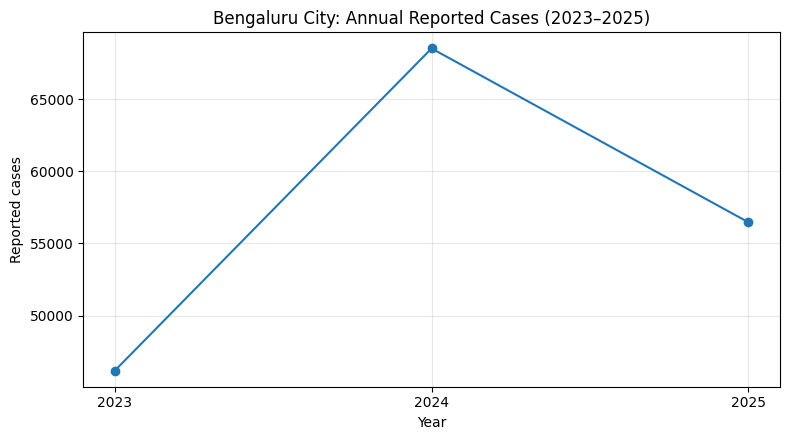

Scope: annual city-level reported counts. This graph is descriptive, not a crime-risk prediction.


In [ ]:

import matplotlib.pyplot as plt

plot_df = city_df.sort_values("year")

plt.figure(figsize=(8, 4.5))
plt.plot(
    plot_df["year"],
    plot_df["total_reported_cases"],
    marker="o"
)

plt.title("Bengaluru City: Annual Reported Cases (2023–2025)")
plt.xlabel("Year")
plt.ylabel("Reported cases")
plt.xticks(plot_df["year"])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(
    "Scope: annual city-level reported counts. "
    "This graph is descriptive, not a crime-risk prediction."
)


In [ ]:

import pandas as pd

crime_path = (
    "/content/she_guard_data/"
    "she_guard_geodata_nextstep/"
    "bengaluru_crime_type_annual_counts_2021_2023_clean.csv"
)

crime_categories = pd.read_csv(crime_path)

print("Dataset shape:", crime_categories.shape)
print("\nColumns:")
for col in crime_categories.columns:
    print("-", col)

location_fields = [
    col for col in crime_categories.columns
    if any(word in col.lower() for word in [
        "area", "zone", "station", "latitude", "longitude",
        "location", "district", "date", "month", "time"
    ])
]

print("\nPotential geographic/time columns:", location_fields)
display(crime_categories.head(5))

print(
    "\nReminder: category-wise annual counts alone cannot support "
    "street-level crime-risk prediction."
)


Dataset shape: (12, 7)

Columns:
- Type of Crime
- 2021 Reported
- 2021 Detected
- 2022 Reported
- 2022 Detected
- 2023 Reported
- 2023 Detected

Potential geographic/time columns: []


,Type of Crime,2021 Reported,2021 Detected,2022 Reported,2022 Detected,2023 Reported,2023 Detected
0,Murder,145,143,156,156,205,200
1,Murder (Gain),8,8,17,17,2,2
2,Dacoity,35,35,23,23,36,34
3,Robbery,364,317,478,414,673,437
4,Chain Snatching,166,166,151,139,153,114



Reminder: category-wise annual counts alone cannot support street-level crime-risk prediction.


In [ ]:

import os
import pandas as pd

roots = [
    "/content/she_guard_final_audit",
    "/content/she_guard_data"
]

keywords = [
    "station", "area", "zone", "latitude", "longitude",
    "location", "district", "month", "date", "incident"
]

found = []

for root in roots:
    if not os.path.exists(root):
        continue

    for folder, dirs, files in os.walk(root):
        dirs[:] = [
            d for d in dirs
            if d not in {"node_modules", ".git"}
        ]

        for filename in files:
            if not filename.lower().endswith(".csv"):
                continue

            path = os.path.join(folder, filename)

            try:
                columns = pd.read_csv(path, nrows=0).columns.tolist()
                matching = [
                    col for col in columns
                    if any(word in col.lower() for word in keywords)
                ]

                found.append({
                    "file": filename,
                    "matching_columns": ", ".join(matching) or "None",
                    "all_columns": ", ".join(map(str, columns))
                })
            except Exception as e:
                found.append({
                    "file": filename,
                    "matching_columns": "Could not read",
                    "all_columns": str(e)
                })

audit = pd.DataFrame(found)

print("CSV files scanned:", len(audit))
display(audit)


CSV files scanned: 17


,file,matching_columns,all_columns
0,district_crime_totals_2023_2025.csv,district_or_unit,"year, district_or_unit, ipc_or_bns_cases, sll_..."
1,bengaluru_name_match_rows_for_manual_review.csv,district_or_unit,"year, district_or_unit, ipc_or_bns_cases, sll_..."
2,uploaded_file_inventory.csv,None,"filename, size_bytes, sha256, duplicate_conten..."
3,e8a7c66c-42d7-4436-936b-f55bfb157319.csv,None,"Sl No, Heads of Crime, 2024"
4,604a3fc2-e44a-45ce-ab25-3348322bd041.csv,None,"Type of Crime, 2021 Reported, 2021 Detected, 2..."
5,ka-ipc-crimes-2025.csv,None,"Sl. No., Heads of Crime, For 2025"
6,ka-district-wise-2025.csv,Districts/Units,"Sl No, Districts/Units, IPC/BNS Crimes, SLL Cr..."
7,dc918a6a-75d6-4fb7-bfc4-01e480f655b4.csv,None,"Type of Crime, 2021 Reported, 2021 Detected, 2..."
8,646a37e6-e4a4-4cd7-ae69-ebc37d4fa7e5.csv,Districts,"Districts, IPC Cases, SLL Cases, Total"
9,ffce2bf3-1202-489d-8af5-f156c2e9b793.csv,Districts,"Districts, IPC Cases, SLL Cases, Total"


In [ ]:

import pandas as pd

required_columns = [
    "zone_id",
    "year",
    "month",
    "reported_crime_count",
    "population_or_exposure",
    "source"
]

schema = pd.DataFrame({
    "column": required_columns,
    "purpose": [
        "Broader geographic zone identifier",
        "Calendar year",
        "Calendar month",
        "Verified reported incidents for that zone and month",
        "Optional denominator to help compare zones fairly",
        "Traceable data source"
    ],
    "available_in_current_data": [
        "No matching crime-zone linkage",
        "Yes, annual year only",
        "No",
        "No, only aggregate totals/categories",
        "No",
        "Partially, source filenames exist"
    ]
})

display(schema)

print(
    "\nML readiness: NOT READY for genuine zone-level training."
)
print(
    "Next requirement: verified crime records/counts linked to "
    "consistent geographic zones and time periods."
)


,column,purpose,available_in_current_data
0,zone_id,Broader geographic zone identifier,No matching crime-zone linkage
1,year,Calendar year,"Yes, annual year only"
2,month,Calendar month,No
3,reported_crime_count,Verified reported incidents for that zone and ...,"No, only aggregate totals/categories"
4,population_or_exposure,Optional denominator to help compare zones fairly,No
5,source,Traceable data source,"Partially, source filenames exist"



ML readiness: NOT READY for genuine zone-level training.
Next requirement: verified crime records/counts linked to consistent geographic zones and time periods.


In [ ]:

import pandas as pd

REQUIRED_COLUMNS = [
    "zone_id",
    "year",
    "month",
    "reported_crime_count"
]

def validate_ml_dataset(data):
    missing_columns = [
        col for col in REQUIRED_COLUMNS
        if col not in data.columns
    ]

    if missing_columns:
        return {
            "ready": False,
            "reason": "Required columns are missing.",
            "missing_columns": missing_columns
        }

    clean = data[REQUIRED_COLUMNS].copy()

    if clean.isna().any().any():
        return {
            "ready": False,
            "reason": "Missing values exist in required fields."
        }

    if not clean["month"].between(1, 12).all():
        return {
            "ready": False,
            "reason": "Month values must be between 1 and 12."
        }

    if (clean["reported_crime_count"] < 0).any():
        return {
            "ready": False,
            "reason": "Crime counts cannot be negative."
        }

    if clean.duplicated(["zone_id", "year", "month"]).any():
        return {
            "ready": False,
            "reason": "Duplicate zone-year-month records exist."
        }

    if len(clean) < 24:
        return {
            "ready": False,
            "reason": "Too few observations for a meaningful baseline."
        }

    return {
        "ready": True,
        "reason": "Basic checks passed; model evaluation is still required."
    }


# Test against the real dataset currently available.
readiness = validate_ml_dataset(df)

print("ML dataset readiness:")
print(readiness)


ML dataset readiness:
{'ready': False, 'reason': 'Required columns are missing.', 'missing_columns': ['zone_id', 'month', 'reported_crime_count']}


In [ ]:

def predict_zone_risk(zone_id, model=None, features=None):
    """
    Interface for future zone-level ML inference.

    No model or verified zone features means no prediction.
    """

    if model is None:
        return {
            "zone_id": zone_id,
            "risk_score": None,
            "risk_level": "UNAVAILABLE",
            "data_mode": "no_trained_model",
            "message": "A trained and validated model is not connected."
        }

    if features is None:
        raise ValueError(
            "Features are required when using a trained model."
        )

    prediction = model.predict(features)

    return {
        "zone_id": zone_id,
        "prediction": prediction.tolist(),
        "data_mode": "model_output",
        "message": (
            "Model output only; map it to a calibrated risk level "
            "after validation."
        )
    }


# Example test using a generic zone ID
test_prediction = predict_zone_risk("ZONE_1298_7759")

print(test_prediction)


{'zone_id': 'ZONE_1298_7759', 'risk_score': None, 'risk_level': 'UNAVAILABLE', 'data_mode': 'no_trained_model', 'message': 'A trained and validated model is not connected.'}


In [ ]:

def prepare_training_data(data):
    required = [
        "zone_id",
        "year",
        "month",
        "reported_crime_count"
    ]

    missing = [col for col in required if col not in data.columns]

    if missing:
        return None, {
            "ready": False,
            "reason": "Required columns missing",
            "missing_columns": missing
        }

    clean = data[required].copy()

    for col in ["year", "month", "reported_crime_count"]:
        clean[col] = pd.to_numeric(clean[col], errors="coerce")

    if clean.isna().any().any():
        return None, {
            "ready": False,
            "reason": "Missing or non-numeric required values"
        }

    if not clean["month"].between(1, 12).all():
        return None, {
            "ready": False,
            "reason": "Month must be between 1 and 12"
        }

    if (clean["reported_crime_count"] < 0).any():
        return None, {
            "ready": False,
            "reason": "Crime counts cannot be negative"
        }

    if clean.duplicated(["zone_id", "year", "month"]).any():
        return None, {
            "ready": False,
            "reason": "Duplicate zone-year-month records"
        }

    if len(clean) < 24:
        return None, {
            "ready": False,
            "reason": "Insufficient observations for baseline training"
        }

    return clean, {
        "ready": True,
        "reason": "Basic checks passed; temporal evaluation still required"
    }


# Check current real dataset — it should be rejected for zone-level training
prepared_data, report = prepare_training_data(df)

print(report)


{'ready': False, 'reason': 'Required columns missing', 'missing_columns': ['zone_id', 'month', 'reported_crime_count']}


In [ ]:

# SHE-GUARD prototype risk engine
# IMPORTANT: All risk values below are simulated for demonstration.

DEMO_ZONE_RISKS = {
    "ZONE_1298_7759": {
        "risk_score": 65,
        "risk_level": "ELEVATED",
        "data_mode": "simulated_demo"
    },
    "ZONE_1297_7758": {
        "risk_score": 30,
        "risk_level": "MODERATE",
        "data_mode": "simulated_demo"
    },
    "ZONE_1295_7762": {
        "risk_score": 45,
        "risk_level": "MODERATE",
        "data_mode": "simulated_demo"
    }
}

def get_demo_zone_risk(zone_id):
    result = DEMO_ZONE_RISKS.get(zone_id)

    if result is None:
        return {
            "zone_id": zone_id,
            "risk_score": None,
            "risk_level": "UNAVAILABLE",
            "data_mode": "unavailable",
            "message": "No risk data available for this zone."
        }

    return {
        "zone_id": zone_id,
        **result,
        "message": (
            "SIMULATED DEMO ONLY — not a real crime-risk prediction."
        )
    }


# Test the demo engine
print(get_demo_zone_risk("ZONE_1298_7759"))
print()
print(get_demo_zone_risk("ZONE_9999_9999"))


{'zone_id': 'ZONE_1298_7759', 'risk_score': 65, 'risk_level': 'ELEVATED', 'data_mode': 'simulated_demo', 'message': 'SIMULATED DEMO ONLY — not a real crime-risk prediction.'}

{'zone_id': 'ZONE_9999_9999', 'risk_score': None, 'risk_level': 'UNAVAILABLE', 'data_mode': 'unavailable', 'message': 'No risk data available for this zone.'}


In [ ]:

from pathlib import Path

app_path = Path("app.py")
source = app_path.read_text()

if '@app.get("/demo-risk/{zone_id}")' in source:
    print("Demo risk endpoint already exists.")
else:
    addition = '''

DEMO_ZONE_RISKS = {
    "ZONE_1298_7759": {
        "risk_score": 65,
        "risk_level": "ELEVATED",
        "data_mode": "simulated_demo"
    },
    "ZONE_1297_7758": {
        "risk_score": 30,
        "risk_level": "MODERATE",
        "data_mode": "simulated_demo"
    },
    "ZONE_1295_7762": {
        "risk_score": 45,
        "risk_level": "MODERATE",
        "data_mode": "simulated_demo"
    }
}

@app.get("/demo-risk/{zone_id}")
def get_demo_risk(zone_id: str):
    result = DEMO_ZONE_RISKS.get(zone_id)

    if result is None:
        return {
            "zone_id": zone_id,
            "risk_score": None,
            "risk_level": "UNAVAILABLE",
            "data_mode": "unavailable",
            "message": "No risk data available for this zone."
        }

    return {
        "zone_id": zone_id,
        **result,
        "message": (
            "SIMULATED DEMO ONLY — not a real crime-risk prediction."
        )
    }
'''

    with app_path.open("a", encoding="utf-8") as f:
        f.write(addition)

    print("Demo risk endpoint added to app.py.")

print("\nFile exists:", app_path.exists())
print("Endpoint path: GET /demo-risk/{zone_id}")


Demo risk endpoint added to app.py.

File exists: True
Endpoint path: GET /demo-risk/{zone_id}


In [ ]:

import subprocess
import requests
import time

# Stop the previous server if it is still running
if "server_process" in globals() and server_process.poll() is None:
    server_process.terminate()
    try:
        server_process.wait(timeout=5)
    except subprocess.TimeoutExpired:
        server_process.kill()
        server_process.wait()

# Start server with the updated app.py
server_log = open("/tmp/she_guard_api.log", "w")

server_process = subprocess.Popen(
    [
        "python", "-m", "uvicorn",
        "app:app",
        "--host", "127.0.0.1",
        "--port", "8000"
    ],
    stdout=server_log,
    stderr=subprocess.STDOUT
)

for attempt in range(20):
    if server_process.poll() is not None:
        print("❌ Server stopped.")
        print(open("/tmp/she_guard_api.log").read())
        break

    try:
        r = requests.get("http://127.0.0.1:8000/", timeout=2)
        if r.status_code == 200:
            print("✅ Updated SHE-GUARD API is running.")
            print("Health check:", r.json())
            break
    except requests.RequestException:
        time.sleep(1)
else:
    print("❌ Server did not respond.")
    print(open("/tmp/she_guard_api.log").read())


✅ Updated SHE-GUARD API is running.
Health check: {'system': 'SHE-GUARD', 'status': 'API_READY', 'risk_assessment': 'UNAVAILABLE'}


In [ ]:

import requests

base_url = "http://127.0.0.1:8000"

# Test 1: Known simulated zone
known_zone = requests.get(
    f"{base_url}/demo-risk/ZONE_1298_7759",
    timeout=10
)

print("TEST 1 — Known demo zone")
print("HTTP status:", known_zone.status_code)
print(known_zone.json())

# Test 2: Unknown zone
unknown_zone = requests.get(
    f"{base_url}/demo-risk/ZONE_9999_9999",
    timeout=10
)

print("\nTEST 2 — Unknown zone")
print("HTTP status:", unknown_zone.status_code)
print(unknown_zone.json())


TEST 1 — Known demo zone
HTTP status: 200
{'zone_id': 'ZONE_1298_7759', 'risk_score': 65, 'risk_level': 'ELEVATED', 'data_mode': 'simulated_demo', 'message': 'SIMULATED DEMO ONLY — not a real crime-risk prediction.'}

TEST 2 — Unknown zone
HTTP status: 200
{'zone_id': 'ZONE_9999_9999', 'risk_score': None, 'risk_level': 'UNAVAILABLE', 'data_mode': 'unavailable', 'message': 'No risk data available for this zone.'}


In [ ]:

from pathlib import Path

app_path = Path("app.py")
source = app_path.read_text()

if '@app.post("/assess-route")' in source:
    print("Endpoint already exists in app.py.")
else:
    addition = '''

class AssessRouteRequest(RouteRequest):
    zone_ids: list[str] = Field(default_factory=list, max_length=20)

@app.post("/assess-route")
def assess_route_request(request: AssessRouteRequest):
    route_request = RouteRequest(
        start_latitude=request.start_latitude,
        start_longitude=request.start_longitude,
        destination_latitude=request.destination_latitude,
        destination_longitude=request.destination_longitude
    )

    route_response = get_routes(route_request)

    zone_results = [
        get_demo_risk(zone_id)
        for zone_id in request.zone_ids
    ]

    return {
        "system": "SHE-GUARD",
        "status": "ROUTES_GENERATED",
        "risk_assessment": "SIMULATED_OR_UNAVAILABLE",
        "message": (
            "Zone risks are demo-only or unavailable. "
            "No real safe-route recommendation is made."
        ),
        "route_data": route_response,
        "zone_assessments": zone_results
    }
'''

    # The helper function below is added to avoid relying on FastAPI
    # route-function wrappers for the demo-risk lookup.
    helper = '''

def get_demo_risk(zone_id: str):
    result = DEMO_ZONE_RISKS.get(zone_id)

    if result is None:
        return {
            "zone_id": zone_id,
            "risk_score": None,
            "risk_level": "UNAVAILABLE",
            "data_mode": "unavailable",
            "message": "No risk data available for this zone."
        }

    return {
        "zone_id": zone_id,
        **result,
        "message": (
            "SIMULATED DEMO ONLY — not a real crime-risk prediction."
        )
    }
'''

    # Insert helper before the endpoint addition.
    with app_path.open("a", encoding="utf-8") as f:
        f.write(helper)
        f.write(addition)

    print("Added POST /assess-route")

print("File exists:", app_path.exists())


Added POST /assess-route
File exists: True


In [ ]:
import subprocess
import requests
import time

# Stop the previous server, if running
try:
    server_process.terminate()
    server_process.wait(timeout=5)
except Exception:
    pass

# Start the updated API
server_log = open("/tmp/she_guard_api.log", "w")

server_process = subprocess.Popen(
    ["python", "-m", "uvicorn", "app:app",
     "--host", "127.0.0.1", "--port", "8000"],
    stdout=server_log,
    stderr=subprocess.STDOUT
)

time.sleep(3)

# Health check
response = requests.get("http://127.0.0.1:8000/", timeout=10)

print("HTTP Status:", response.status_code)
print("API Response:", response.json())

HTTP Status: 200
API Response: {'system': 'SHE-GUARD', 'status': 'API_READY', 'risk_assessment': 'UNAVAILABLE'}


In [ ]:
import requests
import json

url = "http://127.0.0.1:8000/assess-route"

payload = {
    "start_latitude": 12.9716,
    "start_longitude": 77.5946,
    "destination_latitude": 12.9352,
    "destination_longitude": 77.6245,
    "zone_ids": [
        "ZONE_1298_7759",
        "ZONE_1297_7758",
        "ZONE_9999_9999"
    ]
}

response = requests.post(url, json=payload, timeout=30)

print("HTTP Status:", response.status_code)
print(json.dumps(response.json(), indent=2))

HTTP Status: 200
{
  "system": "SHE-GUARD",
  "status": "ROUTES_GENERATED",
  "risk_assessment": "SIMULATED_OR_UNAVAILABLE",
  "message": "Zone risks are demo-only or unavailable. No real safe-route recommendation is made.",
  "route_data": {
    "system": "SHE-GUARD",
    "status": "ROUTES_GENERATED",
    "risk_assessment": "UNAVAILABLE",
    "message": "Routes generated, but verified crime-risk data is not connected. No route is labelled safe or unsafe.",
    "routes": [
      {
        "route_id": "R1",
        "distance_km": 7.5,
        "duration_min": 12.3,
        "risk_score": null,
        "risk_status": "No verified risk data",
        "data_mode": "unavailable"
      },
      {
        "route_id": "R2",
        "distance_km": 8.69,
        "duration_min": 12.3,
        "risk_score": null,
        "risk_status": "No verified risk data",
        "data_mode": "unavailable"
      }
    ]
  },
  "zone_assessments": [
    {
      "zone_id": "ZONE_1298_7759",
      "risk_score": 65

In [ ]:
import requests

response = requests.get(
    "http://127.0.0.1:8000/openapi.json",
    timeout=10
)

print("HTTP Status:", response.status_code)

api_spec = response.json()

print("\nAPI Title:", api_spec["info"]["title"])
print("\nAvailable endpoints:")

for path, methods in api_spec["paths"].items():
    for method in methods:
        print(method.upper(), path)

HTTP Status: 200

API Title: SHE-GUARD API

Available endpoints:
GET /
POST /routes
GET /demo-risk/{zone_id}
POST /assess-route


In [ ]:
import os
import pandas as pd

print("========== SHE-GUARD ML CHECK ==========")

# 1. Check existing dataset and functions
for name in ["df", "validate_ml_dataset", "prepare_training_data"]:
    print(f"{name}: {'AVAILABLE' if name in globals() else 'NOT AVAILABLE'}")

# 2. Check whether the consolidated dataframe is usable
if "df" in globals() and isinstance(df, pd.DataFrame):
    print("\nDataset shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head(5))
else:
    print("\nConsolidated dataframe not currently loaded.")

# 3. Check whether crime CSV files still exist
crime_files = []

for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in [".git", "__pycache__"]]
    for filename in files:
        if filename.lower().endswith(".csv") and any(
            word in filename.lower()
            for word in ["crime", "district", "station", "audit"]
        ):
            crime_files.append(os.path.join(root, filename))

print("\nCrime-related CSV files found:", len(crime_files))
for path in crime_files[:20]:
    print(path)

========== SHE-GUARD ML CHECK ==========
df: AVAILABLE
validate_ml_dataset: AVAILABLE
prepare_training_data: AVAILABLE

Dataset shape: (124, 7)
Columns: ['year', 'district_or_unit', 'ipc_or_bns_cases', 'sll_cases', 'total_reported_cases', 'geographic_level', 'source_file']


,year,district_or_unit,ipc_or_bns_cases,sll_cases,total_reported_cases,geographic_level,source_file
0,2023,Bagalkot,2199.0,735.0,2934.0,district_or_unit_aggregate,646a37e6-e4a4-4cd7-ae69-ebc37d4fa7e5.csv
1,2023,Bengaluru City,28666.0,17521.0,46187.0,district_or_unit_aggregate,646a37e6-e4a4-4cd7-ae69-ebc37d4fa7e5.csv
2,2023,Bengaluru District,6031.0,961.0,6992.0,district_or_unit_aggregate,646a37e6-e4a4-4cd7-ae69-ebc37d4fa7e5.csv
3,2023,Belagavi District,4703.0,1324.0,6027.0,district_or_unit_aggregate,646a37e6-e4a4-4cd7-ae69-ebc37d4fa7e5.csv
4,2023,Ballari,1792.0,1434.0,3226.0,district_or_unit_aggregate,646a37e6-e4a4-4cd7-ae69-ebc37d4fa7e5.csv



Crime-related CSV files found: 8
/content/she_guard_final_audit/SHE_GUARD_Data_Audit/district_crime_totals_2023_2025.csv
/content/she_guard_final_audit/SHE_GUARD_Data_Audit/source_csvs/ka-ipc-crimes-2025.csv
/content/she_guard_final_audit/SHE_GUARD_Data_Audit/source_csvs/ka-district-wise-2025.csv
/content/she_guard_final_audit/SHE_GUARD_Data_Audit/source_csvs/ka-sll-crimes-2025.csv
/content/she_guard_data/she_guard_geodata_nextstep/bengaluru_candidate_police_station_locations.csv
/content/she_guard_data/she_guard_geodata_nextstep/bengaluru_crime_type_annual_counts_long.csv
/content/she_guard_data/she_guard_geodata_nextstep/bengaluru_crime_type_annual_counts_2021_2023_clean.csv
/content/she_guard_data/she_guard_geodata_nextstep/karnataka_police_station_locations.csv


In [ ]:
import pandas as pd

print("========== DATASET SUITABILITY ==========")

# 1. Missing values
print("\nMissing values:")
print(df.isnull().sum())

# 2. Available years and geographic units
print("\nYears available:")
print(sorted(df["year"].dropna().unique()))

print("\nGeographic levels:")
print(df["geographic_level"].value_counts(dropna=False))

print("\nUnique districts/units:", df["district_or_unit"].nunique())

# 3. Crime-count summary
print("\nCrime count summary:")
display(
    df[[
        "ipc_or_bns_cases",
        "sll_cases",
        "total_reported_cases"
    ]].describe().round(2)
)

# 4. Check whether location and time are detailed enough
required_for_zone_model = {
    "latitude", "longitude", "month", "reported_crime_count"
}

missing_columns = required_for_zone_model - set(df.columns)

print("\nMissing fields for GPS-zone/time model:")
print(sorted(missing_columns))

if missing_columns:
    print(
        "\nRESULT: Current dataframe is not sufficient "
        "for genuine GPS-zone crime-risk training."
    )
else:
    print("\nRESULT: Required fields are present; validate them next.")

========== DATASET SUITABILITY ==========

Missing values:
year                    0
district_or_unit        0
ipc_or_bns_cases        7
sll_cases               7
total_reported_cases    7
geographic_level        0
source_file             0
dtype: int64

Years available:
[np.int64(2023), np.int64(2024), np.int64(2025)]

Geographic levels:
geographic_level
district_or_unit_aggregate    124
Name: count, dtype: int64

Unique districts/units: 64

Crime count summary:


,ipc_or_bns_cases,sll_cases,total_reported_cases
count,117.00,117.00,117.00
mean,7124.36,3089.47,10213.83
std,22199.98,9932.35,32078.55
min,662.00,57.00,800.00
25%,1812.00,717.00,2740.00
50%,2460.00,1093.00,3495.00
75%,4155.00,1403.00,5403.00
max,148648.00,65586.00,214234.00



Missing fields for GPS-zone/time model:
['latitude', 'longitude', 'month', 'reported_crime_count']

RESULT: Current dataframe is not sufficient for genuine GPS-zone crime-risk training.


In [ ]:
import pandas as pd
import numpy as np

# Work on a copy; original df remains unchanged
crime_df = df.copy()

# Convert numeric columns safely
numeric_cols = [
    "year",
    "ipc_or_bns_cases",
    "sll_cases",
    "total_reported_cases"
]

for col in numeric_cols:
    crime_df[col] = pd.to_numeric(crime_df[col], errors="coerce")

# Remove rows where the target crime count is missing
before_rows = len(crime_df)

crime_df = crime_df.dropna(
    subset=["year", "district_or_unit", "total_reported_cases"]
).copy()

# Keep whole-number counts
crime_df["year"] = crime_df["year"].astype(int)
crime_df["total_reported_cases"] = (
    crime_df["total_reported_cases"].round().astype(int)
)

# Verify uniqueness of year + geographic unit
duplicate_rows = crime_df.duplicated(
    subset=["year", "district_or_unit"]
).sum()

print("Original rows:", before_rows)
print("Rows after cleaning:", len(crime_df))
print("Rows removed:", before_rows - len(crime_df))
print("Duplicate year-unit pairs:", duplicate_rows)

print("\nRows per year:")
print(crime_df.groupby("year").size())

print("\nCleaned dataset preview:")
display(
    crime_df[
        ["year", "district_or_unit", "total_reported_cases"]
    ].head(10)
)

print("\nTarget summary:")
print(crime_df["total_reported_cases"].describe().round(2))

Original rows: 124
Rows after cleaning: 117
Rows removed: 7
Duplicate year-unit pairs: 0

Rows per year:
year
2023    39
2024    39
2025    39
dtype: int64

Cleaned dataset preview:


,year,district_or_unit,total_reported_cases
0,2023,Bagalkot,2934
1,2023,Bengaluru City,46187
2,2023,Bengaluru District,6992
3,2023,Belagavi District,6027
4,2023,Ballari,3226
5,2023,Bidar,4022
6,2023,Vijayapura,4296
7,2023,Chikkaballapura,4320
8,2023,Chamarajnagar,2373
9,2023,Chikkamagaluru,3855



Target summary:
count       117.00
mean      10213.83
std       32078.55
min         800.00
25%        2740.00
50%        3495.00
75%        5403.00
max      214234.00
Name: total_reported_cases, dtype: float64


In [ ]:
# Check which geographic units appear in each year
units_by_year = {
    year: set(group["district_or_unit"])
    for year, group in crime_df.groupby("year")
}

years = sorted(units_by_year)

print("========== YEAR-WISE GEOGRAPHIC CHECK ==========")

for year in years:
    print(f"{year}: {len(units_by_year[year])} units")

common_units = set.intersection(
    *(units_by_year[year] for year in years)
)

print("\nUnits present in ALL years:", len(common_units))

for year in years[1:]:
    previous_year = year - 1
    if previous_year in units_by_year:
        added = units_by_year[year] - units_by_year[previous_year]
        removed = units_by_year[previous_year] - units_by_year[year]

        print(f"\n{previous_year} -> {year}")
        print("New units:", sorted(added))
        print("Missing units:", sorted(removed))

# Compare Bengaluru City only, if available
print("\n========== BENGALURU CITY TREND ==========")

blr = crime_df[
    crime_df["district_or_unit"].str.strip().str.lower()
    == "bengaluru city"
].sort_values("year")

display(blr[["year", "district_or_unit", "total_reported_cases"]])

if len(blr) > 1:
    blr = blr.copy()
    blr["yearly_change_pct"] = (
        blr["total_reported_cases"].pct_change() * 100
    ).round(2)
    display(blr[["year", "total_reported_cases", "yearly_change_pct"]])

========== YEAR-WISE GEOGRAPHIC CHECK ==========
2023: 39 units
2024: 39 units
2025: 39 units

Units present in ALL years: 24

2023 -> 2024
New units: ['Hubballi Dharwad City', 'KGF', 'KRailways', 'TOTAL']
Missing units: ['Hubballi Dharwad', 'K.G.F.', 'K.Railways', 'Total Districts']

2024 -> 2025
New units: ['Belagavi Dist', 'Bengaluru Dist', 'Bengaluru South', 'Chamarajanagar', 'Chickballapura', 'K.G.F', 'Kalaburagi', 'Kalaburagi City', 'Karnataka Railways', 'Mysuru Dist', 'STATE', 'Shivamogga', 'Vijayapur', 'Yadgir']
Missing units: ['Belagavi District', 'Bengaluru District', 'Chamarajnagar', 'Chikkaballapura', 'KGF', 'KRailways', 'Kalaburgi', 'Kalaburgi City', 'Mysuru District', 'Ramanagara', 'Shimoga', 'TOTAL', 'Vijayapura', 'Yadgiri']

========== BENGALURU CITY TREND ==========


,year,district_or_unit,total_reported_cases
1,2023,Bengaluru City,46187
40,2024,Bengaluru City,68520
78,2025,Bengaluru City,56472


,year,total_reported_cases,yearly_change_pct
1,2023,46187,NaN
40,2024,68520,48.35
78,2025,56472,-17.58


In [ ]:

import os
import pandas as pd

search_root = "/content"
csv_files = []

for root, dirs, files in os.walk(search_root):
    dirs[:] = [
        d for d in dirs
        if d not in [".git", "__pycache__"]
    ]

    for filename in files:
        if filename.lower().endswith(".csv"):
            csv_files.append(os.path.join(root, filename))

print("CSV files found:", len(csv_files))

for path in csv_files:
    try:
        sample = pd.read_csv(path, nrows=5)
        columns = [str(c).strip().lower() for c in sample.columns]

        location_fields = [
            c for c in columns
            if any(k in c for k in [
                "latitude", "longitude", "lat", "lon",
                "coordinate", "location", "area", "ward",
                "police station"
            ])
        ]

        time_fields = [
            c for c in columns
            if any(k in c for k in [
                "date", "time", "month", "year", "timestamp"
            ])
        ]

        crime_fields = [
            c for c in columns
            if any(k in c for k in [
                "crime", "offence", "offense", "incident",
                "category", "reported", "cases"
            ])
        ]

        print("\n" + "=" * 60)
        print("FILE:", path)
        print("COLUMNS:", sample.columns.tolist())
        print("LOCATION FIELDS:", location_fields)
        print("TIME FIELDS:", time_fields)
        print("CRIME FIELDS:", crime_fields)

    except Exception as e:
        print("\nCould not inspect:", path)
        print("Reason:", str(e)[:150])


CSV files found: 21

FILE: /content/she_guard_final_audit/SHE_GUARD_Data_Audit/district_crime_totals_2023_2025.csv
COLUMNS: ['year', 'district_or_unit', 'ipc_or_bns_cases', 'sll_cases', 'total_reported_cases', 'geographic_level', 'source_file']
LOCATION FIELDS: []
TIME FIELDS: ['year']
CRIME FIELDS: ['ipc_or_bns_cases', 'sll_cases', 'total_reported_cases']

FILE: /content/she_guard_final_audit/SHE_GUARD_Data_Audit/bengaluru_name_match_rows_for_manual_review.csv
COLUMNS: ['year', 'district_or_unit', 'ipc_or_bns_cases', 'sll_cases', 'total_reported_cases', 'geographic_level', 'source_file']
LOCATION FIELDS: []
TIME FIELDS: ['year']
CRIME FIELDS: ['ipc_or_bns_cases', 'sll_cases', 'total_reported_cases']

FILE: /content/she_guard_final_audit/SHE_GUARD_Data_Audit/uploaded_file_inventory.csv
COLUMNS: ['filename', 'size_bytes', 'sha256', 'duplicate_content', 'duplicate_of', 'type']
LOCATION FIELDS: []
TIME FIELDS: []
CRIME FIELDS: []

FILE: /content/she_guard_final_audit/SHE_GUARD_Data_Audit/

In [ ]:
import os

print("========== SHE-GUARD FILE SEARCH ==========")

for base in ["/content/she_guard_final_audit", "/content/she_guard_data"]:
    print(f"\nFolder: {base}")
    if not os.path.exists(base):
        print("NOT FOUND")
        continue

    for root, dirs, files in os.walk(base):
        for filename in files:
            if filename.lower().endswith((".csv", ".kml", ".zip")):
                print(os.path.join(root, filename))

========== SHE-GUARD FILE SEARCH ==========

Folder: /content/she_guard_final_audit
/content/she_guard_final_audit/SHE_GUARD_Data_Audit/district_crime_totals_2023_2025.csv
/content/she_guard_final_audit/SHE_GUARD_Data_Audit/bengaluru_name_match_rows_for_manual_review.csv
/content/she_guard_final_audit/SHE_GUARD_Data_Audit/uploaded_file_inventory.csv
/content/she_guard_final_audit/SHE_GUARD_Data_Audit/source_csvs/e8a7c66c-42d7-4436-936b-f55bfb157319.csv
/content/she_guard_final_audit/SHE_GUARD_Data_Audit/source_csvs/604a3fc2-e44a-45ce-ab25-3348322bd041.csv
/content/she_guard_final_audit/SHE_GUARD_Data_Audit/source_csvs/ka-ipc-crimes-2025.csv
/content/she_guard_final_audit/SHE_GUARD_Data_Audit/source_csvs/ka-district-wise-2025.csv
/content/she_guard_final_audit/SHE_GUARD_Data_Audit/source_csvs/dc918a6a-75d6-4fb7-bfc4-01e480f655b4.csv
/content/she_guard_final_audit/SHE_GUARD_Data_Audit/source_csvs/646a37e6-e4a4-4cd7-ae69-ebc37d4fa7e5.csv
/content/she_guard_final_audit/SHE_GUARD_Data_Audit

In [ ]:
import os
import pandas as pd

folders = [
    "/content/she_guard_final_audit/SHE_GUARD_Data_Audit/source_csvs",
    "/content/she_guard_data/she_guard_geodata_nextstep"
]

for folder in folders:
    if not os.path.exists(folder):
        continue

    for filename in sorted(os.listdir(folder)):
        if not filename.lower().endswith(".csv"):
            continue

        path = os.path.join(folder, filename)

        try:
            sample = pd.read_csv(path, nrows=3)
            print("\n" + "=" * 65)
            print("FILE:", filename)
            print("SHAPE SAMPLE:", sample.shape)
            print("COLUMNS:", sample.columns.tolist())
            display(sample.head(2))
        except Exception as e:
            print("Could not read:", filename, "|", str(e)[:120])


FILE: 604a3fc2-e44a-45ce-ab25-3348322bd041.csv
SHAPE SAMPLE: (3, 7)
COLUMNS: ['Type of Crime', '2021 Reported', '2021 Detected', '2022 Reported', '2022 Detected', '2023 Reported', '2023 Detected']


,Type of Crime,2021 Reported,2021 Detected,2022 Reported,2022 Detected,2023 Reported,2023 Detected
0,Murder,145,143,156,156,205,200
1,Murder (Gain),8,8,17,17,2,2



FILE: 646a37e6-e4a4-4cd7-ae69-ebc37d4fa7e5.csv
SHAPE SAMPLE: (3, 4)
COLUMNS: ['Districts', 'IPC Cases', 'SLL Cases', 'Total']


,Districts,IPC Cases,SLL Cases,Total
0,Bagalkot,2199,735,2934
1,Bengaluru City,28666,17521,46187



FILE: 91595449-b2cf-4653-ad7d-11f37d2b50f4.csv
SHAPE SAMPLE: (3, 37)
COLUMNS: ['Districts', 'Assault on Women with Intent to Outrage her Modesty - Incidents (I)', 'Assault on Women with Intent to Outrage her Modesty - Victims (V)', 'Assault on Women with Intent to Outrage her Modesty - R (Crime Rate)', 'Assault on Women - I', 'Assault on Women - V', 'Assault on Women - R', 'Sexual Harrassment Total - I', 'Sexual Harrassment Total - V', 'Sexual Harrassment Total - R', 'SH At work/premises - I', 'SH At work/premises - V', 'SH At work/premises - R', 'SH in Public transport - I', 'SH in Public transport - V', 'SH in Public transport - R', 'SH in shelter homes for women and children - I', 'SH in shelter homes for women and children - V', 'SH in shelter homes for women and children - R', 'SH in Other places - I', 'SH in Other places - V', 'SH in Other places - R', 'Assault or use of Criminal\nForce on women with intent\nto Disrobe (Sec.354B IPC) - I', 'Assault or use of Criminal\nForce on w

...

,year,crime_type,reported_count,detected_count,source_file,geographic_level
0,2021,Murder,145,143,604a3fc2-e44a-45ce-ab25-3348322bd041.csv,as supplied in source; confirm before use
1,2022,Murder,156,156,604a3fc2-e44a-45ce-ab25-3348322bd041.csv,as supplied in source; confirm before use



FILE: data_dictionary.csv
SHAPE SAMPLE: (3, 4)
COLUMNS: ['file', 'column', 'meaning', 'use']


,file,column,meaning,use
0,karnataka_police_station_locations.csv,POL_STAName,Police station name as supplied by KML,Map/context only; not a crime event
1,karnataka_police_station_locations.csv,"latitude, longitude",Coordinates of police station points,Map/context only; not incident coordinates



FILE: karnataka_police_station_locations.csv
SHAPE SAMPLE: (3, 11)
COLUMNS: ['OBJECTID', 'DepartmentCode', 'KGISVillageID', 'KGISCode', 'KGISPOL_STAID', 'POL_STAName', 'KGISPSCode', 'longitude', 'latitude', 'source_file', 'location_type']


,OBJECTID,DepartmentCode,KGISVillageID,KGISCode,KGISPOL_STAID,POL_STAName,KGISPSCode,longitude,latitude,source_file,location_type
0,1,164450334,5007,29565055008031140000HMPOLPUOFFPOS0001,1,Cowlbazar PS,PS - 01,76.902929,15.137706,9181e6ed-6164-430b-8b10-238ad7b8ab45.kml,police_station_location_not_crime_incident
1,2,164450333,5007,29565055008031140000HMPOLPUOFFPOS0002,2,Bruceept PS,PS - 02,76.926340,15.138191,9181e6ed-6164-430b-8b10-238ad7b8ab45.kml,police_station_location_not_crime_incident


In [ ]:
import pandas as pd

# Separate annual totals for Bengaluru City
blr_annual = (
    crime_df[
        crime_df["district_or_unit"].str.strip().str.lower()
        == "bengaluru city"
    ][["year", "total_reported_cases"]]
    .sort_values("year")
    .drop_duplicates()
    .reset_index(drop=True)
)

# Calculate descriptive year-over-year changes
blr_annual["change_in_cases"] = (
    blr_annual["total_reported_cases"].diff()
)

blr_annual["change_percent"] = (
    blr_annual["total_reported_cases"]
    .pct_change()
    .mul(100)
    .round(2)
)

print("Bengaluru City annual baseline:")
display(blr_annual)

print("\nRows available for this series:", len(blr_annual))
print("Important: this is descriptive analysis, not a trained GPS-risk model.")

Bengaluru City annual baseline:


,year,total_reported_cases,change_in_cases,change_percent
0,2023,46187,NaN,NaN
1,2024,68520,22333.0,48.35
2,2025,56472,-12048.0,-17.58



Rows available for this series: 3
Important: this is descriptive analysis, not a trained GPS-risk model.


In [ ]:

import pandas as pd
from IPython.display import display

url = "https://raw.githubusercontent.com/GokulR-Codes/SafeRoute-AI/main/files/Data/bangalore_crime_dataset.csv"

try:
    candidate_df = pd.read_csv(url)

    print("Dataset loaded successfully")
    print("Shape:", candidate_df.shape)
    print("\nColumns:")
    print(candidate_df.columns.tolist())

    print("\nFirst 5 rows:")
    display(candidate_df.head())

    print("\nMissing values:")
    display(candidate_df.isna().sum().sort_values(ascending=False))

    if {"latitude", "longitude"}.issubset(candidate_df.columns):
        print("\nCoordinate summary:")
        display(candidate_df[["latitude", "longitude"]].describe())

        lat = pd.to_numeric(candidate_df["latitude"], errors="coerce")
        lon = pd.to_numeric(candidate_df["longitude"], errors="coerce")

        valid = (
            lat.between(-90, 90)
            & lon.between(-180, 180)
        )

        print("Valid coordinate rows:", int(valid.sum()))
        print("Invalid/missing coordinate rows:", int((~valid).sum()))

    for col in ["date", "crime_type", "crime_severity", "area"]:
        if col in candidate_df.columns:
            print(f"\n{col} — unique values:", candidate_df[col].nunique())
            if col == "date":
                dates = pd.to_datetime(candidate_df[col], errors="coerce")
                print("Date range:", dates.min(), "to", dates.max())
            else:
                display(candidate_df[col].value_counts().head(10))

except Exception as e:
    print("Dataset inspection failed:", repr(e))


Dataset loaded successfully
Shape: (1500, 13)

Columns:
['latitude', 'longitude', 'crime_type', 'crime_severity', 'date', 'time', 'hour', 'area', 'lighting_score', 'cctv_score', 'crowd_density', 'police_proximity', 'is_night']

First 5 rows:


,latitude,longitude,crime_type,crime_severity,date,time,hour,area,lighting_score,cctv_score,crowd_density,police_proximity,is_night
0,12.947557,77.642527,Chain Snatching,4.7,2023-04-15,17:15,17,Domlur,0.71,0.89,0.18,0.48,0
1,12.940188,77.621612,Theft,4.4,2024-07-28,20:32,20,BTM Layout,0.28,0.65,0.59,0.30,1
2,12.966344,77.561847,Vandalism,3.6,2024-12-15,22:48,22,Majestic,0.48,0.28,0.29,0.79,1
3,12.920129,77.581401,Chain Snatching,6.5,2024-09-10,07:22,7,BTM Layout,0.34,0.04,0.51,0.21,0
4,12.970697,77.620413,Pickpocketing,3.9,2024-01-06,10:53,10,Domlur,0.62,0.70,0.14,0.31,0



Missing values:


,0
latitude,0
longitude,0
crime_type,0
crime_severity,0
date,0
time,0
hour,0
area,0
lighting_score,0
cctv_score,0



Coordinate summary:


...

,count
crime_type,
Pickpocketing,165
Cybercrime,161
Vandalism,160
Theft,154
Drug Offense,154
Chain Snatching,150
Assault,149
Robbery,139
Eve Teasing,135



crime_severity — unique values: 71


,count
crime_severity,
5.0,41
6.0,39
4.7,37
5.9,37
5.2,37
3.5,37
3.2,35
5.8,35
4.6,32



area — unique values: 16


,count
area,
Majestic,184
BTM Layout,146
Chickpet,133
Shivajinagar,116
Bannerghatta Road,111
Marathahalli,100
Koramangala,96
Indiranagar,94
Domlur,90


In [ ]:

# STEP 2: Check whether the dataset is suitable for
# location-based crime hotspot analysis.

print("Dataset shape:", candidate_df.shape)
print("\nColumn names:")
for col in candidate_df.columns:
    print("-", repr(col))

print("\nData types:")
print(candidate_df.dtypes)

print("\nDuplicate rows:", candidate_df.duplicated().sum())

print("\nSample records:")
display(candidate_df.sample(min(5, len(candidate_df)), random_state=42))

# Check likely location, date, and crime-label columns.
print("\nPotential ML input fields:")
for col in candidate_df.columns:
    if any(word in col.lower() for word in [
        "lat", "lon", "long", "date", "time",
        "crime", "type", "severity", "area", "location"
    ]):
        print("-", col)


Dataset shape: (1500, 13)

Column names:
- 'latitude'
- 'longitude'
- 'crime_type'
- 'crime_severity'
- 'date'
- 'time'
- 'hour'
- 'area'
- 'lighting_score'
- 'cctv_score'
- 'crowd_density'
- 'police_proximity'
- 'is_night'

Data types:
latitude            float64
longitude           float64
crime_type           object
crime_severity      float64
date                 object
time                 object
hour                  int64
area                 object
lighting_score      float64
cctv_score          float64
crowd_density       float64
police_proximity    float64
is_night              int64
dtype: object

Duplicate rows: 0

Sample records:


,latitude,longitude,crime_type,crime_severity,date,time,hour,area,lighting_score,cctv_score,crowd_density,police_proximity,is_night
1116,12.956966,77.634638,Drug Offense,5.8,2023-07-21,21:45,21,Domlur,0.49,0.92,0.36,0.13,1
1368,12.958294,77.733864,Vehicle Theft,5.2,2024-08-22,00:07,0,Whitefield,0.95,0.15,0.50,0.71,1
422,12.986376,77.587698,Vandalism,2.6,2023-07-01,03:12,3,Shivajinagar,0.99,0.07,0.97,0.76,1
413,12.970702,77.645803,Assault,5.5,2024-02-27,14:51,14,Indiranagar,0.64,0.89,0.56,0.86,0
451,13.005739,77.692304,Vandalism,2.5,2023-08-17,02:33,2,Random Spread,0.56,0.35,0.88,0.54,1



Potential ML input fields:
- latitude
- longitude
- crime_type
- crime_severity
- date
- time
- area


In [ ]:

# STEP 3: Clean and validate the crime dataset

import pandas as pd

clean_df = candidate_df.copy()

# Normalize column names
clean_df.columns = (
    clean_df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print("Normalized columns:")
print(clean_df.columns.tolist())

# Detect latitude and longitude columns
lat_candidates = [c for c in clean_df.columns if c in ["latitude", "lat"]]
lon_candidates = [c for c in clean_df.columns if c in ["longitude", "lon", "long"]]

if not lat_candidates or not lon_candidates:
    print("\nSTOP: Could not confidently identify latitude/longitude columns.")
    print("Send me the column names above; we will map them correctly.")
else:
    lat_col = lat_candidates[0]
    lon_col = lon_candidates[0]

    clean_df[lat_col] = pd.to_numeric(clean_df[lat_col], errors="coerce")
    clean_df[lon_col] = pd.to_numeric(clean_df[lon_col], errors="coerce")

    before = len(clean_df)

    # Basic coordinate validity
    clean_df = clean_df.dropna(subset=[lat_col, lon_col])
    clean_df = clean_df[
        clean_df[lat_col].between(-90, 90)
        & clean_df[lon_col].between(-180, 180)
    ].copy()

    # Bengaluru bounding-box check; flags likely local records
    bengaluru_mask = (
        clean_df[lat_col].between(12.7, 13.3)
        & clean_df[lon_col].between(77.3, 77.9)
    )

    print("\nRows before coordinate cleaning:", before)
    print("Rows with valid coordinates:", len(clean_df))
    print("Rows inside approximate Bengaluru bounds:", int(bengaluru_mask.sum()))
    print("Rows outside Bengaluru bounds:", int((~bengaluru_mask).sum()))

    print("\nCoordinate sample:")
    display(clean_df[[lat_col, lon_col]].head())

    print("\nImportant: valid coordinates do not prove the crime records are authentic.")


Normalized columns:
['latitude', 'longitude', 'crime_type', 'crime_severity', 'date', 'time', 'hour', 'area', 'lighting_score', 'cctv_score', 'crowd_density', 'police_proximity', 'is_night']

Rows before coordinate cleaning: 1500
Rows with valid coordinates: 1500
Rows inside approximate Bengaluru bounds: 1500
Rows outside Bengaluru bounds: 0

Coordinate sample:


,latitude,longitude
0,12.947557,77.642527
1,12.940188,77.621612
2,12.966344,77.561847
3,12.920129,77.581401
4,12.970697,77.620413



Important: valid coordinates do not prove the crime records are authentic.


In [ ]:

# STEP 4: Crime data quality audit

import pandas as pd

audit_df = clean_df.copy()

# Parse dates and time
audit_df["parsed_date"] = pd.to_datetime(
    audit_df["date"], errors="coerce"
)

print("TOTAL RECORDS:", len(audit_df))
print("EXACT DUPLICATE ROWS:", int(audit_df.duplicated().sum()))
print("INVALID DATES:", int(audit_df["parsed_date"].isna().sum()))

valid_dates = audit_df["parsed_date"].dropna()
if len(valid_dates):
    print("DATE RANGE:", valid_dates.min(), "to", valid_dates.max())

# Inspect target labels
for col in ["crime_type", "crime_severity", "area"]:
    if col in audit_df.columns:
        print(f"\n--- {col.upper()} ---")
        print("Missing:", int(audit_df[col].isna().sum()))
        print("Unique values:", audit_df[col].nunique())
        display(audit_df[col].value_counts(dropna=False).head(20))

# Check whether records are repeated at identical coordinates
print("\nUNIQUE COORDINATE PAIRS:",
      audit_df[["latitude", "longitude"]].drop_duplicates().shape[0])

# Inspect numeric feature ranges
feature_cols = [
    "hour", "lighting_score", "cctv_score",
    "crowd_density", "police_proximity", "is_night"
]
available_cols = [c for c in feature_cols if c in audit_df.columns]

print("\nNUMERIC FEATURE SUMMARY:")
display(audit_df[available_cols].describe().T)

print("\nSAMPLE RECORDS:")
display(audit_df.head(10))


TOTAL RECORDS: 1500
EXACT DUPLICATE ROWS: 0
INVALID DATES: 0
DATE RANGE: 2023-01-01 00:00:00 to 2024-12-31 00:00:00

--- CRIME_TYPE ---
Missing: 0
Unique values: 10


,count
crime_type,
Pickpocketing,165
Cybercrime,161
Vandalism,160
Theft,154
Drug Offense,154
Chain Snatching,150
Assault,149
Robbery,139
Eve Teasing,135



--- CRIME_SEVERITY ---
Missing: 0
Unique values: 71


,count
crime_severity,
5.0,41
6.0,39
4.7,37
5.9,37
5.2,37
3.5,37
3.2,35
5.8,35
4.6,32



--- AREA ---
Missing: 0
Unique values: 16


,count
area,
Majestic,184
BTM Layout,146
Chickpet,133
Shivajinagar,116
Bannerghatta Road,111
Marathahalli,100
Koramangala,96
Indiranagar,94
Domlur,90



UNIQUE COORDINATE PAIRS: 1500

NUMERIC FEATURE SUMMARY:


,count,mean,std,min,25%,50%,75%,max
hour,1500.0,12.590667,8.395998,0.0,3.00,15.00,20.25,23.0
lighting_score,1500.0,0.556660,0.262628,0.1,0.33,0.55,0.79,1.0
cctv_score,1500.0,0.503480,0.289507,0.0,0.24,0.50,0.75,1.0
crowd_density,1500.0,0.543527,0.266136,0.1,0.30,0.55,0.78,1.0
police_proximity,1500.0,0.547940,0.249001,0.1,0.35,0.54,0.75,1.0
is_night,1500.0,0.614000,0.486993,0.0,0.00,1.00,1.00,1.0



SAMPLE RECORDS:


,latitude,longitude,crime_type,crime_severity,date,time,hour,area,lighting_score,cctv_score,crowd_density,police_proximity,is_night,parsed_date
0,12.947557,77.642527,Chain Snatching,4.7,2023-04-15,17:15,17,Domlur,0.71,0.89,0.18,0.48,0,2023-04-15
1,12.940188,77.621612,Theft,4.4,2024-07-28,20:32,20,BTM Layout,0.28,0.65,0.59,0.30,1,2024-07-28
2,12.966344,77.561847,Vandalism,3.6,2024-12-15,22:48,22,Majestic,0.48,0.28,0.29,0.79,1,2024-12-15
3,12.920129,77.581401,Chain Snatching,6.5,2024-09-10,07:22,7,BTM Layout,0.34,0.04,0.51,0.21,0,2024-09-10
4,12.970697,77.620413,Pickpocketing,3.9,2024-01-06,10:53,10,Domlur,0.62,0.70,0.14,0.31,0,2024-01-06
5,12.902880,77.588915,Vehicle Theft,3.3,2023-10-12,07:55,7,BTM Layout,0.51,0.83,0.25,0.42,0,2023-10-12
6,12.925128,77.634064,Vehicle Theft,3.2,2024-10-12,21:41,21,Koramangala,0.25,0.73,0.25,0.44,1,2024-10-12
7,12.949845,77.698986,Drug Offense,7.3,2023-02-27,01:53,1,Marathahalli,0.31,0.03,0.38,0.34,1,2023-02-27
8,12.890296,77.611712,Eve Teasing,5.9,2023-08-06,18:56,18,Bannerghatta Road,0.69,0.40,0.92,0.51,0,2023-08-06
9,12.965969,77.604641,Vehicle Theft,3.8,2024-08-21,01:34,1,Majestic,0.49,0.58,0.43,1.00,1,2024-08-21


In [ ]:

# STEP 5: Inspect patterns before selecting the ML target

import pandas as pd

check_df = clean_df.copy()

print("1. Severity values:")
display(check_df["crime_severity"].describe())
display(check_df["crime_severity"].value_counts().head(15))

print("\n2. Environmental feature ranges:")
env_cols = [
    "lighting_score", "cctv_score",
    "crowd_density", "police_proximity"
]
display(check_df[env_cols].describe().T)

print("\n3. Crime type versus severity:")
display(
    check_df.groupby("crime_type")["crime_severity"]
    .agg(["count", "mean", "std", "min", "max"])
    .sort_values("count", ascending=False)
)

print("\n4. Is severity almost a direct mapping of crime type?")
severity_unique = (
    check_df.groupby("crime_type")["crime_severity"].nunique()
)
display(severity_unique.rename("distinct_severity_values"))

print("\n5. Same area/date/hour record counts:")
display(
    check_df.groupby(["area", "date", "hour"])
    .size().describe()
)

print("\n6. IMPORTANT: These patterns cannot prove data authenticity.")
print("Next: verify the dataset provenance before training.")


1. Severity values:


,crime_severity
count,1500.000000
mean,5.099667
std,1.670761
min,2.000000
25%,3.700000
50%,5.100000
75%,6.300000
max,9.000000


,count
crime_severity,
5.0,41
6.0,39
4.7,37
5.9,37
5.2,37
3.5,37
3.2,35
5.8,35
4.6,32



2. Environmental feature ranges:


,count,mean,std,min,25%,50%,75%,max
lighting_score,1500.0,0.556660,0.262628,0.1,0.33,0.55,0.79,1.0
cctv_score,1500.0,0.503480,0.289507,0.0,0.24,0.50,0.75,1.0
crowd_density,1500.0,0.543527,0.266136,0.1,0.30,0.55,0.78,1.0
police_proximity,1500.0,0.547940,0.249001,0.1,0.35,0.54,0.75,1.0


...


4. Is severity almost a direct mapping of crime type?


,distinct_severity_values
crime_type,
Assault,39
Chain Snatching,30
Cybercrime,41
Drug Offense,31
Eve Teasing,39
Pickpocketing,30
Robbery,31
Theft,40
Vandalism,20



5. Same area/date/hour record counts:


,0
count,1494.000000
mean,1.004016
std,0.063266
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,2.000000



6. IMPORTANT: These patterns cannot prove data authenticity.
Next: verify the dataset provenance before training.


In [ ]:

# STEP 6: Check the dataset's source and metadata

import requests

url = "https://api.github.com/repos/GokulR-Codes/SafeRoute-AI/contents/files/Data"

response = requests.get(url, timeout=20)

print("GitHub API status:", response.status_code)

if response.ok:
    files = response.json()
    for item in files:
        print(
            "Name:", item.get("name"),
            "| Type:", item.get("type"),
            "| Download:", item.get("download_url")
        )
else:
    print(response.text[:1000])


GitHub API status: 200
Name: bangalore_crime_dataset.csv | Type: file | Download: https://raw.githubusercontent.com/GokulR-Codes/SafeRoute-AI/main/files/Data/bangalore_crime_dataset.csv
Name: generate_dataset.py | Type: file | Download: https://raw.githubusercontent.com/GokulR-Codes/SafeRoute-AI/main/files/Data/generate_dataset.py


In [ ]:

# STEP 7: Inspect the available district-level crime dataset

import pandas as pd
from pathlib import Path

file_path = Path(
    "/content/she_guard_final_audit/"
    "SHE_GUARD_Data_Audit/source_csvs/"
    "91595449-b2cf-4653-ad7d-11f37d2b50f4.csv"
)

if not file_path.exists():
    print("File not found:", file_path)
else:
    real_candidate_df = pd.read_csv(file_path)

    print("Shape:", real_candidate_df.shape)
    print("\nColumns:")
    print(real_candidate_df.columns.tolist())

    print("\nFirst 5 rows:")
    display(real_candidate_df.head())

    print("\nData types:")
    print(real_candidate_df.dtypes)

    print("\nMissing values (top 15):")
    display(
        real_candidate_df.isna().sum()
        .sort_values(ascending=False)
        .head(15)
    )


Shape: (39, 37)

Columns:
['Districts', 'Assault on Women with Intent to Outrage her Modesty - Incidents (I)', 'Assault on Women with Intent to Outrage her Modesty - Victims (V)', 'Assault on Women with Intent to Outrage her Modesty - R (Crime Rate)', 'Assault on Women - I', 'Assault on Women - V', 'Assault on Women - R', 'Sexual Harrassment Total - I', 'Sexual Harrassment Total - V', 'Sexual Harrassment Total - R', 'SH At work/premises - I', 'SH At work/premises - V', 'SH At work/premises - R', 'SH in Public transport - I', 'SH in Public transport - V', 'SH in Public transport - R', 'SH in shelter homes for women and children - I', 'SH in shelter homes for women and children - V', 'SH in shelter homes for women and children - R', 'SH in Other places - I', 'SH in Other places - V', 'SH in Other places - R', 'Assault or use of Criminal\nForce on women with intent\nto Disrobe (Sec.354B IPC) - I', 'Assault or use of Criminal\nForce on women with intent\nto Disrobe (Sec.354B IPC) - V', 'As

,Districts,Assault on Women with Intent to Outrage her Modesty - Incidents (I),Assault on Women with Intent to Outrage her Modesty - Victims (V),Assault on Women with Intent to Outrage her Modesty - R (Crime Rate),Assault on Women - I,Assault on Women - V,Assault on Women - R,Sexual Harrassment Total - I,Sexual Harrassment Total - V,Sexual Harrassment Total - R,...,Voyeurism - R,Stalking - I,Stalking - V,Stalking - R,Rape (Sec 376) - I,Rape - V,Rape - R,Attempt to Commit Rape (Sec.376/511) - I,Attempt to Commit Rape - V,Attempt to Commit Rape - R
0,Bagalkot,195,242,17.7,71,76,6.4,1,1,0.1,...,0.1,2,2,0.2,8,8,0.7,0,0,0
1,Bengaluru City,1163,1168,15.7,731,736,9.9,210,210,2.8,...,0.4,124,124,1.7,169,170,2.3,4,5,0.1
2,Bengaluru District,201,302,34.8,155,242,26.8,17,24,2.9,...,0.2,7,7,1.2,31,31,5.4,0,0,0
3,Belagavi District,293,301,16,210,214,11.5,12,14,0.7,...,0,1,1,0.1,28,29,1.5,0,0,0
4,Ballari,65,85,7.3,10,17,1.1,18,19,2,...,0,1,1,0.1,13,13,1.5,0,0,0



Data types:
Districts                                                                                object
Assault on Women with Intent to Outrage her Modesty - Incidents (I)                       int64
Assault on Women with Intent to Outrage her Modesty - Victims (V)                         int64
Assault on Women with Intent to Outrage her Modesty - R (Crime Rate)                     object
Assault on Women - I                                                                      int64
Assault on Women - V                                                                      int64
Assault on Women - R                                                                     object
Sexual Harrassment Total - I                                                              int64
Sexual Harrassment Total - V                                                              int64
Sexual Harrassment Total - R                                                             object
SH At work/premises - I    

,0
Districts,0
Assault on Women with Intent to Outrage her Modesty - Incidents (I),0
Assault on Women with Intent to Outrage her Modesty - Victims (V),0
Assault on Women with Intent to Outrage her Modesty - R (Crime Rate),0
Assault on Women - I,0
Assault on Women - V,0
Assault on Women - R,0
Sexual Harrassment Total - I,0
Sexual Harrassment Total - V,0
Sexual Harrassment Total - R,0


In [ ]:

# STEP 8: Check whether the dataset supports GPS-level prediction

import pandas as pd

df_check = real_candidate_df.copy()

print("Dataset shape:", df_check.shape)

# Search column names for geographic and time information
keywords = [
    "district", "city", "area", "station", "latitude",
    "longitude", "location", "date", "year", "month",
    "crime", "case", "rate", "total"
]

print("\nRelevant columns:")
for col in df_check.columns:
    if any(word in col.lower() for word in keywords):
        print("-", col)

# Detect potential coordinate columns
lat_cols = [c for c in df_check.columns if "latitude" in c.lower() or c.lower() == "lat"]
lon_cols = [c for c in df_check.columns if "longitude" in c.lower() or c.lower() in ["lon", "long"]]

print("\nLatitude columns:", lat_cols)
print("Longitude columns:", lon_cols)

# Show a few records for geographic context
geo_cols = [
    c for c in df_check.columns
    if any(word in c.lower() for word in ["district", "city", "area", "station", "location"])
]

if geo_cols:
    print("\nGeographic field sample:")
    display(df_check[geo_cols].head(10))

if not lat_cols or not lon_cols:
    print("\nRESULT: No incident-level GPS coordinates detected.")
    print("This dataset alone cannot train a GPS-level crime predictor.")


Dataset shape: (39, 37)

Relevant columns:
- Districts
- Assault on Women with Intent to Outrage her Modesty - R (Crime Rate)
- Sexual Harrassment Total - I
- Sexual Harrassment Total - V
- Sexual Harrassment Total - R

Latitude columns: []
Longitude columns: []

Geographic field sample:


,Districts
0,Bagalkot
1,Bengaluru City
2,Bengaluru District
3,Belagavi District
4,Ballari
5,Bidar
6,Vijayapura
7,Chikkaballapura
8,Chamarajnagar
9,Chikkamagaluru



RESULT: No incident-level GPS coordinates detected.
This dataset alone cannot train a GPS-level crime predictor.


In [ ]:

import requests

url = (
    "https://raw.githubusercontent.com/"
    "shirish-raj-gupta/karnataka-crime-intelligence-platform/"
    "main/etl/fir_incidents.py"
)

response = requests.get(url, timeout=20)

print("HTTP status:", response.status_code)

if response.ok:
    print(response.text[:12000])
else:
    print("Could not retrieve processing script.")
    print(response.text[:1000])


HTTP status: 200
"""Build REAL incident-level analytics tables from the Karnataka Police FIR
dataset (1.6M FIRs, Apache-2.0, via Kaggle: vanshangaria/fir-details-karnataka-police).

Input  : data/import/FIR_Details_Data.csv   (~573 MB, streamed row-by-row)
Outputs (compact, browser/API-friendly):
  data/processed/fir_hotspots.csv   lat/long grid cells with incident counts
  data/processed/fir_units.csv      per police-unit aggregates + mean coords
  data/processed/fir_groups.csv     crime-group breakdown (real counts)
  data/processed/fir_outcomes.csv   per-district victim/accused/arrest/conviction
  data/processed/fir_meta.json      totals + provenance

Also copies the four CSVs into functions/crime_api/data/ so the deployed API
can read them directly (same pattern as monthly_series.csv).

Design notes
------------
* Streams the file (never loads 1.6M rows into memory).
* Fuzzy header matching — the Kaggle export's column names vary in
  case/spacing, so we resolve them by normalised 

In [ ]:

import requests

url = (
    "https://raw.githubusercontent.com/"
    "shirish-raj-gupta/karnataka-crime-intelligence-platform/"
    "main/etl/fir_incidents.py"
)

r = requests.get(url, timeout=20)
print("Script HTTP status:", r.status_code)

if r.ok:
    source = r.text

    # Print the required header mapping and data source references
    print("\nExpected columns and aliases:")
    start = source.find("HEADER_ALIASES")
    end = source.find("def to_int", start)

    if start >= 0 and end > start:
        print(source[start:end])
    else:
        print("Could not locate header mapping in script.")

    print("\nDataset source references:")
    for line in source.splitlines():
        if "kaggle" in line.lower() or "FIR_Details_Data.csv" in line:
            print(line.strip())
else:
    print(r.text[:1000])


Script HTTP status: 200

Expected columns and aliases:
HEADER_ALIASES = {
    "districtname": "district",
    "impodistrictname": "district",  # some exports prefix the 1st column with junk
    "unitname": "unit",
    "firyear": "year",
    "firmonth": "month",
    "crimegroupname": "crime_group",
    "crimeheadname": "crime_head",
    "latitude": "lat",
    "longitude": "lng",
    "male": "male",
    "female": "female",
    "boy": "boy",
    "girl": "girl",
    "victimcount": "victims",
    "accusedcount": "accused",
    "arrestedcountno": "arrested",
    "arrestedcount": "arrested",
    "accusedchargesheetedcount": "chargesheeted",
    "convictioncount": "convictions",
}




Dataset source references:
dataset (1.6M FIRs, Apache-2.0, via Kaggle: vanshangaria/fir-details-karnataka-police).
Input  : data/import/FIR_Details_Data.csv   (~573 MB, streamed row-by-row)
* Fuzzy header matching — the Kaggle export's column names vary in
IN = os.path.join(ROOT, "data", "import", "FIR_Details_Da

In [ ]:

from pathlib import Path
import csv

matches = list(Path("/content").rglob("FIR_Details_Data.csv"))

if not matches:
    print("CSV not found yet.")
    print("Upload FIR_Details_Data.csv to Colab, then rerun this cell.")
else:
    csv_path = matches[0]
    print("Found:", csv_path)
    print("File size (MB):", round(csv_path.stat().st_size / (1024 * 1024), 2))

    with open(csv_path, "r", encoding="utf-8-sig", errors="replace", newline="") as f:
        reader = csv.reader(f)
        header = next(reader, None)
        first_row = next(reader, None)

    print("\nColumn count:", len(header) if header else 0)
    print("Headers:", header)
    print("\nFirst data row:")
    print(first_row)


Found: /content/FIR_Details_Data.csv
File size (MB): 61.0

Column count: 34
Headers: ['District_Name', 'UnitName', 'FIR_YEAR', 'FIR_MONTH', 'Offence_Duration', 'FIR_Day', 'FIR Type', 'FIR_Stage', 'Complaint_Mode', 'CrimeGroup_Name', 'CrimeHead_Name', 'Latitude', 'Longitude', 'ActSection', 'IOName', 'KGID', 'Internal_IO', 'Place of Offence', 'Distance from PS', 'Beat_Name', 'Village_Area_Name', 'Male', 'Female', 'Boy', 'Girl', 'Age 0', 'VICTIM COUNT', 'Accused Count', 'Arrested Male', 'Arrested Female', 'Arrested Count\tNo.', 'Accused_ChargeSheeted Count', 'Conviction Count', 'Unit_ID']

First data row:
['Bagalkot', 'Amengad PS', '2016', '1', '0', '05', 'Non Heinous', 'Dis/Acq', 'Written', 'POCSO', 'Others', '', '', 'PROTECTION OF CHILDREN FROM SEXUAL OFFENCES ACT 2012 U/s: 12 IPC 1860 U/s: 306,363 PROTECTION OF CHILDREN FROM SEXUAL OFFENCES ACT 2012 U/s: 18 ', 'R S BIRADAR   (PI)', '1898733', '42900007', 'KAMATAGI BUS STAND, KAMATAGI BUS STAND', 'WEST FROM PS 12 KM', 'RURAL BEAT NO 13'

In [ ]:

import pandas as pd

csv_path = "/content/FIR_Details_Data.csv"

try:
    test_df = pd.read_csv(
        csv_path,
        encoding="utf-8-sig",
        low_memory=False,
        on_bad_lines="error"
    )
    print("CSV loaded successfully:", test_df.shape)

except Exception as e:
    print("ERROR TYPE:", type(e).__name__)
    print("ERROR DETAILS:", str(e))


CSV loaded successfully: (689130, 34)


In [ ]:

import pandas as pd
import numpy as np

fir_df = test_df.copy()

# Convert coordinates safely
fir_df["Latitude"] = pd.to_numeric(fir_df["Latitude"], errors="coerce")
fir_df["Longitude"] = pd.to_numeric(fir_df["Longitude"], errors="coerce")
fir_df["FIR_YEAR"] = pd.to_numeric(fir_df["FIR_YEAR"], errors="coerce")

lat = fir_df["Latitude"]
lon = fir_df["Longitude"]

valid_coords = (
    lat.notna() & lon.notna()
    & lat.between(-90, 90)
    & lon.between(-180, 180)
    & ~((lat == 0) & (lon == 0))
)

karnataka_coords = (
    valid_coords
    & lat.between(11.0, 19.0)
    & lon.between(73.5, 79.0)
)

bengaluru_coords = (
    valid_coords
    & lat.between(12.7, 13.3)
    & lon.between(77.3, 77.9)
)

print("TOTAL RECORDS:", f"{len(fir_df):,}")
print("EXACT DUPLICATES:", f"{fir_df.duplicated().sum():,}")

print("\nGPS AUDIT")
print("Valid coordinate pairs:", f"{valid_coords.sum():,}")
print("Missing/invalid coordinates:", f"{(~valid_coords).sum():,}")
print("Inside Karnataka bounds:", f"{karnataka_coords.sum():,}")
print("Inside Bengaluru bounds:", f"{bengaluru_coords.sum():,}")

print("\nFIR YEAR DISTRIBUTION")
display(fir_df["FIR_YEAR"].value_counts(dropna=False).sort_index())

print("\nTOP CRIME GROUPS")
display(fir_df["CrimeGroup_Name"].value_counts().head(15))

print("\nTOP DISTRICTS")
display(fir_df["District_Name"].value_counts().head(15))

print("\nSAMPLE GEOGRAPHIC RECORDS")
display(
    fir_df.loc[
        karnataka_coords,
        ["District_Name", "UnitName", "FIR_YEAR",
         "FIR_MONTH", "CrimeGroup_Name", "Latitude", "Longitude"]
    ].head(10)
)


TOTAL RECORDS: 689,130
EXACT DUPLICATES: 13,632

GPS AUDIT
Valid coordinate pairs: 247,260
Missing/invalid coordinates: 441,870
Inside Karnataka bounds: 230,324
Inside Bengaluru bounds: 149,295

FIR YEAR DISTRIBUTION


,count
FIR_YEAR,
2016.0,94010
2017.0,101060
2018.0,85537
2019.0,73490
2020.0,62050
2021.0,66948
2022.0,79433
2023.0,107386
2024.0,19215



TOP CRIME GROUPS


,count
CrimeGroup_Name,
THEFT,89541
MOTOR VEHICLE ACCIDENTS NON-FATAL,74287
CYBER CRIME,67269
MISSING PERSON,56583
CASES OF HURT,41915
CrPC,37311
PUBLIC SAFETY,33642
CHEATING,29073
KARNATAKA POLICE ACT 1963,28305



TOP DISTRICTS


,count
District_Name,
Bengaluru City,425408
Bengaluru Dist,64004
Belagavi Dist,59569
Bidar,37861
Ballari,28426
Bagalkot,28123
Chamarajanagar,23043
Belagavi City,20877
Chickballapura,1819



SAMPLE GEOGRAPHIC RECORDS


,District_Name,UnitName,FIR_YEAR,FIR_MONTH,CrimeGroup_Name,Latitude,Longitude
605,Bagalkot,Amengad PS,2019.0,1.0,KARNATAKA POLICE ACT 1963,16.054967,75.950667
606,Bagalkot,Amengad PS,2019.0,1.0,Karnataka State Local Act,16.141122,75.910169
607,Bagalkot,Amengad PS,2019.0,1.0,MOTOR VEHICLE ACCIDENTS FATAL,16.135827,75.919221
608,Bagalkot,Amengad PS,2019.0,1.0,RIOTS,16.109622,75.931844
609,Bagalkot,Amengad PS,2019.0,1.0,RIOTS,16.109778,75.931920
610,Bagalkot,Amengad PS,2019.0,2.0,KARNATAKA POLICE ACT 1963,16.083599,75.904582
611,Bagalkot,Amengad PS,2019.0,2.0,MOTOR VEHICLE ACCIDENTS NON-FATAL,16.083886,75.904352
612,Bagalkot,Amengad PS,2019.0,2.0,MISCHIEF,16.056361,75.943909
613,Bagalkot,Amengad PS,2019.0,2.0,MOTOR VEHICLE ACCIDENTS FATAL,15.934170,75.879748
614,Bagalkot,Amengad PS,2019.0,3.0,MISSING PERSON,16.043274,75.940423


In [ ]:

# STEP 13: Compact summary for modelling readiness

print("Dataset loaded:", len(fir_df), "records")

print("\n1. Coordinate coverage")
print("Valid coordinates:", int(valid_coords.sum()))
print("Karnataka-bounds records:", int(karnataka_coords.sum()))
print("Bengaluru-bounds records:", int(bengaluru_coords.sum()))

# Filter Bengaluru coordinates for inspection
blr_df = fir_df.loc[bengaluru_coords].copy()

print("\n2. Bengaluru candidate records:", len(blr_df))

print("\n3. Year coverage in Bengaluru candidate records")
display(blr_df["FIR_YEAR"].value_counts().sort_index())

print("\n4. Crime groups in Bengaluru candidate records")
display(blr_df["CrimeGroup_Name"].value_counts().head(15))

print("\n5. District labels for Bengaluru candidate records")
display(blr_df["District_Name"].value_counts().head(15))

print("\n6. Missing fields in Bengaluru candidate records")
cols = [
    "Latitude", "Longitude", "FIR_YEAR",
    "FIR_MONTH", "CrimeGroup_Name", "District_Name"
]
display(blr_df[cols].isna().sum())

print("\nNOTE: Bengaluru bounding box is approximate, not an official boundary.")


Dataset loaded: 689130 records

1. Coordinate coverage
Valid coordinates: 247260
Karnataka-bounds records: 230324
Bengaluru-bounds records: 149295

2. Bengaluru candidate records: 149295

3. Year coverage in Bengaluru candidate records


,count
FIR_YEAR,
2016.0,9595
2017.0,14336
2018.0,10433
2019.0,15632
2020.0,13430
2021.0,15045
2022.0,20873
2023.0,37424
2024.0,12527



4. Crime groups in Bengaluru candidate records


,count
CrimeGroup_Name,
THEFT,28191
MISSING PERSON,15675
MOTOR VEHICLE ACCIDENTS NON-FATAL,15665
CYBER CRIME,9847
CASES OF HURT,9086
CHEATING,8328
PUBLIC SAFETY,7582
NARCOTIC DRUGS & PSHYCOTROPIC SUBSTANCES,5671
MOTOR VEHICLE ACCIDENTS FATAL,4465



5. District labels for Bengaluru candidate records


,count
District_Name,
Bengaluru City,119691
Bengaluru Dist,29575
Bidar,18
Belagavi Dist,3
Chamarajanagar,3
Ballari,2
Belagavi City,2
Bagalkot,1



6. Missing fields in Bengaluru candidate records


,0
Latitude,0
Longitude,0
FIR_YEAR,0
FIR_MONTH,0
CrimeGroup_Name,0
District_Name,0



NOTE: Bengaluru bounding box is approximate, not an official boundary.


In [ ]:

# STEP 14: Geographic consistency audit and clean Bengaluru subset

import pandas as pd

blr_labels = ["Bengaluru City", "Bengaluru Dist"]

# Restrict to records whose district label AND coordinates agree
blr_clean = fir_df.loc[
    fir_df["District_Name"].astype(str).str.strip().isin(blr_labels)
    & fir_df["Latitude"].between(12.7, 13.3)
    & fir_df["Longitude"].between(77.3, 77.9)
    & fir_df["FIR_YEAR"].between(2016, 2024)
    & fir_df["FIR_MONTH"].between(1, 12)
].copy()

print("Original coordinate-filtered Bengaluru candidates:", len(blr_df))
print("After district + coordinate + date validation:", len(blr_clean))
print("Excluded by combined checks:", len(blr_df) - len(blr_clean))

print("\nDistrict counts:")
display(blr_clean["District_Name"].value_counts())

print("\nYearly records:")
display(blr_clean["FIR_YEAR"].value_counts().sort_index())

print("\nCrime group counts:")
display(blr_clean["CrimeGroup_Name"].value_counts().head(15))

# Grid cells of approximately 1 km; descriptive hotspot aggregation
blr_clean["grid_lat"] = blr_clean["Latitude"].round(2)
blr_clean["grid_lon"] = blr_clean["Longitude"].round(2)

hotspot_counts = (
    blr_clean.groupby(["grid_lat", "grid_lon"])
    .size()
    .reset_index(name="historical_fir_count")
    .sort_values("historical_fir_count", ascending=False)
)

print("\nUnique grid cells:", len(hotspot_counts))
print("\nTop 15 historical FIR-count grid cells:")
display(hotspot_counts.head(15))

# Keep a copy for the next modelling step
print("\nThis is historical aggregation, not yet a future-risk model.")


Original coordinate-filtered Bengaluru candidates: 149295
After district + coordinate + date validation: 149266
Excluded by combined checks: 29

District counts:


,count
District_Name,
Bengaluru City,119691
Bengaluru Dist,29575



Yearly records:


,count
FIR_YEAR,
2016.0,9595
2017.0,14335
2018.0,10433
2019.0,15614
2020.0,13430
2021.0,15045
2022.0,20873
2023.0,37420
2024.0,12521



Crime group counts:


,count
CrimeGroup_Name,
THEFT,28191
MISSING PERSON,15672
MOTOR VEHICLE ACCIDENTS NON-FATAL,15659
CYBER CRIME,9847
CASES OF HURT,9082
CHEATING,8327
PUBLIC SAFETY,7582
NARCOTIC DRUGS & PSHYCOTROPIC SUBSTANCES,5671
MOTOR VEHICLE ACCIDENTS FATAL,4461



Unique grid cells: 2793

Top 15 historical FIR-count grid cells:


,grid_lat,grid_lon,historical_fir_count
1012,12.97,77.58,2269
958,12.96,77.58,2077
957,12.96,77.57,1243
1293,13.02,77.56,1216
1232,13.01,77.53,1205
1011,12.97,77.57,1163
1066,12.98,77.56,1112
899,12.95,77.54,1100
1249,13.01,77.70,1051
1013,12.97,77.59,1035



This is historical aggregation, not yet a future-risk model.


In [ ]:

# Check whether Step 15 variables were created

required = ["evaluation", "top_historical", "top_test"]

for name in required:
    print(f"{name} exists:", name in globals())

if all(name in globals() for name in required):
    print("\nEvaluation rows:", len(evaluation))
    print("Historical top cells:", len(top_historical))
    print("2023 top cells:", len(top_test))

    print("\nHistorical vs 2023:")
    display(
        evaluation.sort_values(
            "historical_count", ascending=False
        ).head(10)
    )
else:
    print("\nStep 15 did not finish. Rerun the complete Step 15 cell.")


evaluation exists: False
top_historical exists: False
top_test exists: False

Step 15 did not finish. Rerun the complete Step 15 cell.


In [ ]:

# SHE-GUARD — Step 15: Historical hotspot baseline test

import pandas as pd
import numpy as np

# Verify prerequisite data
if "blr_clean" not in globals():
    raise RuntimeError("blr_clean missing. Run Step 14 first.")

data = blr_clean.copy()

# Normalize the fields used for the evaluation
data["FIR_YEAR"] = pd.to_numeric(data["FIR_YEAR"], errors="coerce")
data["Latitude"] = pd.to_numeric(data["Latitude"], errors="coerce")
data["Longitude"] = pd.to_numeric(data["Longitude"], errors="coerce")

data = data.dropna(subset=["FIR_YEAR", "Latitude", "Longitude"])
data["FIR_YEAR"] = data["FIR_YEAR"].astype(int)

data = data[data["FIR_YEAR"].between(2016, 2023)].copy()

# Approx. 1 km grid cells
data["grid_lat"] = data["Latitude"].round(2)
data["grid_lon"] = data["Longitude"].round(2)

# Historical counts: 2016–2022
train_counts = (
    data[data["FIR_YEAR"].between(2016, 2022)]
    .groupby(["grid_lat", "grid_lon"])
    .size()
    .rename("historical_count")
)

# Holdout counts: 2023
test_counts = (
    data[data["FIR_YEAR"] == 2023]
    .groupby(["grid_lat", "grid_lon"])
    .size()
    .rename("test_2023_count")
)

# Include cells present in either period
evaluation = pd.concat(
    [train_counts, test_counts], axis=1
).fillna(0).reset_index()

if evaluation.empty or evaluation["test_2023_count"].sum() == 0:
    raise RuntimeError("No usable 2023 test records. Check year coverage.")

# Select top 10% using training data only
k = max(1, int(np.ceil(len(evaluation) * 0.10)))

evaluation["historical_rank"] = evaluation[
    "historical_count"
].rank(ascending=False, method="first")

top_historical = evaluation.nsmallest(k, "historical_rank")
top_test = evaluation.nlargest(k, "test_2023_count")

historical_cells = set(
    zip(top_historical["grid_lat"], top_historical["grid_lon"])
)
test_cells = set(
    zip(top_test["grid_lat"], top_test["grid_lon"])
)

overlap = len(historical_cells & test_cells)

print("=== SHE-GUARD BASELINE EVALUATION ===")
print("Training years: 2016–2022")
print("Test year: 2023")
print("Training records:", int(data["FIR_YEAR"].between(2016, 2022).sum()))
print("Test records:", int((data["FIR_YEAR"] == 2023).sum()))
print("Grid cells evaluated:", len(evaluation))
print("Top 10% cells:", k)
print("Overlap with 2023 top-count cells:", overlap)
print("Top-cell overlap:", round(100 * overlap / k, 2), "%")
print(
    "Mean 2023 count in historical top cells:",
    round(top_historical["test_2023_count"].mean(), 2)
)
print(
    "Mean 2023 count across all cells:",
    round(evaluation["test_2023_count"].mean(), 2)
)

print("\nTop 10 historically ranked cells:")
display(
    top_historical.sort_values(
        "historical_count", ascending=False
    ).head(10)
)

print("\nReminder: this is a baseline, not a trained ML predictor.")


=== SHE-GUARD BASELINE EVALUATION ===
Training years: 2016–2022
Test year: 2023
Training records: 99325
Test records: 37420
Grid cells evaluated: 2721
Top 10% cells: 273
Overlap with 2023 top-count cells: 195
Top-cell overlap: 71.43 %
Mean 2023 count in historical top cells: 78.02
Mean 2023 count across all cells: 13.75

Top 10 historically ranked cells:


,grid_lat,grid_lon,historical_count,test_2023_count,historical_rank
852,12.97,77.58,1794.0,377.0,1.0
806,12.96,77.58,1613.0,363.0,2.0
1053,13.01,77.53,977.0,191.0,3.0
1070,13.01,77.70,957.0,71.0,4.0
753,12.95,77.54,912.0,144.0,5.0
805,12.96,77.57,890.0,299.0,6.0
895,12.98,77.56,837.0,238.0,7.0
1061,13.01,77.61,783.0,109.0,8.0
1002,13.00,77.58,754.0,121.0,9.0
850,12.97,77.56,727.0,63.0,10.0



Reminder: this is a baseline, not a trained ML predictor.


In [ ]:

# SHE-GUARD — Step 16: Build time-aware ML dataset

import pandas as pd
import numpy as np

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Prepare source records
required = ["Latitude", "Longitude", "FIR_YEAR", "FIR_MONTH"]

missing = [c for c in required if c not in blr_clean.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

raw = blr_clean.copy()

for col in required:
    raw[col] = pd.to_numeric(raw[col], errors="coerce")

raw = raw.dropna(subset=required).copy()
raw = raw[
    raw["FIR_YEAR"].between(2016, 2024)
    & raw["FIR_MONTH"].between(1, 12)
].copy()

raw["FIR_YEAR"] = raw["FIR_YEAR"].astype(int)
raw["FIR_MONTH"] = raw["FIR_MONTH"].astype(int)

# 2. Define approximate grid cells
raw["grid_lat"] = raw["Latitude"].round(2)
raw["grid_lon"] = raw["Longitude"].round(2)

raw["month_date"] = pd.to_datetime(
    dict(
        year=raw["FIR_YEAR"],
        month=raw["FIR_MONTH"],
        day=1
    )
)

# 3. Count FIRs by grid cell and month
monthly_counts = (
    raw.groupby(["grid_lat", "grid_lon", "month_date"])
    .size()
    .rename("fir_count")
    .reset_index()
)

# Full panel includes zero-count months for each observed grid cell
all_months = pd.date_range(
    "2016-01-01", "2024-12-01", freq="MS"
)
cells = monthly_counts[["grid_lat", "grid_lon"]].drop_duplicates()

panel = (
    cells.assign(_key=1)
    .merge(
        pd.DataFrame({"month_date": all_months, "_key": 1}),
        on="_key"
    )
    .drop(columns="_key")
    .merge(
        monthly_counts,
        on=["grid_lat", "grid_lon", "month_date"],
        how="left"
    )
)

panel["fir_count"] = panel["fir_count"].fillna(0)

# 4. Build features using past months only
panel = panel.sort_values(
    ["grid_lat", "grid_lon", "month_date"]
).reset_index(drop=True)

grouped = panel.groupby(["grid_lat", "grid_lon"])["fir_count"]

panel["lag_1"] = grouped.shift(1)
panel["lag_2"] = grouped.shift(2)
panel["lag_3"] = grouped.shift(3)

panel["rolling_mean_3"] = (
    grouped.transform(lambda s: s.shift(1).rolling(3).mean())
)
panel["historical_mean"] = (
    grouped.transform(lambda s: s.shift(1).expanding().mean())
)

panel["month"] = panel["month_date"].dt.month
panel["year"] = panel["month_date"].dt.year

panel["month_sin"] = np.sin(2 * np.pi * panel["month"] / 12)
panel["month_cos"] = np.cos(2 * np.pi * panel["month"] / 12)

feature_cols = [
    "grid_lat", "grid_lon", "year",
    "month_sin", "month_cos",
    "lag_1", "lag_2", "lag_3",
    "rolling_mean_3", "historical_mean"
]

model_data = panel.dropna(subset=feature_cols).copy()

# Training through 2022; validation 2023; final holdout 2024
train = model_data[model_data["year"] <= 2022]
valid = model_data[model_data["year"] == 2023]
test = model_data[model_data["year"] == 2024]

print("=== MONTHLY DATASET READY ===")
print("Source FIR records used:", f"{len(raw):,}")
print("Unique grid cells:", cells.shape[0])
print("Monthly panel rows:", f"{len(panel):,}")
print("Training rows (through 2022):", f"{len(train):,}")
print("Validation rows (2023):", f"{len(valid):,}")
print("Holdout rows (2024):", f"{len(test):,}")

print("\nRecorded FIR totals by year:")
display(
    raw.groupby("FIR_YEAR").size().rename("FIR_records")
)

print("\n2024 month coverage:")
display(
    raw[raw["FIR_YEAR"] == 2024]
    .groupby("FIR_MONTH").size()
    .reindex(range(1, 13), fill_value=0)
    .rename("FIR_records")
)

print("\nFeature sample:")
display(model_data[feature_cols + ["fir_count"]].head())

print("\nNext: train the model and compare it with simple baselines.")


=== MONTHLY DATASET READY ===
Source FIR records used: 149,266
Unique grid cells: 2793
Monthly panel rows: 301,644
Training rows (through 2022): 226,233
Validation rows (2023): 33,516
Holdout rows (2024): 33,516

Recorded FIR totals by year:


,FIR_records
FIR_YEAR,
2016,9595
2017,14335
2018,10433
2019,15614
2020,13430
2021,15045
2022,20873
2023,37420
2024,12521



2024 month coverage:


,FIR_records
FIR_MONTH,
1,5217
2,5598
3,1706
4,0
5,0
6,0
7,0
8,0
9,0



Feature sample:


,grid_lat,grid_lon,year,month_sin,month_cos,lag_1,lag_2,lag_3,rolling_mean_3,historical_mean,fir_count
3,12.7,77.64,2016,8.660254e-01,-0.500000,0.0,0.0,0.0,0.0,0.0,0.0
4,12.7,77.64,2016,5.000000e-01,-0.866025,0.0,0.0,0.0,0.0,0.0,0.0
5,12.7,77.64,2016,1.224647e-16,-1.000000,0.0,0.0,0.0,0.0,0.0,0.0
6,12.7,77.64,2016,-5.000000e-01,-0.866025,0.0,0.0,0.0,0.0,0.0,0.0
7,12.7,77.64,2016,-8.660254e-01,-0.500000,0.0,0.0,0.0,0.0,0.0,0.0



Next: train the model and compare it with simple baselines.


In [ ]:

# STEP 17A: Verify training data before fitting

for name in ["train", "valid", "test"]:
    split = globals().get(name)

    if split is None:
        print(name, "NOT FOUND")
        continue

    print(f"\n{name.upper()}")
    print("Rows:", len(split))

    if len(split):
        print("Date range:",
              split["month_date"].min(),
              "to",
              split["month_date"].max())

        print("Target summary:")
        print(split["fir_count"].describe())

        print("Zero-count proportion:",
              round((split["fir_count"] == 0).mean() * 100, 2), "%")

print("\n2024 observed month counts:")
display(
    raw[raw["FIR_YEAR"] == 2024]
    .groupby("FIR_MONTH").size()
    .reindex(range(1, 13), fill_value=0)
    .rename("records")
)



TRAIN
Rows: 226233
Date range: 2016-04-01 00:00:00 to 2022-12-01 00:00:00
Target summary:
count    226233.000000
mean          0.428797
std           1.652817
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max          94.000000
Name: fir_count, dtype: float64
Zero-count proportion: 84.29 %

VALID
Rows: 33516
Date range: 2023-01-01 00:00:00 to 2023-12-01 00:00:00
Target summary:
count    33516.000000
mean         1.116482
std          3.877881
min          0.000000
25%          0.000000
50%          0.000000
75%          1.000000
max        200.000000
Name: fir_count, dtype: float64
Zero-count proportion: 70.46 %

TEST
Rows: 33516
Date range: 2024-01-01 00:00:00 to 2024-12-01 00:00:00
Target summary:
count    33516.000000
mean         0.373583
std          2.293862
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max         99.000000
Name: fir_count, dtype: float64
Zero-count proportion: 91.4 %

2024 

,records
FIR_MONTH,
1,5217
2,5598
3,1706
4,0
5,0
6,0
7,0
8,0
9,0


In [ ]:

# SHE-GUARD — Monthly reporting completeness audit

import pandas as pd

coverage = (
    raw.groupby(["FIR_YEAR", "FIR_MONTH"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=range(2016, 2025), columns=range(1, 13), fill_value=0)
)

coverage.columns = [
    f"Month_{m:02d}" for m in coverage.columns
]

print("=== FIR RECORD COVERAGE BY YEAR AND MONTH ===")
display(coverage)

print("\n=== SUMMARY BY YEAR ===")
summary = pd.DataFrame({
    "months_with_records": (coverage > 0).sum(axis=1),
    "total_records": coverage.sum(axis=1),
    "zero_record_months": (coverage == 0).sum(axis=1)
})

display(summary)

print("\n=== MONTHS AVAILABLE IN EVERY YEAR ===")
complete_months = [
    int(col.split("_")[1])
    for col in coverage.columns
    if (coverage[col] > 0).all()
]
print(complete_months)

print("\nDo not interpret missing months as zero crime.")


=== FIR RECORD COVERAGE BY YEAR AND MONTH ===


,Month_01,Month_02,Month_03,Month_04,Month_05,Month_06,Month_07,Month_08,Month_09,Month_10,Month_11,Month_12
FIR_YEAR,,,,,,,,,,,,
2016,592,698,1027,706,682,677,869,888,696,845,899,1016
2017,961,1057,1087,1134,1250,1187,1482,1344,1247,1292,1276,1018
2018,944,789,1008,1120,845,830,886,898,887,749,781,696
2019,1309,1289,1539,1358,1375,1417,1303,1423,1317,1077,1064,1143
2020,1595,1642,1320,320,794,880,866,1170,1312,1190,1122,1219
2021,1384,1437,1622,1285,859,1223,1340,1408,1321,950,895,1321
2022,1645,1885,2108,1899,2020,2002,1953,1652,1411,1291,1393,1614
2023,1665,1472,1588,2071,1764,2319,2632,3062,3361,5863,5780,5843
2024,5217,5598,1706,0,0,0,0,0,0,0,0,0



=== SUMMARY BY YEAR ===


,months_with_records,total_records,zero_record_months
FIR_YEAR,,,
2016,12,9595,0
2017,12,14335,0
2018,12,10433,0
2019,12,15614,0
2020,12,13430,0
2021,12,15045,0
2022,12,20873,0
2023,12,37420,0
2024,3,12521,9



=== MONTHS AVAILABLE IN EVERY YEAR ===
[1, 2, 3]

Do not interpret missing months as zero crime.


In [ ]:

# SHE-GUARD — Step 18: Consistent-month dataset

import pandas as pd

# Only months observed in every year
consistent = raw[
    raw["FIR_MONTH"].isin([1, 2, 3])
    & raw["FIR_YEAR"].between(2016, 2024)
].copy()

consistent["grid_lat"] = consistent["Latitude"].round(2)
consistent["grid_lon"] = consistent["Longitude"].round(2)

# Grid-cell monthly FIR counts for Jan–Mar
jan_mar_counts = (
    consistent.groupby(
        ["grid_lat", "grid_lon", "FIR_YEAR", "FIR_MONTH"]
    )
    .size()
    .rename("fir_count")
    .reset_index()
)

print("Records included:", f"{len(consistent):,}")

print("\nRecords by year (Jan–Mar only):")
display(
    consistent.groupby("FIR_YEAR").size().rename("records")
)

print("\nRecords by month:")
display(
    consistent.groupby("FIR_MONTH").size().rename("records")
)

print("\nGrid-cell monthly rows:", len(jan_mar_counts))
print("Unique grid cells:", jan_mar_counts[["grid_lat", "grid_lon"]].drop_duplicates().shape[0])

print("\nTarget count summary:")
display(jan_mar_counts["fir_count"].describe())

print("\nImportant: this supports only a limited historical experiment.")


Records included: 44,184

Records by year (Jan–Mar only):


,records
FIR_YEAR,
2016,2317
2017,3105
2018,2741
2019,4137
2020,4557
2021,4443
2022,5638
2023,4725
2024,12521



Records by month:


,records
FIR_MONTH,
1,15312
2,15867
3,13005



Grid-cell monthly rows: 14531
Unique grid cells: 2292

Target count summary:


,fir_count
count,14531.000000
mean,3.040672
std,4.184303
min,1.000000
25%,1.000000
50%,2.000000
75%,3.000000
max,99.000000



Important: this supports only a limited historical experiment.


In [ ]:

# SHE-GUARD — Step 19: Build a leakage-aware training table

import pandas as pd
import numpy as np

# Consistent Jan–Mar period
source = consistent.copy()

source["month_date"] = pd.to_datetime(
    dict(
        year=source["FIR_YEAR"].astype(int),
        month=source["FIR_MONTH"].astype(int),
        day=1
    )
)

# Use one row per grid cell and month
monthly = (
    source.groupby(["grid_lat", "grid_lon", "month_date"])
    .size()
    .rename("fir_count")
    .reset_index()
)

# Make every observed grid cell appear in each Jan–Mar month
cells = monthly[["grid_lat", "grid_lon"]].drop_duplicates()
periods = pd.date_range("2016-01-01", "2024-03-01", freq="MS")
periods = periods[periods.month.isin([1, 2, 3])]

panel = (
    cells.assign(_key=1)
    .merge(pd.DataFrame({"month_date": periods, "_key": 1}), on="_key")
    .drop(columns="_key")
    .merge(
        monthly,
        on=["grid_lat", "grid_lon", "month_date"],
        how="left"
    )
)

panel["fir_count"] = panel["fir_count"].fillna(0)
panel = panel.sort_values(
    ["grid_lat", "grid_lon", "month_date"]
).reset_index(drop=True)

# Features from previous Jan–Mar observations only
g = panel.groupby(["grid_lat", "grid_lon"])["fir_count"]

panel["lag_1"] = g.shift(1)
panel["lag_2"] = g.shift(2)
panel["historical_mean"] = g.transform(
    lambda s: s.shift(1).expanding().mean()
)

panel["year"] = panel["month_date"].dt.year
panel["month"] = panel["month_date"].dt.month

features = [
    "grid_lat", "grid_lon", "month",
    "lag_1", "lag_2", "historical_mean"
]

model_table = panel.dropna(subset=features).copy()

train = model_table[model_table["year"] <= 2022]
valid = model_table[model_table["year"] == 2023]
test = model_table[model_table["year"] == 2024]

print("Training rows:", len(train))
print("Validation rows:", len(valid))
print("Holdout rows:", len(test))

print("\nYear coverage:")
display(model_table.groupby("year").size().rename("rows"))

print("\nTarget distribution:")
display(model_table["fir_count"].describe())

print("\nReady for fitting only if all three splits are non-empty:")
print("Train:", not train.empty)
print("Validation:", not valid.empty)
print("Holdout:", not test.empty)


Training rows: 43548
Validation rows: 6876
Holdout rows: 6876

Year coverage:


,rows
year,
2016,2292
2017,6876
2018,6876
2019,6876
2020,6876
2021,6876
2022,6876
2023,6876
2024,6876



Target distribution:


,fir_count
count,57300.000000
mean,0.748586
std,2.465030
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,99.000000



Ready for fitting only if all three splits are non-empty:
Train: True
Validation: True
Holdout: True


In [ ]:

# SHE-GUARD — Step 20: First ML model + baseline comparison

import pandas as pd
import numpy as np

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Prepare source data
source = consistent.copy()
source["FIR_YEAR"] = source["FIR_YEAR"].astype(int)
source["FIR_MONTH"] = source["FIR_MONTH"].astype(int)

source["grid_lat"] = source["Latitude"].round(2)
source["grid_lon"] = source["Longitude"].round(2)

# 2. Freeze the grid universe using training years only
train_source = source[source["FIR_YEAR"].between(2016, 2022)]
cells = train_source[["grid_lat", "grid_lon"]].drop_duplicates()

# 3. Count records per grid / year / month
counts = (
    source.groupby(["grid_lat", "grid_lon", "FIR_YEAR", "FIR_MONTH"])
    .size()
    .rename("fir_count")
    .reset_index()
)

years = range(2016, 2025)
months = [1, 2, 3]

panel = (
    cells.assign(_key=1)
    .merge(
        pd.DataFrame(
            [(y, m, 1) for y in years for m in months],
            columns=["FIR_YEAR", "FIR_MONTH", "_key"]
        ),
        on="_key"
    )
    .drop(columns="_key")
    .merge(
        counts,
        on=["grid_lat", "grid_lon", "FIR_YEAR", "FIR_MONTH"],
        how="left"
    )
)

panel["fir_count"] = panel["fir_count"].fillna(0)
panel = panel.sort_values(
    ["grid_lat", "grid_lon", "FIR_MONTH", "FIR_YEAR"]
).reset_index(drop=True)

# 4. Same-month previous-year and historical features
group_keys = ["grid_lat", "grid_lon", "FIR_MONTH"]
g = panel.groupby(group_keys)["fir_count"]

panel["lag_1_year"] = g.shift(1)
panel["historical_mean"] = g.transform(
    lambda s: s.shift(1).expanding().mean()
)

panel["month_sin"] = np.sin(2 * np.pi * panel["FIR_MONTH"] / 12)
panel["month_cos"] = np.cos(2 * np.pi * panel["FIR_MONTH"] / 12)

features = [
    "grid_lat", "grid_lon", "FIR_MONTH",
    "month_sin", "month_cos",
    "lag_1_year", "historical_mean"
]

model_data = panel.dropna(subset=features).copy()

train = model_data[model_data["FIR_YEAR"] <= 2022]
valid = model_data[model_data["FIR_YEAR"] == 2023]
test = model_data[model_data["FIR_YEAR"] == 2024]

X_train, y_train = train[features], train["fir_count"]
X_valid, y_valid = valid[features], valid["fir_count"]
X_test, y_test = test[features], test["fir_count"]

print("Rows — train / validation / test:",
      len(train), "/", len(valid), "/", len(test))

if min(len(train), len(valid), len(test)) == 0:
    raise ValueError("A split is empty; stop and inspect the data.")

# 5. Train a real ML regression model
model = HistGradientBoostingRegressor(
    max_iter=150,
    learning_rate=0.08,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

model.fit(X_train, y_train)

# 6. Compare ML with historical-mean baseline
def report(name, y_true, ml_pred, baseline_pred):
    ml_pred = np.clip(ml_pred, 0, None)
    baseline_pred = np.clip(baseline_pred, 0, None)

    print(f"\n{name}")
    print("ML MAE:", round(mean_absolute_error(y_true, ml_pred), 4))
    print("Baseline MAE:", round(mean_absolute_error(y_true, baseline_pred), 4))
    print("ML RMSE:", round(np.sqrt(mean_squared_error(y_true, ml_pred)), 4))
    print("Baseline RMSE:", round(np.sqrt(mean_squared_error(y_true, baseline_pred)), 4))

report(
    "2023 VALIDATION",
    y_valid,
    model.predict(X_valid),
    valid["historical_mean"].values
)

report(
    "2024 HOLDOUT — JANUARY TO MARCH ONLY",
    y_test,
    model.predict(X_test),
    test["historical_mean"].values
)

print("\nImportant:")
print("- This predicts historical FIR counts, not individual safety.")
print("- Results depend on reporting completeness and coordinate quality.")
print("- Do not interpret predicted counts as a calibrated crime-risk probability.")


Rows — train / validation / test: 34668 / 5778 / 5778

2023 VALIDATION
ML MAE: 0.8029
Baseline MAE: 0.7078
ML RMSE: 1.6562
Baseline RMSE: 1.6578

2024 HOLDOUT — JANUARY TO MARCH ONLY
ML MAE: 1.7392
Baseline MAE: 1.7332
ML RMSE: 4.7247
Baseline RMSE: 4.7926

Important:
- This predicts historical FIR counts, not individual safety.
- Results depend on reporting completeness and coordinate quality.
- Do not interpret predicted counts as a calibrated crime-risk probability.


In [ ]:

# STEP 21: Check prediction quality and hotspot ranking

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error

# 2024 holdout predictions
test_pred = np.clip(model.predict(X_test), 0, None)

rank_df = test[
    ["grid_lat", "grid_lon", "FIR_MONTH", "fir_count"]
].copy()

rank_df["ml_prediction"] = test_pred
rank_df["baseline_prediction"] = test["historical_mean"].values

# Compare top 10% predicted hotspots with top 10% actual-count cells
k = max(1, int(np.ceil(len(rank_df) * 0.10)))

top_ml = set(
    rank_df.nlargest(k, "ml_prediction").index
)
top_baseline = set(
    rank_df.nlargest(k, "baseline_prediction").index
)
top_actual = set(
    rank_df.nlargest(k, "fir_count").index
)

print("2024 holdout rows:", len(rank_df))
print("Actual zero-count share:",
      round(100 * (rank_df["fir_count"] == 0).mean(), 2), "%")

print("\nTop 10% hotspot ranking overlap")
print("ML vs actual:", round(100 * len(top_ml & top_actual) / k, 2), "%")
print("Baseline vs actual:",
      round(100 * len(top_baseline & top_actual) / k, 2), "%")

print("\nTop 10 ML-predicted grid-months:")
display(
    rank_df.nlargest(10, "ml_prediction")
)

print("\nTop 10 actual grid-months:")
display(
    rank_df.nlargest(10, "fir_count")
)

print("\nReminder: this evaluates historical FIR-count ranking, not personal safety.")


2024 holdout rows: 5778
Actual zero-count share: 56.32 %

Top 10% hotspot ranking overlap
ML vs actual: 54.67 %
Baseline vs actual: 54.33 %

Top 10 ML-predicted grid-months:


,grid_lat,grid_lon,FIR_MONTH,fir_count,ml_prediction,baseline_prediction
17000,12.96,77.58,2,36.0,22.507685,20.625
17009,12.96,77.58,3,34.0,21.934001,27.375
17990,12.97,77.58,1,25.0,21.769989,24.125
18008,12.97,77.58,3,24.0,21.569688,24.250
17999,12.97,77.58,2,49.0,20.840185,22.750
16991,12.96,77.58,1,31.0,20.494961,17.250
17981,12.97,77.57,3,5.0,15.255981,8.625
17972,12.97,77.57,2,44.0,15.163278,8.125
17963,12.97,77.57,1,31.0,13.882797,8.000
19061,12.98,77.56,3,3.0,12.858172,11.125



Top 10 actual grid-months:


,grid_lat,grid_lon,FIR_MONTH,fir_count,ml_prediction,baseline_prediction
20240,12.99,77.54,2,99.0,4.328981,4.750
22067,13.00,77.69,1,95.0,1.034427,0.625
22076,13.00,77.69,2,89.0,1.244826,0.750
6542,12.84,77.66,1,70.0,0.650081,0.375
24479,13.02,77.56,2,69.0,4.132570,4.750
20231,12.99,77.54,1,68.0,4.778819,4.500
29744,13.06,77.56,2,67.0,1.412357,2.250
18017,12.97,77.59,1,57.0,9.154540,6.250
20096,12.99,77.49,1,51.0,0.866259,0.625
17999,12.97,77.58,2,49.0,20.840185,22.750



Reminder: this evaluates historical FIR-count ranking, not personal safety.


In [ ]:

# SHE-GUARD — Clean ML restart
# This cell only checks the dataset and required libraries.

from pathlib import Path
import pandas as pd
import numpy as np
import sklearn

DATA_PATH = Path("/content/FIR_Details_Data.csv")

print("SHE-GUARD ML PIPELINE")
print("scikit-learn:", sklearn.__version__)
print("Dataset exists:", DATA_PATH.exists())

if DATA_PATH.exists():
    print("Dataset size (MB):", round(DATA_PATH.stat().st_size / 1_000_000, 2))
else:
    print("Upload FIR_Details_Data.csv to Colab before continuing.")


SHE-GUARD ML PIPELINE
scikit-learn: 1.6.1
Dataset exists: True
Dataset size (MB): 572.68


In [ ]:

# SHE-GUARD — Step 2: Inspect the source dataset

import pandas as pd
from pathlib import Path

DATA_PATH = Path("/content/FIR_Details_Data.csv")

# Read only a small sample, not the entire file
sample = pd.read_csv(
    DATA_PATH,
    nrows=5,
    encoding="utf-8-sig",
    low_memory=False
)

print("Column count:", len(sample.columns))
print("\nExact column names:")
for col in sample.columns:
    print("-", repr(col))

print("\nSample records:")
display(sample)

print("\nCoordinate samples:")
coordinate_cols = [
    c for c in sample.columns
    if "latitude" in c.lower() or "longitude" in c.lower()
]
print(coordinate_cols)


Column count: 34

Exact column names:
- 'District_Name'
- 'UnitName'
- 'FIR_YEAR'
- 'FIR_MONTH'
- 'Offence_Duration'
- 'FIR_Day'
- 'FIR Type'
- 'FIR_Stage'
- 'Complaint_Mode'
- 'CrimeGroup_Name'
- 'CrimeHead_Name'
- 'Latitude'
- 'Longitude'
- 'ActSection'
- 'IOName'
- 'KGID'
- 'Internal_IO'
- 'Place of Offence'
- 'Distance from PS'
- 'Beat_Name'
- 'Village_Area_Name'
- 'Male'
- 'Female'
- 'Boy'
- 'Girl'
- 'Age 0'
- 'VICTIM COUNT'
- 'Accused Count'
- 'Arrested Male'
- 'Arrested Female'
- 'Arrested Count\tNo.'
- 'Accused_ChargeSheeted Count'
- 'Conviction Count'
- 'Unit_ID'

Sample records:


,District_Name,UnitName,FIR_YEAR,FIR_MONTH,Offence_Duration,FIR_Day,FIR Type,FIR_Stage,Complaint_Mode,CrimeGroup_Name,...,Girl,Age 0,VICTIM COUNT,Accused Count,Arrested Male,Arrested Female,Arrested Count\tNo.,Accused_ChargeSheeted Count,Conviction Count,Unit_ID
0,Bagalkot,Amengad PS,2016,1,0,5,Non Heinous,Dis/Acq,Written,POCSO,...,1,0,0,1,1,0,1,1,0,1245
1,Bagalkot,Amengad PS,2016,1,0,12,Non Heinous,Convicted,Sue-moto by Police,KARNATAKA POLICE ACT 1963,...,0,0,0,5,5,0,5,5,2,1245
2,Bagalkot,Amengad PS,2016,1,0,12,Non Heinous,Convicted,Sue-moto by Police,KARNATAKA POLICE ACT 1963,...,0,0,0,1,1,0,1,1,0,1245
3,Bagalkot,Amengad PS,2016,1,0,15,Non Heinous,Convicted,Written,MOTOR VEHICLE ACCIDENTS NON-FATAL,...,0,1,0,1,1,0,1,1,0,1245
4,Bagalkot,Amengad PS,2016,1,0,18,Heinous,Pending Trial,Written,MOTOR VEHICLE ACCIDENTS FATAL,...,0,0,0,1,1,0,1,1,0,1245



Coordinate samples:
['Latitude', 'Longitude']


In [ ]:

# SHE-GUARD — Step 3: Chunk-wise geographic cleaning

import pandas as pd
import numpy as np
from pathlib import Path

DATA_PATH = Path("/content/FIR_Details_Data.csv")
OUTPUT_PATH = Path("/content/she_guard_bengaluru_clean.csv")

# Use a fresh output file
if OUTPUT_PATH.exists():
    OUTPUT_PATH.unlink()

# Approximate Bengaluru bounds; not an official boundary
LAT_MIN, LAT_MAX = 12.70, 13.30
LON_MIN, LON_MAX = 77.30, 77.90

district_names = {"bengaluru city", "bengaluru dist"}
chunksize = 100_000

total_rows = 0
valid_rows = 0
written_rows = 0

usecols = [
    "District_Name", "UnitName", "FIR_YEAR", "FIR_MONTH",
    "CrimeGroup_Name", "CrimeHead_Name", "Latitude", "Longitude"
]

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=usecols,
    chunksize=chunksize,
    encoding="utf-8-sig",
    low_memory=False
):
    total_rows += len(chunk)

    chunk["Latitude"] = pd.to_numeric(chunk["Latitude"], errors="coerce")
    chunk["Longitude"] = pd.to_numeric(chunk["Longitude"], errors="coerce")
    chunk["FIR_YEAR"] = pd.to_numeric(chunk["FIR_YEAR"], errors="coerce")
    chunk["FIR_MONTH"] = pd.to_numeric(chunk["FIR_MONTH"], errors="coerce")

    district_ok = (
        chunk["District_Name"]
        .astype("string").str.strip().str.lower()
        .isin(district_names)
    )

    geo_ok = (
        chunk["Latitude"].between(LAT_MIN, LAT_MAX)
        & chunk["Longitude"].between(LON_MIN, LON_MAX)
    )

    date_ok = (
        chunk["FIR_YEAR"].between(2016, 2024)
        & chunk["FIR_MONTH"].between(1, 12)
    )

    cleaned = chunk.loc[district_ok & geo_ok & date_ok].copy()
    valid_rows += len(cleaned)

    if not cleaned.empty:
        cleaned.to_csv(
            OUTPUT_PATH,
            mode="a",
            index=False,
            header=not OUTPUT_PATH.exists()
        )
        written_rows += len(cleaned)

    print(f"Processed {total_rows:,} rows | retained {written_rows:,}")

print("\n=== CLEANING COMPLETE ===")
print("Source rows processed:", f"{total_rows:,}")
print("Rows passing district + coordinate + date checks:", f"{valid_rows:,}")
print("Rows written:", f"{written_rows:,}")
print("Output file:", OUTPUT_PATH)
print("Output exists:", OUTPUT_PATH.exists())


Processed 100,000 rows | retained 0
Processed 200,000 rows | retained 18,187
Processed 300,000 rows | retained 44,247
Processed 400,000 rows | retained 71,328
Processed 500,000 rows | retained 102,396
Processed 600,000 rows | retained 136,594
Processed 700,000 rows | retained 149,266
Processed 800,000 rows | retained 149,266
Processed 900,000 rows | retained 149,266
Processed 1,000,000 rows | retained 149,266
Processed 1,100,000 rows | retained 149,266
Processed 1,200,000 rows | retained 149,266
Processed 1,300,000 rows | retained 149,266
Processed 1,400,000 rows | retained 149,266
Processed 1,500,000 rows | retained 149,266
Processed 1,600,000 rows | retained 149,266
Processed 1,674,734 rows | retained 149,266

=== CLEANING COMPLETE ===
Source rows processed: 1,674,734
Rows passing district + coordinate + date checks: 149,266
Rows written: 149,266
Output file: /content/she_guard_bengaluru_clean.csv
Output exists: True


In [ ]:

# SHE-GUARD — Step 4: Prepare grid-level dataset

import pandas as pd
import numpy as np
from pathlib import Path

CLEAN_PATH = Path("/content/she_guard_bengaluru_clean.csv")

df = pd.read_csv(CLEAN_PATH, low_memory=False)

df["FIR_YEAR"] = pd.to_numeric(df["FIR_YEAR"], errors="coerce")
df["FIR_MONTH"] = pd.to_numeric(df["FIR_MONTH"], errors="coerce")

df = df.dropna(
    subset=["Latitude", "Longitude", "FIR_YEAR", "FIR_MONTH"]
).copy()

df["FIR_YEAR"] = df["FIR_YEAR"].astype(int)
df["FIR_MONTH"] = df["FIR_MONTH"].astype(int)

# Approximate geographic grid; 0.01 degree is roughly 1 km in latitude
df["grid_lat"] = df["Latitude"].round(2)
df["grid_lon"] = df["Longitude"].round(2)

# Monthly counts only where records exist
monthly = (
    df.groupby(["grid_lat", "grid_lon", "FIR_YEAR", "FIR_MONTH"])
    .size()
    .reset_index(name="fir_count")
)

print("Clean records:", f"{len(df):,}")
print("Unique grid cells:",
      df[["grid_lat", "grid_lon"]].drop_duplicates().shape[0])
print("Observed grid-month rows:", f"{len(monthly):,}")

print("\nObserved FIR records by year:")
display(df.groupby("FIR_YEAR").size().rename("records"))

print("\nObserved FIR records by month:")
display(df.groupby("FIR_MONTH").size().rename("records"))

print("\nMonthly grid-count sample:")
display(monthly.head(10))

print("\nImportant: absent grid-month rows are not yet assumed to be zero.")


Clean records: 149,266
Unique grid cells: 2793
Observed grid-month rows: 48,952

Observed FIR records by year:


,records
FIR_YEAR,
2016,9595
2017,14335
2018,10433
2019,15614
2020,13430
2021,15045
2022,20873
2023,37420
2024,12521



Observed FIR records by month:


,records
FIR_MONTH,
1,15312
2,15867
3,13005
4,9893
5,9589
6,10535
7,11331
8,11845
9,11552



Monthly grid-count sample:


,grid_lat,grid_lon,FIR_YEAR,FIR_MONTH,fir_count
0,12.7,77.64,2023,12,1
1,12.7,77.65,2021,3,1
2,12.7,77.65,2022,3,1
3,12.7,77.65,2022,11,1
4,12.7,77.68,2019,6,1
5,12.7,77.68,2019,8,1
6,12.7,77.68,2019,10,1
7,12.7,77.68,2020,12,1
8,12.7,77.68,2021,4,1
9,12.7,77.68,2021,5,1



Important: absent grid-month rows are not yet assumed to be zero.


In [ ]:

# SHE-GUARD — Step 5: Create consistent year-month grid table

import pandas as pd
import numpy as np

# Identify months with records in every year from 2016–2024
year_month_coverage = (
    df.groupby(["FIR_YEAR", "FIR_MONTH"])
      .size()
      .unstack(fill_value=0)
      .reindex(index=range(2016, 2025), columns=range(1, 13), fill_value=0)
)

common_months = [
    m for m in range(1, 13)
    if (year_month_coverage[m] > 0).all()
]

print("Months with records in every year:", common_months)

if not common_months:
    raise ValueError(
        "No months have records in every year. "
        "We must resolve reporting coverage before supervised training."
    )

# Restrict to consistently observed calendar months
consistent_df = df[df["FIR_MONTH"].isin(common_months)].copy()

# Freeze spatial grid using historical years only
historical = consistent_df[consistent_df["FIR_YEAR"].between(2016, 2022)]
grid_cells = historical[["grid_lat", "grid_lon"]].drop_duplicates()

# Count recorded FIRs per cell, year, and month
counts = (
    consistent_df.groupby(["grid_lat", "grid_lon", "FIR_YEAR", "FIR_MONTH"])
    .size()
    .reset_index(name="fir_count")
)

# Retain observed grid-months for now; do not invent zero counts
counts = counts.merge(
    grid_cells.assign(in_historical_grid=True),
    on=["grid_lat", "grid_lon"],
    how="inner"
)

print("\nHistorical grid cells:", len(grid_cells))
print("Observed grid-month rows:", len(counts))
print("\nRows by year:")
display(counts.groupby("FIR_YEAR").size().rename("rows"))

print("\nRecorded FIR count summary:")
display(counts["fir_count"].describe())

print("\nThis is a count dataset; it is not yet a validated safety-risk model.")


Months with records in every year: [1, 2, 3]

Historical grid cells: 1926
Observed grid-month rows: 14041

Rows by year:


,rows
FIR_YEAR,
2016,636
2017,721
2018,797
2019,1818
2020,1858
2021,1815
2022,2141
2023,1731
2024,2524



Recorded FIR count summary:


,fir_count
count,14041.000000
mean,3.095933
std,4.238473
min,1.000000
25%,1.000000
50%,2.000000
75%,3.000000
max,99.000000



This is a count dataset; it is not yet a validated safety-risk model.


In [ ]:

# SHE-GUARD — Step 6: Historical hotspot classifier

import pandas as pd
import numpy as np
import joblib

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, balanced_accuracy_score
from sklearn.model_selection import train_test_split

# Use historical period only for this first prototype
hist = counts[counts["FIR_YEAR"].between(2016, 2022)].copy()

if len(hist) < 100:
    raise ValueError("Not enough historical rows to fit a prototype.")

# Labels represent relative recorded-count tiers in this dataset
q_low = hist["fir_count"].quantile(0.50)
q_high = hist["fir_count"].quantile(0.90)

def assign_tier(value):
    if value <= q_low:
        return 0  # lower recorded-count tier
    elif value <= q_high:
        return 1  # middle recorded-count tier
    return 2      # highest recorded-count tier

hist["hotspot_tier"] = hist["fir_count"].apply(assign_tier)

features = ["grid_lat", "grid_lon", "FIR_MONTH"]

X = hist[features]
y = hist["hotspot_tier"]

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)
pred = model.predict(X_val)

print("Rows used:", len(hist))
print("Historical tier thresholds:")
print("Lower/middle boundary:", q_low)
print("Middle/high boundary:", q_high)

print("\nValidation balanced accuracy:",
      round(balanced_accuracy_score(y_val, pred), 4))

print("\nValidation classification report:")
print(classification_report(
    y_val, pred,
    labels=[0, 1, 2],
    target_names=["Lower historical count", "Middle historical count", "Highest historical count"],
    zero_division=0
))

# Save a prototype artifact with explicit metadata
artifact = {
    "model": model,
    "features": features,
    "tier_thresholds": {"lower": float(q_low), "high": float(q_high)},
    "label_meaning": "relative historical recorded FIR-count tier; not personal safety probability",
    "data_years": "2016-2022",
    "status": "PROTOTYPE_NOT_VALIDATED_FOR_FUTURE_RISK"
}

joblib.dump(artifact, "/content/she_guard_hotspot_model.joblib")
print("\nSaved: /content/she_guard_hotspot_model.joblib")


Rows used: 9786
Historical tier thresholds:
Lower/middle boundary: 1.0
Middle/high boundary: 6.0

Validation balanced accuracy: 0.5999

Validation classification report:
                          precision    recall  f1-score   support

  Lower historical count       0.72      0.66      0.69       979
 Middle historical count       0.53      0.45      0.49       803
Highest historical count       0.32      0.69      0.44       176

                accuracy                           0.58      1958
               macro avg       0.52      0.60      0.54      1958
            weighted avg       0.61      0.58      0.58      1958


Saved: /content/she_guard_hotspot_model.joblib


In [ ]:

# SHE-GUARD — Step 7: GPS-to-model inference

import joblib
import pandas as pd
import numpy as np
from pathlib import Path

MODEL_PATH = Path("/content/she_guard_hotspot_model.joblib")

if not MODEL_PATH.exists():
    raise FileNotFoundError("Saved model file not found. Run Step 6 first.")

artifact = joblib.load(MODEL_PATH)
hotspot_model = artifact["model"]
feature_cols = artifact["features"]

# Bengaluru sample coordinates — replace with a GPS coordinate to test
latitude = 12.9716
longitude = 77.5946
month = 10

# Match the coordinate to the approximate grid used during training
grid_lat = round(latitude, 2)
grid_lon = round(longitude, 2)

X_new = pd.DataFrame([{
    "grid_lat": grid_lat,
    "grid_lon": grid_lon,
    "FIR_MONTH": month
}])[feature_cols]

tier = int(hotspot_model.predict(X_new)[0])
probabilities = hotspot_model.predict_proba(X_new)[0]

tier_names = {
    0: "LOWER HISTORICAL COUNT",
    1: "MIDDLE HISTORICAL COUNT",
    2: "HIGHER HISTORICAL COUNT"
}

print("=== SHE-GUARD GPS INFERENCE TEST ===")
print("Input coordinates:", latitude, longitude)
print("Grid cell:", grid_lat, grid_lon)
print("Month:", month)
print("Predicted tier:", tier_names[tier])
print("Model class scores:",
      dict(zip(hotspot_model.classes_.tolist(),
               np.round(probabilities, 3).tolist())))

print("\nInterpretation:")
print("This is a relative historical-count classification.")
print("It is NOT a calibrated probability of crime or personal danger.")
print("Do not use this output alone to label a route safe or unsafe.")


=== SHE-GUARD GPS INFERENCE TEST ===
Input coordinates: 12.9716 77.5946
Grid cell: 12.97 77.59
Month: 10
Predicted tier: HIGHER HISTORICAL COUNT
Model class scores: {0: 0.043, 1: 0.122, 2: 0.835}

Interpretation:
This is a relative historical-count classification.
It is NOT a calibrated probability of crime or personal danger.
Do not use this output alone to label a route safe or unsafe.


In [ ]:

# SHE-GUARD — Step 8: Spatial support validation

import pandas as pd
import numpy as np

# Rebuild historical support counts from the clean dataset
historical_df = df[df["FIR_YEAR"].between(2016, 2022)].copy()

historical_df["grid_lat"] = historical_df["Latitude"].round(2)
historical_df["grid_lon"] = historical_df["Longitude"].round(2)

support = (
    historical_df.groupby(["grid_lat", "grid_lon"])
    .size()
    .rename("historical_fir_records")
    .reset_index()
)

support_lookup = {
    (row.grid_lat, row.grid_lon): int(row.historical_fir_records)
    for row in support.itertuples(index=False)
}

def assess_historical_hotspot(latitude, longitude, month):
    if not (-90 <= latitude <= 90 and -180 <= longitude <= 180):
        return {"status": "INVALID_COORDINATES"}

    if not 1 <= month <= 12:
        return {"status": "INVALID_MONTH"}

    grid = (round(latitude, 2), round(longitude, 2))
    n_records = support_lookup.get(grid, 0)

    if n_records == 0:
        return {
            "status": "INSUFFICIENT_HISTORICAL_SUPPORT",
            "grid": grid,
            "historical_records": 0,
            "message": "No historical FIR records in this grid in the selected dataset. This does not mean the area is safe."
        }

    X_new = pd.DataFrame([{
        "grid_lat": grid[0],
        "grid_lon": grid[1],
        "FIR_MONTH": month
    }])[feature_cols]

    tier = int(hotspot_model.predict(X_new)[0])

    names = {
        0: "LOWER HISTORICAL COUNT",
        1: "MIDDLE HISTORICAL COUNT",
        2: "HIGHER HISTORICAL COUNT"
    }

    return {
        "status": "HISTORICAL_INDICATOR_ONLY",
        "grid": grid,
        "historical_records": n_records,
        "predicted_tier": names[tier],
        "message": "Not a personal safety probability or guarantee."
    }

# Test the same sample coordinate
result = assess_historical_hotspot(12.9716, 77.5946, 10)

for key, value in result.items():
    print(f"{key}: {value}")


status: HISTORICAL_INDICATOR_ONLY
grid: (12.97, 77.59)
historical_records: 566
predicted_tier: HIGHER HISTORICAL COUNT
message: Not a personal safety probability or guarantee.


In [ ]:

# SHE-GUARD — Step 9: Time-based validation

import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    balanced_accuracy_score,
    classification_report
)

# Use observed grid-month rows from the clean source
time_data = df.copy()
time_data["FIR_YEAR"] = pd.to_numeric(time_data["FIR_YEAR"], errors="coerce")
time_data["FIR_MONTH"] = pd.to_numeric(time_data["FIR_MONTH"], errors="coerce")

time_data = time_data.dropna(
    subset=["FIR_YEAR", "FIR_MONTH", "Latitude", "Longitude"]
).copy()

time_data["grid_lat"] = time_data["Latitude"].round(2)
time_data["grid_lon"] = time_data["Longitude"].round(2)

# Aggregate recorded FIR counts by grid / year / month
time_counts = (
    time_data.groupby(["grid_lat", "grid_lon", "FIR_YEAR", "FIR_MONTH"])
    .size()
    .reset_index(name="fir_count")
)

train_time = time_counts[time_counts["FIR_YEAR"].between(2016, 2021)].copy()
test_time = time_counts[time_counts["FIR_YEAR"] == 2022].copy()

if len(train_time) == 0 or len(test_time) == 0:
    raise ValueError("Training or test period is empty.")

# Labels based only on training period
low_cut = train_time["fir_count"].quantile(0.50)
high_cut = train_time["fir_count"].quantile(0.90)

def make_labels(series):
    return np.where(
        series <= low_cut, 0,
        np.where(series <= high_cut, 1, 2)
    )

train_time["tier"] = make_labels(train_time["fir_count"])
test_time["tier"] = make_labels(test_time["fir_count"])

features = ["grid_lat", "grid_lon", "FIR_MONTH"]

# Ensure all classes are represented in training
print("Training class counts:")
print(train_time["tier"].value_counts().sort_index())

temporal_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

temporal_model.fit(train_time[features], train_time["tier"])
temporal_pred = temporal_model.predict(test_time[features])

print("\nTraining rows:", len(train_time))
print("2022 test rows:", len(test_time))
print("Training-only tier thresholds:", low_cut, high_cut)

print("\n2022 balanced accuracy:",
      round(balanced_accuracy_score(test_time["tier"], temporal_pred), 4))

print("\n2022 classification report:")
print(classification_report(
    test_time["tier"],
    temporal_pred,
    labels=[0, 1, 2],
    target_names=["Lower historical count", "Middle historical count", "Higher historical count"],
    zero_division=0
))

print("\nThis tests relative recorded-count tiers, not personal safety.")


Training class counts:
tier
0    14269
1    11506
2     2560
Name: count, dtype: int64

Training rows: 28335
2022 test rows: 7835
Training-only tier thresholds: 1.0 6.0

2022 balanced accuracy: 0.6262

2022 classification report:
                         precision    recall  f1-score   support

 Lower historical count       0.69      0.79      0.74      4048
Middle historical count       0.57      0.33      0.42      3134
Higher historical count       0.36      0.76      0.49       653

               accuracy                           0.60      7835
              macro avg       0.54      0.63      0.55      7835
           weighted avg       0.61      0.60      0.59      7835


This tests relative recorded-count tiers, not personal safety.


In [ ]:

# SHE-GUARD — Step 10: Save model and metadata

import joblib
import json
from pathlib import Path
from datetime import datetime

OUTPUT_DIR = Path("/content/SHE_GUARD_ML")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

model_path = OUTPUT_DIR / "she_guard_hotspot_model.joblib"
metadata_path = OUTPUT_DIR / "model_metadata.json"

metadata = {
    "project": "SHE-GUARD",
    "model_type": "RandomForestClassifier",
    "feature_columns": features,
    "training_years": "2016-2021",
    "temporal_test_year": 2022,
    "training_label_thresholds": {
        "lower_middle_boundary": float(low_cut),
        "middle_higher_boundary": float(high_cut)
    },
    "temporal_test_balanced_accuracy": 0.6262,
    "label_definition": (
        "Relative historical reported FIR-count tiers; "
        "not a calibrated crime probability or personal safety score."
    ),
    "known_limitations": [
        "FIR reporting may be incomplete or geographically biased.",
        "Temporal performance is not proof of future real-world safety.",
        "High-tier precision on the 2022 test was 0.36.",
        "Use for prototype historical hotspot indicators only."
    ],
    "created_utc": datetime.utcnow().isoformat() + "Z"
}

joblib.dump(temporal_model, model_path)

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("MODEL SAVED:", model_path)
print("METADATA SAVED:", metadata_path)
print("Model file size (KB):", round(model_path.stat().st_size / 1024, 2))
print("Metadata file size (KB):", round(metadata_path.stat().st_size / 1024, 2))

print("\nFiles ready:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print("-", p.name)


/tmp/ipykernel_1514/3378659762.py:35: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "created_utc": datetime.utcnow().isoformat() + "Z"


MODEL SAVED: /content/SHE_GUARD_ML/she_guard_hotspot_model.joblib
METADATA SAVED: /content/SHE_GUARD_ML/model_metadata.json
Model file size (KB): 40129.81
Metadata file size (KB): 0.8

Files ready:
- model_metadata.json
- she_guard_hotspot_model.joblib


In [ ]:

from pathlib import Path
import zipfile

folder = Path("/content/SHE_GUARD_ML")
zip_path = Path("/content/SHE_GUARD_ML_model_package.zip")

required_files = [
    folder / "she_guard_hotspot_model.joblib",
    folder / "model_metadata.json"
]

for path in required_files:
    if not path.exists():
        raise FileNotFoundError(f"Missing required file: {path}")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for path in required_files:
        z.write(path, arcname=path.name)

print("ZIP created:", zip_path)
print("ZIP size (MB):", round(zip_path.stat().st_size / (1024 * 1024), 2))
print("Contents:")
with zipfile.ZipFile(zip_path) as z:
    for name in z.namelist():
        print("-", name)


ZIP created: /content/SHE_GUARD_ML_model_package.zip
ZIP size (MB): 14.84
Contents:
- she_guard_hotspot_model.joblib
- model_metadata.json


In [ ]:

from pathlib import Path

folder = Path("/content/SHE_GUARD_ML")
predictor_path = folder / "predictor.py"

code = r'''
from pathlib import Path
import joblib
import pandas as pd

BASE_DIR = Path(__file__).resolve().parent
MODEL_PATH = BASE_DIR / "she_guard_hotspot_model.joblib"

artifact = joblib.load(MODEL_PATH)

FEATURES = artifact["features"]
MODEL = artifact["model"]

TIER_NAMES = {
    0: "LOWER HISTORICAL COUNT",
    1: "MIDDLE HISTORICAL COUNT",
    2: "HIGHER HISTORICAL COUNT",
}

def predict_historical_tier(latitude, longitude, month):
    """Return a historical FIR-count tier, not a crime probability."""
    latitude = float(latitude)
    longitude = float(longitude)
    month = int(month)

    if not -90 <= latitude <= 90:
        raise ValueError("Latitude must be between -90 and 90.")
    if not -180 <= longitude <= 180:
        raise ValueError("Longitude must be between -180 and 180.")
    if not 1 <= month <= 12:
        raise ValueError("Month must be between 1 and 12.")

    row = {
        "grid_lat": round(latitude, 2),
        "grid_lon": round(longitude, 2),
        "FIR_MONTH": month,
    }

    X = pd.DataFrame([row])[FEATURES]
    tier = int(MODEL.predict(X)[0])

    return {
        "latitude": latitude,
        "longitude": longitude,
        "grid_cell": [row["grid_lat"], row["grid_lon"]],
        "month": month,
        "historical_tier": TIER_NAMES[tier],
        "status": "HISTORICAL_INDICATOR_ONLY",
        "warning": (
            "Not a calibrated crime probability, live crime alert, "
            "or guarantee of personal safety."
        ),
    }
'''

predictor_path.write_text(code, encoding="utf-8")

print("Created:", predictor_path)
print(predictor_path.read_text()[:500])


Created: /content/SHE_GUARD_ML/predictor.py

from pathlib import Path
import joblib
import pandas as pd

BASE_DIR = Path(__file__).resolve().parent
MODEL_PATH = BASE_DIR / "she_guard_hotspot_model.joblib"

artifact = joblib.load(MODEL_PATH)

FEATURES = artifact["features"]
MODEL = artifact["model"]

TIER_NAMES = {
    0: "LOWER HISTORICAL COUNT",
    1: "MIDDLE HISTORICAL COUNT",
    2: "HIGHER HISTORICAL COUNT",
}

def predict_historical_tier(latitude, longitude, month):
    """Return a historical FIR-count tier, not a crime probability.


In [ ]:
%%writefile /content/SHE_GUARD_ML/predictor.py

import os
import joblib
import pandas as pd

BASE_DIR = os.path.dirname(os.path.abspath(__file__))
MODEL_PATH = os.path.join(
    BASE_DIR, "she_guard_hotspot_model.joblib"
)

# Load the saved Random Forest model directly
MODEL = joblib.load(MODEL_PATH)

FEATURES = ["grid_lat", "grid_lon", "FIR_MONTH"]

def predict_historical_tier(latitude, longitude, month):
    if not (-90 <= latitude <= 90):
        raise ValueError("Invalid latitude")
    if not (-180 <= longitude <= 180):
        raise ValueError("Invalid longitude")
    if not (1 <= month <= 12):
        raise ValueError("Month must be between 1 and 12")

    grid_lat = round(float(latitude), 2)
    grid_lon = round(float(longitude), 2)

    X = pd.DataFrame([{
        "grid_lat": grid_lat,
        "grid_lon": grid_lon,
        "FIR_MONTH": int(month)
    }], columns=FEATURES)

    prediction = int(MODEL.predict(X)[0])

    tiers = {
        0: "LOWER HISTORICAL COUNT",
        1: "MIDDLE HISTORICAL COUNT",
        2: "HIGHER HISTORICAL COUNT"
    }

    return {
        "grid_cell": (grid_lat, grid_lon),
        "month": int(month),
        "historical_tier": tiers.get(
            prediction, "UNKNOWN"
        ),
        "status": "HISTORICAL_INDICATOR_ONLY",
        "warning": (
            "Experimental historical FIR-count indicator. "
            "Not a live crime alert, calibrated crime probability, "
            "or guarantee of personal safety."
        )
    }

Overwriting /content/SHE_GUARD_ML/predictor.py


In [ ]:
import sys
import importlib

sys.path.insert(0, "/content/SHE_GUARD_ML")

import predictor
importlib.reload(predictor)

result = predictor.predict_historical_tier(
    latitude=12.9716,
    longitude=77.5946,
    month=10
)

print(result)

{'grid_cell': (12.97, 77.59), 'month': 10, 'historical_tier': 'HIGHER HISTORICAL COUNT', 'status': 'HISTORICAL_INDICATOR_ONLY', 'warning': 'Experimental historical FIR-count indicator. Not a live crime alert, calibrated crime probability, or guarantee of personal safety.'}


In [ ]:
import os
import json
import zipfile

BASE_DIR = "/content/SHE_GUARD_ML"
ZIP_PATH = "/content/SHE_GUARD_ML_model_package.zip"

required_files = [
    "she_guard_hotspot_model.joblib",
    "model_metadata.json",
    "predictor.py"
]

# Verify required files exist
for filename in required_files:
    path = os.path.join(BASE_DIR, filename)
    assert os.path.isfile(path), f"Missing file: {filename}"

# Create ZIP
with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as z:
    for filename in required_files:
        z.write(
            os.path.join(BASE_DIR, filename),
            arcname=filename
        )

# Verify ZIP contents
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    print("ZIP verification:", z.testzip() or "PASS")
    print("\nFiles included:")
    for filename in z.namelist():
        print("-", filename)

print("\nZIP size:", round(os.path.getsize(ZIP_PATH) / (1024 * 1024), 2), "MB")

from google.colab import files
files.download(ZIP_PATH)

ZIP verification: PASS

Files included:
- she_guard_hotspot_model.joblib
- model_metadata.json
- predictor.py

ZIP size: 14.84 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import zipfile
import os

ZIP_PATH = "/content/SHE_GUARD_ML_model_package.zip"

assert os.path.exists(ZIP_PATH), "ZIP file nahi mili!"

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    print("ZIP integrity:", z.testzip() or "PASS")
    print("\nFiles inside ZIP:")
    for name in z.namelist():
        print("✅", name)

ZIP integrity: PASS

Files inside ZIP:
✅ she_guard_hotspot_model.joblib
✅ model_metadata.json
✅ predictor.py


In [ ]:
import sys
import importlib

sys.path.insert(0, "/content/SHE_GUARD_ML")

import predictor
importlib.reload(predictor)

test_locations = [
    (12.9716, 77.5946, 10),  # Bengaluru example
    (12.9352, 77.6245, 1),   # Bengaluru example
    (13.0358, 77.5970, 3),   # Bengaluru example
]

for lat, lon, month in test_locations:
    result = predictor.predict_historical_tier(
        latitude=lat,
        longitude=lon,
        month=month
    )

    print("\nGPS:", lat, lon, "| Month:", month)
    print("Prediction:", result["historical_tier"])
    print("Status:", result["status"])


GPS: 12.9716 77.5946 | Month: 10
Prediction: HIGHER HISTORICAL COUNT
Status: HISTORICAL_INDICATOR_ONLY

GPS: 12.9352 77.6245 | Month: 1
Prediction: HIGHER HISTORICAL COUNT
Status: HISTORICAL_INDICATOR_ONLY

GPS: 13.0358 77.597 | Month: 3
Prediction: HIGHER HISTORICAL COUNT
Status: HISTORICAL_INDICATOR_ONLY


In [ ]:
try:
    predictor.predict_historical_tier(
        latitude=200,
        longitude=77.59,
        month=10
    )
except ValueError as e:
    print("✅ Invalid GPS rejected:", e)

try:
    predictor.predict_historical_tier(
        latitude=12.97,
        longitude=77.59,
        month=13
    )
except ValueError as e:
    print("✅ Invalid month rejected:", e)

✅ Invalid GPS rejected: Invalid latitude
✅ Invalid month rejected: Month must be between 1 and 12


In [ ]:
import tempfile
import zipfile
import sys
import importlib
import os

with tempfile.TemporaryDirectory() as temp_dir:
    with zipfile.ZipFile(
        "/content/SHE_GUARD_ML_model_package.zip", "r"
    ) as z:
        z.extractall(temp_dir)

    sys.path.insert(0, temp_dir)

    import predictor as zip_predictor
    importlib.reload(zip_predictor)

    result = zip_predictor.predict_historical_tier(
        latitude=12.9716,
        longitude=77.5946,
        month=10
    )

    print("✅ ZIP extraction test passed")
    print(result)

    sys.path.remove(temp_dir)
    if "predictor" in sys.modules:
        del sys.modules["predictor"]

✅ ZIP extraction test passed
{'grid_cell': (12.97, 77.59), 'month': 10, 'historical_tier': 'HIGHER HISTORICAL COUNT', 'status': 'HISTORICAL_INDICATOR_ONLY', 'warning': 'Experimental historical FIR-count indicator. Not a live crime alert, calibrated crime probability, or guarantee of personal safety.'}


In [ ]:
import os
import json
import pandas as pd

BASE_DIR = "/content/SHE_GUARD_ML"

# Use the existing cleaned dataframe from your notebook
required_columns = {"Latitude", "Longitude", "FIR_YEAR", "FIR_MONTH"}
missing = required_columns - set(df.columns)

if missing:
    raise ValueError(f"Missing dataframe columns: {missing}")

# Historical support: records available in the training period
historical = df[df["FIR_YEAR"].between(2016, 2021)].copy()

historical["grid_lat"] = historical["Latitude"].round(2)
historical["grid_lon"] = historical["Longitude"].round(2)

support = (
    historical.groupby(["grid_lat", "grid_lon"])
    .size()
    .reset_index(name="historical_records")
)

support_path = os.path.join(BASE_DIR, "grid_support.csv")
support.to_csv(support_path, index=False)

print("Coverage file created:", support_path)
print("Supported grid cells:", len(support))
print(support.head())

Coverage file created: /content/SHE_GUARD_ML/grid_support.csv
Supported grid cells: 2343
   grid_lat  grid_lon  historical_records
0      12.7     77.65                   1
1      12.7     77.68                   7
2      12.7     77.69                   6
3      12.7     77.70                  26
4      12.7     77.71                  12


In [ ]:
%%writefile /content/SHE_GUARD_ML/predictor.py

import os
import joblib
import pandas as pd

BASE_DIR = os.path.dirname(os.path.abspath(__file__))

MODEL = joblib.load(
    os.path.join(BASE_DIR, "she_guard_hotspot_model.joblib")
)

SUPPORT_PATH = os.path.join(BASE_DIR, "grid_support.csv")
support_df = pd.read_csv(SUPPORT_PATH)

SUPPORT = {
    (round(float(row.grid_lat), 2),
     round(float(row.grid_lon), 2)): int(row.historical_records)
    for row in support_df.itertuples(index=False)
}

FEATURES = ["grid_lat", "grid_lon", "FIR_MONTH"]
MIN_RECORDS = 5

def predict_historical_tier(latitude, longitude, month):
    latitude = float(latitude)
    longitude = float(longitude)
    month = int(month)

    if not -90 <= latitude <= 90:
        raise ValueError("Invalid latitude")
    if not -180 <= longitude <= 180:
        raise ValueError("Invalid longitude")
    if not 1 <= month <= 12:
        raise ValueError("Month must be between 1 and 12")

    grid_lat = round(latitude, 2)
    grid_lon = round(longitude, 2)
    key = (grid_lat, grid_lon)
    records = SUPPORT.get(key, 0)

    base = {
        "grid_cell": key,
        "month": month,
        "historical_records": records,
        "status": "HISTORICAL_INDICATOR_ONLY",
        "warning": (
            "Historical FIR data is not a live crime alert "
            "or a guarantee of personal safety."
        )
    }

    if records < MIN_RECORDS:
        base["status"] = "INSUFFICIENT_HISTORICAL_DATA"
        base["historical_tier"] = None
        base["message"] = (
            "Insufficient records in this grid cell; "
            "no tier prediction returned."
        )
        return base

    # The training data covered January–March only.
    if month not in [1, 2, 3]:
        base["status"] = "MONTH_OUTSIDE_TRAINING_COVERAGE"
        base["historical_tier"] = None
        base["message"] = (
            "This model was trained on January–March data only. "
            "No prediction returned for this month."
        )
        return base

    X = pd.DataFrame([{
        "grid_lat": grid_lat,
        "grid_lon": grid_lon,
        "FIR_MONTH": month
    }], columns=FEATURES)

    prediction = int(MODEL.predict(X)[0])

    tiers = {
        0: "LOWER HISTORICAL COUNT",
        1: "MIDDLE HISTORICAL COUNT",
        2: "HIGHER HISTORICAL COUNT"
    }

    base["historical_tier"] = tiers.get(prediction, "UNKNOWN")
    return base

Overwriting /content/SHE_GUARD_ML/predictor.py


In [ ]:
import sys
import importlib

sys.path.insert(0, "/content/SHE_GUARD_ML")
import predictor
importlib.reload(predictor)

tests = [
    (12.9716, 77.5946, 1),
    (12.9716, 77.5946, 10),
    (0.0, 0.0, 1),
]

for lat, lon, month in tests:
    print("\nInput:", (lat, lon, month))
    print(predictor.predict_historical_tier(lat, lon, month))


Input: (12.9716, 77.5946, 1)
{'grid_cell': (12.97, 77.59), 'month': 1, 'historical_records': 398, 'status': 'HISTORICAL_INDICATOR_ONLY', 'warning': 'Historical FIR data is not a live crime alert or a guarantee of personal safety.', 'historical_tier': 'HIGHER HISTORICAL COUNT'}

Input: (12.9716, 77.5946, 10)
{'grid_cell': (12.97, 77.59), 'month': 10, 'historical_records': 398, 'status': 'MONTH_OUTSIDE_TRAINING_COVERAGE', 'warning': 'Historical FIR data is not a live crime alert or a guarantee of personal safety.', 'historical_tier': None, 'message': 'This model was trained on January–March data only. No prediction returned for this month.'}

Input: (0.0, 0.0, 1)
{'grid_cell': (0.0, 0.0), 'month': 1, 'historical_records': 0, 'status': 'INSUFFICIENT_HISTORICAL_DATA', 'warning': 'Historical FIR data is not a live crime alert or a guarantee of personal safety.', 'historical_tier': None, 'message': 'Insufficient records in this grid cell; no tier prediction returned.'}


In [ ]:
%%writefile /content/SHE_GUARD_ML/route_engine.py

import requests
import sys
import os
import math

BASE_DIR = os.path.dirname(os.path.abspath(__file__))
if BASE_DIR not in sys.path:
    sys.path.insert(0, BASE_DIR)

from predictor import predict_historical_tier

OSRM_URL = "https://router.project-osrm.org/route/v1/driving"

def analyze_routes(start, destination, month=1, alternatives=2):
    """
    start/destination: (latitude, longitude)
    Returns actual road-route alternatives and historical indicators.
    """

    for name, point in [("start", start), ("destination", destination)]:
        if len(point) != 2:
            raise ValueError(f"{name} must be (latitude, longitude)")
        lat, lon = map(float, point)
        if not (-90 <= lat <= 90 and -180 <= lon <= 180):
            raise ValueError(f"Invalid coordinates for {name}")

    if not 1 <= int(month) <= 12:
        raise ValueError("Month must be between 1 and 12")

    # OSRM expects longitude,latitude
    coordinates = (
        f"{start[1]},{start[0]};"
        f"{destination[1]},{destination[0]}"
    )

    response = requests.get(
        f"{OSRM_URL}/{coordinates}",
        params={
            "alternatives": alternatives,
            "overview": "full",
            "geometries": "geojson",
            "steps": False
        },
        timeout=30
    )
    response.raise_for_status()
    data = response.json()

    if data.get("code") != "Ok" or not data.get("routes"):
        raise RuntimeError(f"Routing service error: {data.get('code')}")

    results = []

    for route_number, route in enumerate(data["routes"], start=1):
        coords = route["geometry"]["coordinates"]  # [lon, lat]

        # Sample route points, including endpoints, to keep analysis manageable
        sample_count = min(30, len(coords))
        if sample_count == 1:
            indices = [0]
        else:
            indices = sorted(set(
                round(i * (len(coords) - 1) / (sample_count - 1))
                for i in range(sample_count)
            ))

        samples = []
        for idx in indices:
            lon, lat = coords[idx]
            prediction = predict_historical_tier(
                latitude=lat,
                longitude=lon,
                month=int(month)
            )
            samples.append(prediction)

        covered = [
            p for p in samples
            if p["status"] == "HISTORICAL_INDICATOR_ONLY"
        ]
        higher = sum(
            p.get("historical_tier") == "HIGHER HISTORICAL COUNT"
            for p in covered
        )

        results.append({
            "route_number": route_number,
            "distance_km": round(route["distance"] / 1000, 2),
            "duration_minutes": round(route["duration"] / 60, 1),
            "sampled_points": len(samples),
            "covered_points": len(covered),
            "coverage_percent": round(
                100 * len(covered) / len(samples), 1
            ) if samples else 0,
            "higher_historical_count_points": higher,
            "historical_indicator": (
                "LIMITED DATA"
                if len(covered) < max(1, math.ceil(0.7 * len(samples)))
                else "COMPARISON AVAILABLE"
            ),
            "geometry": route["geometry"],
            "sample_results": samples
        })

    # Sort only by available coverage and historical indicators.
    # Do not call this a safety ranking.
    results.sort(key=lambda r: (
        r["coverage_percent"] < 70,
        r["higher_historical_count_points"],
        r["duration_minutes"]
    ))

    return {
        "status": "ROUTE_COMPARISON_ONLY",
        "month_analyzed": int(month),
        "routes_found": len(results),
        "routes": results,
        "warning": (
            "Historical FIR indicators do not establish current danger "
            "or guarantee route safety. Sampled points are not every "
            "road segment; this is an experimental comparison."
        )
    }

Writing /content/SHE_GUARD_ML/route_engine.py


In [ ]:
import requests

url = (
    "https://router.project-osrm.org/route/v1/driving/"
    "77.5946,12.9716;77.6245,12.9352"
)

response = requests.get(
    url,
    params={
        "alternatives": "true",
        "overview": "full",
        "geometries": "geojson",
        "steps": "false"
    },
    timeout=30
)

print("HTTP status:", response.status_code)
print("API response:", response.text[:2000])

HTTP status: 200
API response: {"code":"Ok","routes":[{"legs":[{"steps":[],"weight":737.4,"summary":"","duration":737.4,"distance":7503}],"weight_name":"routability","geometry":{"coordinates":[[77.594697,12.971848],[77.594697,12.971848],[77.59464,12.971871],[77.594553,12.971901],[77.594527,12.971911],[77.594247,12.972022],[77.594134,12.971967],[77.594118,12.97196],[77.594072,12.971931],[77.594008,12.971875],[77.593994,12.971853],[77.594004,12.971751],[77.594033,12.971574],[77.594035,12.971565],[77.59411,12.971226],[77.594164,12.970979],[77.594169,12.970952],[77.594199,12.970805],[77.594214,12.970736],[77.594224,12.970688],[77.594259,12.970516],[77.594296,12.970336],[77.594525,12.969315],[77.5946,12.968983],[77.594645,12.968736],[77.594651,12.968708],[77.594684,12.968527],[77.594875,12.967648],[77.594907,12.967485],[77.594917,12.967441],[77.594944,12.967325],[77.594954,12.967289],[77.594899,12.9672],[77.594851,12.967149],[77.594804,12.967112],[77.594744,12.967075],[77.594705,12.967061],

In [ ]:
# Fix OSRM parameters in the existing route engine
path = "/content/SHE_GUARD_ML/route_engine.py"

with open(path, "r") as f:
    code = f.read()

code = code.replace('"alternatives": alternatives',
                    '"alternatives": str(alternatives).lower()')
code = code.replace('"steps": False', '"steps": "false"')

with open(path, "w") as f:
    f.write(code)

print("✅ Route engine updated")

# Reload and test the full pipeline
import sys
import importlib

sys.path.insert(0, "/content/SHE_GUARD_ML")

import route_engine
importlib.reload(route_engine)

result = route_engine.analyze_routes(
    start=(12.9716, 77.5946),
    destination=(12.9352, 77.6245),
    month=1,
    alternatives="true"
)

print("\nStatus:", result["status"])
print("Routes found:", result["routes_found"])

for route in result["routes"]:
    print(f"\nRoute {route['route_number']}")
    print("Distance:", route["distance_km"], "km")
    print("Duration:", route["duration_minutes"], "minutes")
    print("Historical coverage:", route["coverage_percent"], "%")
    print("Higher-count sample points:",
          route["higher_historical_count_points"])
    print("Indicator:", route["historical_indicator"])

✅ Route engine updated

Status: ROUTE_COMPARISON_ONLY
Routes found: 2

Route 2
Distance: 8.69 km
Duration: 12.3 minutes
Historical coverage: 100.0 %
Higher-count sample points: 25
Indicator: COMPARISON AVAILABLE

Route 1
Distance: 7.5 km
Duration: 12.3 minutes
Historical coverage: 100.0 %
Higher-count sample points: 27
Indicator: COMPARISON AVAILABLE


In [ ]:
%%writefile /content/SHE_GUARD_ML/app.py

import os
import sys
import requests
import gradio as gr

BASE_DIR = os.path.dirname(os.path.abspath(__file__))
sys.path.insert(0, BASE_DIR)

from route_engine import analyze_routes


def geocode(place):
    """Convert a place name into latitude and longitude."""
    if not place or not place.strip():
        raise gr.Error("Please enter a location.")

    response = requests.get(
        "https://nominatim.openstreetmap.org/search",
        params={
            "q": place.strip(),
            "format": "jsonv2",
            "limit": 1
        },
        headers={"User-Agent": "SHE-GUARD-Prototype/1.0"},
        timeout=20
    )
    response.raise_for_status()
    results = response.json()

    if not results:
        raise gr.Error(f"Location not found: {place}")

    item = results[0]
    return (
        float(item["lat"]),
        float(item["lon"]),
        item["display_name"]
    )


def analyze_journey(start_place, destination_place, month):
    try:
        start_lat, start_lon, start_name = geocode(start_place)
        end_lat, end_lon, end_name = geocode(destination_place)

        result = analyze_routes(
            start=(start_lat, start_lon),
            destination=(end_lat, end_lon),
            month=int(month),
            alternatives="true"
        )

        lines = [
            "# SHE-GUARD Route Analysis",
            f"**Start:** {start_name}",
            f"**Destination:** {end_name}",
            f"**Month analyzed:** {month}",
            f"**Routes returned:** {result['routes_found']}",
            "",
            "> Historical FIR indicators are not live danger alerts "
            "or guarantees of safety.",
            ""
        ]

        for route in result["routes"]:
            total = route["sampled_points"]
            higher = route["higher_historical_count_points"]
            coverage = route["coverage_percent"]

            lines.extend([
                f"## Route {route['route_number']}",
                f"- Distance: {route['distance_km']} km",
                f"- Estimated duration: {route['duration_minutes']} min",
                f"- Historical-data coverage: {coverage}%",
                f"- Sampled points in higher historical-count tier: "
                f"{higher}/{total}",
                f"- Indicator: {route['historical_indicator']}",
                ""
            ])

        lines.extend([
            "## Interpretation",
            "Compare data coverage and historical indicators together. "
            "A route with missing data must not be treated as safer. "
            "This prototype does not verify current incidents, lighting, "
            "crowds, or real-time road conditions."
        ])

        return "\n".join(lines)

    except Exception as exc:
        raise gr.Error(
            f"Analysis could not be completed: {exc}"
        )


with gr.Blocks(title="SHE-GUARD Safety Intelligence") as demo:
    gr.Markdown(
        "# 🛡️ SHE-GUARD\n"
        "### Experimental historical hotspot and route comparison"
    )

    with gr.Row():
        start = gr.Textbox(
            label="Starting location",
            placeholder="e.g. PES College of Engineering, Mandya"
        )
        destination = gr.Textbox(
            label="Destination",
            placeholder="e.g. Mandya Railway Station"
        )

    month = gr.Dropdown(
        choices=[1, 2, 3],
        value=1,
        label="Historical analysis month",
        info="Current model supports January–March only."
    )

    run_button = gr.Button("Analyze Routes", variant="primary")
    output = gr.Markdown()

    run_button.click(
        fn=analyze_journey,
        inputs=[start, destination, month],
        outputs=output
    )

    gr.Markdown(
        "**Prototype limitation:** Historical FIR counts do not establish "
        "current danger. Do not rely on this app as the sole basis for "
        "personal-safety decisions."
    )

demo.launch(share=True)

Writing /content/SHE_GUARD_ML/app.py


In [ ]:
%pip install -q gradio requests

In [ ]:
%run /content/SHE_GUARD_ML/app.py

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://02c421f814a1ba415a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


<Figure size 640x480 with 0 Axes>

In [ ]:
%pip install -q gradio folium requests

In [ ]:
%%writefile /content/SHE_GUARD_ML/app.py

import os
import sys
import requests
import gradio as gr
import folium

BASE_DIR = os.path.dirname(os.path.abspath(__file__))
sys.path.insert(0, BASE_DIR)

from route_engine import analyze_routes


def build_map(start_lat, start_lon, end_lat, end_lon, routes=None):
    center = [(start_lat + end_lat) / 2, (start_lon + end_lon) / 2]
    m = folium.Map(location=center, zoom_start=13)

    folium.Marker(
        [start_lat, start_lon],
        tooltip="Start",
        icon=folium.Icon(color="green")
    ).add_to(m)

    folium.Marker(
        [end_lat, end_lon],
        tooltip="Destination",
        icon=folium.Icon(color="red")
    ).add_to(m)

    if routes:
        colors = ["blue", "purple", "orange", "darkgreen"]
        for i, route in enumerate(routes):
            # GeoJSON geometry uses [longitude, latitude]
            points = [
                [lat, lon]
                for lon, lat in route["geometry"]["coordinates"]
            ]
            folium.PolyLine(
                points,
                color=colors[i % len(colors)],
                weight=5,
                opacity=0.8,
                tooltip=f"Route {route['route_number']}"
            ).add_to(m)

    return m._repr_html_()


def analyze_and_map(start_lat, start_lon, end_lat, end_lon, month):
    try:
        start = (float(start_lat), float(start_lon))
        end = (float(end_lat), float(end_lon))

        result = analyze_routes(
            start=start,
            destination=end,
            month=int(month),
            alternatives="true"
        )

        rows = []
        for r in result["routes"]:
            rows.append(
                f"### Route {r['route_number']}\n"
                f"- Distance: **{r['distance_km']} km**\n"
                f"- Estimated time: **{r['duration_minutes']} min**\n"
                f"- Historical-data coverage: **{r['coverage_percent']}%**\n"
                f"- Sampled higher-count points: "
                f"**{r['higher_historical_count_points']}/"
                f"{r['sampled_points']}**\n"
                f"- Indicator: **{r['historical_indicator']}**"
            )

        summary = (
            f"## SHE-GUARD Route Comparison\n"
            f"Routes returned: {result['routes_found']}\n\n"
            + "\n\n".join(rows)
            + "\n\n**Warning:** Historical FIR indicators do not establish "
            "current danger or guarantee personal safety. Missing data "
            "must not be treated as low risk."
        )

        map_html = build_map(*start, *end, result["routes"])
        return summary, map_html

    except Exception as e:
        raise gr.Error(f"Route analysis failed: {e}")


with gr.Blocks(title="SHE-GUARD") as demo:
    gr.Markdown("# 🛡️ SHE-GUARD\nHistorical hotspot and route comparison")

    with gr.Row():
        start_lat = gr.Number(label="Start latitude", value=12.9716)
        start_lon = gr.Number(label="Start longitude", value=77.5946)

    with gr.Row():
        end_lat = gr.Number(label="Destination latitude", value=12.9352)
        end_lon = gr.Number(label="Destination longitude", value=77.6245)

    month = gr.Dropdown(
        choices=[1, 2, 3],
        value=1,
        label="Analysis month (training coverage: Jan–Mar)"
    )

    run_button = gr.Button("Analyze Routes", variant="primary")
    summary = gr.Markdown()
    map_output = gr.HTML(label="Route map")

    run_button.click(
        analyze_and_map,
        inputs=[start_lat, start_lon, end_lat, end_lon, month],
        outputs=[summary, map_output]
    )

    gr.Markdown(
        "Prototype only. This is not a live crime alert or a safety guarantee."
    )

demo.launch(share=True)

Overwriting /content/SHE_GUARD_ML/app.py


In [ ]:
%run /content/SHE_GUARD_ML/app.py

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f6bb74e531fab2c672.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
%%writefile /content/SHE_GUARD_ML/app.py

import os
import sys
import gradio as gr
import folium
from folium.plugins import Geocoder

BASE_DIR = os.path.dirname(os.path.abspath(__file__))
sys.path.insert(0, BASE_DIR)

from route_engine import analyze_routes

DEFAULT_CENTER = [12.9716, 77.5946]  # Bengaluru demo center


def make_picker_map():
    m = folium.Map(location=DEFAULT_CENTER, zoom_start=12)

    # Search locations by name
    Geocoder(
        collapsed=False,
        add_marker=True,
        placeholder="Search a place..."
    ).add_to(m)

    # Initial start and destination markers
    folium.Marker(
        DEFAULT_CENTER,
        tooltip="Example start",
        icon=folium.Icon(color="green")
    ).add_to(m)

    folium.Marker(
        [12.9352, 77.6245],
        tooltip="Example destination",
        icon=folium.Icon(color="red")
    ).add_to(m)

    return m._repr_html_()


def analyze(start_lat, start_lon, end_lat, end_lon, month):
    try:
        start = (float(start_lat), float(start_lon))
        end = (float(end_lat), float(end_lon))

        result = analyze_routes(
            start=start,
            destination=end,
            month=int(month),
            alternatives="true"
        )

        lines = [
            "# SHE-GUARD — Route Comparison",
            f"Routes found: {result['routes_found']}",
            ""
        ]

        for r in result["routes"]:
            lines.extend([
                f"## Route {r['route_number']}",
                f"- Distance: {r['distance_km']} km",
                f"- Estimated time: {r['duration_minutes']} minutes",
                f"- Historical-data coverage: {r['coverage_percent']}%",
                f"- Higher historical-count sample points: "
                f"{r['higher_historical_count_points']}/"
                f"{r['sampled_points']}",
                f"- Indicator: {r['historical_indicator']}",
                ""
            ])

        lines.append(
            "**Important:** Historical FIR indicators are not live crime "
            "alerts or guarantees of safety. Missing data is not low risk."
        )

        route_map = folium.Map(
            location=[start[0], start[1]],
            zoom_start=12
        )

        folium.Marker(
            start,
            tooltip="Start",
            icon=folium.Icon(color="green")
        ).add_to(route_map)

        folium.Marker(
            end,
            tooltip="Destination",
            icon=folium.Icon(color="red")
        ).add_to(route_map)

        colors = ["blue", "purple", "orange", "darkgreen"]

        for i, r in enumerate(result["routes"]):
            points = [
                [lat, lon]
                for lon, lat in r["geometry"]["coordinates"]
            ]
            folium.PolyLine(
                points,
                color=colors[i % len(colors)],
                weight=5,
                tooltip=f"Route {r['route_number']}"
            ).add_to(route_map)

        return "\n".join(lines), route_map._repr_html_()

    except Exception as e:
        raise gr.Error(f"Analysis failed: {e}")


with gr.Blocks(title="SHE-GUARD") as demo:
    gr.Markdown("# 🛡️ SHE-GUARD\n### Historical hotspot and route comparison")

    gr.Markdown(
        "Search for places on the map, then enter their coordinates below. "
        "This prototype still requires coordinates to be copied manually."
    )

    with gr.Row():
        start_lat = gr.Number(label="Start latitude", value=12.9716)
        start_lon = gr.Number(label="Start longitude", value=77.5946)

    with gr.Row():
        end_lat = gr.Number(label="Destination latitude", value=12.9352)
        end_lon = gr.Number(label="Destination longitude", value=77.6245)

    month = gr.Dropdown(
        choices=[1, 2, 3],
        value=1,
        label="Analysis month"
    )

    run_btn = gr.Button("Analyze Routes", variant="primary")
    summary = gr.Markdown()
    route_html = gr.HTML()

    run_btn.click(
        analyze,
        inputs=[start_lat, start_lon, end_lat, end_lon, month],
        outputs=[summary, route_html]
    )

    gr.Markdown(
        "Experimental prototype only — not a live danger alert or safety guarantee."
    )

demo.launch(share=True)

Overwriting /content/SHE_GUARD_ML/app.py


In [ ]:
%pip install -q gradio folium requests

In [ ]:
%run /content/SHE_GUARD_ML/app.py

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f7dad0dcc92c61c76a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
%%writefile /content/SHE_GUARD_ML/app.py

import os
import sys
import requests
import gradio as gr
import folium

BASE_DIR = os.path.dirname(os.path.abspath(__file__))
sys.path.insert(0, BASE_DIR)

from predictor import predict_historical_tier
from route_engine import analyze_routes

def geocode(place):
    if not place or not place.strip():
        raise ValueError("Enter both a starting location and destination.")

    r = requests.get(
        "https://nominatim.openstreetmap.org/search",
        params={"q": place.strip(), "format": "jsonv2", "limit": 1},
        headers={"User-Agent": "SHE-GUARD-Prototype/1.0"},
        timeout=20
    )
    r.raise_for_status()
    results = r.json()

    if not results:
        raise ValueError(f"Location not found: {place}")

    item = results[0]
    return (
        float(item["lat"]),
        float(item["lon"]),
        item["display_name"]
    )

def run_she_guard(start_place, destination_place, month):
    start_lat, start_lon, start_name = geocode(start_place)
    end_lat, end_lon, end_name = geocode(destination_place)

    # Check the origin's historical indicator first
    origin = predict_historical_tier(
        start_lat, start_lon, int(month)
    )

    if origin["historical_tier"] == "HIGHER HISTORICAL COUNT":
        alert = (
            "## ⚠️ Historical hotspot alert\n"
            "The starting grid is classified as HIGHER HISTORICAL COUNT "
            "for the selected month, based on the available model."
        )
    elif origin["historical_tier"] is not None:
        alert = (
            "## Historical indicator\n"
            f"Starting grid: {origin['historical_tier']}."
        )
    else:
        alert = (
            "## ⚠️ Historical data limitation\n"
            f"{origin.get('message', 'No historical tier available.')}"
        )

    result = analyze_routes(
        start=(start_lat, start_lon),
        destination=(end_lat, end_lon),
        month=int(month),
        alternatives="true"
    )

    # Prefer routes with adequate data coverage and fewer
    # higher-count sampled points; never label one "safe".
    routes = result["routes"]
    eligible = [
        r for r in routes
        if r["coverage_percent"] >= 70
    ]

    if eligible:
        recommended = min(
            eligible,
            key=lambda r: (
                r["higher_historical_count_points"]
                / max(r["sampled_points"], 1),
                r["duration_minutes"]
            )
        )
        recommendation = (
            f"## Suggested route for comparison: Route "
            f"{recommended['route_number']}\n"
            f"- Distance: {recommended['distance_km']} km\n"
            f"- Estimated time: {recommended['duration_minutes']} min\n"
            f"- Historical data coverage: "
            f"{recommended['coverage_percent']}%\n"
            f"- Higher-count sampled points: "
            f"{recommended['higher_historical_count_points']}/"
            f"{recommended['sampled_points']}\n\n"
            "This route has a comparatively lower proportion of higher-count "
            "sampled points among routes with at least 70% data coverage. "
            "This is not proof that the route is safer."
        )
    else:
        recommendation = (
            "## No sufficiently supported route recommendation\n"
            "Available routes do not meet the minimum historical-data "
            "coverage threshold. Review the routes and use current, "
            "trusted local information before deciding."
        )

    lines = [
        "# 🛡️ SHE-GUARD",
        f"**Start:** {start_name}",
        f"**Destination:** {end_name}",
        f"**Analysis month:** {month}",
        "",
        alert,
        "",
        recommendation,
        "",
        "## Route comparison"
    ]

    for r in routes:
        lines.extend([
            f"### Route {r['route_number']}",
            f"- Distance: {r['distance_km']} km",
            f"- Estimated time: {r['duration_minutes']} minutes",
            f"- Historical coverage: {r['coverage_percent']}%",
            f"- Higher-count sampled points: "
            f"{r['higher_historical_count_points']}/"
            f"{r['sampled_points']}",
            ""
        ])

    lines.append(
        "**Limitations:** This prototype uses historical FIR-count tiers "
        "and sampled route points. It does not detect live crime, verify "
        "current incidents, or guarantee personal safety. Historical data "
        "may be incomplete. Call local emergency services if you are in "
        "immediate danger."
    )

    m = folium.Map(
        location=[start_lat, start_lon],
        zoom_start=12
    )
    folium.Marker(
        [start_lat, start_lon],
        tooltip="Start",
        icon=folium.Icon(color="green")
    ).add_to(m)
    folium.Marker(
        [end_lat, end_lon],
        tooltip="Destination",
        icon=folium.Icon(color="red")
    ).add_to(m)

    for i, r in enumerate(routes):
        points = [
            [lat, lon]
            for lon, lat in r["geometry"]["coordinates"]
        ]
        color = (
            "green" if eligible and
            r["route_number"] == recommended["route_number"]
            else ["blue", "purple", "orange"][i % 3]
        )
        folium.PolyLine(
            points,
            color=color,
            weight=5,
            tooltip=f"Route {r['route_number']}"
        ).add_to(m)

    return "\n".join(lines), m._repr_html_()

with gr.Blocks(title="SHE-GUARD") as demo:
    gr.Markdown(
        "# 🛡️ SHE-GUARD\n"
        "### Historical hotspot alerts and route comparison"
    )
    start = gr.Textbox(
        label="Your starting location",
        placeholder="e.g. PES College of Engineering, Mandya"
    )
    destination = gr.Textbox(
        label="Destination",
        placeholder="e.g. Mandya Railway Station"
    )
    month = gr.Dropdown(
        choices=[1, 2, 3],
        value=1,
        label="Historical analysis month",
        info="Current model supports January–March only."
    )
    button = gr.Button("Check Hotspots & Recommend Route",
                       variant="primary")
    report = gr.Markdown()
    route_map = gr.HTML()

    button.click(
        fn=run_she_guard,
        inputs=[start, destination, month],
        outputs=[report, route_map]
    )

demo.launch(share=True)

Overwriting /content/SHE_GUARD_ML/app.py


In [ ]:
%run /content/SHE_GUARD_ML/app.py

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f37d25515a71e8562a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

%%writefile /content/SHE_GUARD_ML/app.py

import os
import sys
import requests
import gradio as gr
import folium

BASE_DIR = os.path.dirname(os.path.abspath(__file__))
sys.path.insert(0, BASE_DIR)

from predictor import predict_historical_tier
from route_engine import analyze_routes


def find_place(name):
    response = requests.get(
        "https://nominatim.openstreetmap.org/search",
        params={"q": name, "format": "jsonv2", "limit": 1},
        headers={"User-Agent": "SHE-GUARD-Prototype/1.0"},
        timeout=20
    )
    response.raise_for_status()
    matches = response.json()

    if not matches:
        raise gr.Error(f"Location not found: {name}")

    p = matches[0]
    return float(p["lat"]), float(p["lon"]), p["display_name"]


def check_route(start_name, destination_name, month):
    if not start_name or not destination_name:
        raise gr.Error("Please enter both locations.")

    try:
        lat1, lon1, start_label = find_place(start_name)
        lat2, lon2, end_label = find_place(destination_name)

        # Check the starting area first
        origin = predict_historical_tier(lat1, lon1, int(month))

        if origin["historical_tier"] == "HIGHER HISTORICAL COUNT":
            gr.Warning(
                "Historical hotspot warning: this area has had "
                "a higher number of recorded crime reports."
            )
            alert = (
                "## ⚠️ Historical hotspot warning\n"
                "This area has had more recorded crime reports in the "
                "available historical data. This does not mean a crime "
                "is happening now."
            )
        elif origin["historical_tier"] is None:
            gr.Warning("We don't have enough historical data for this area.")
            alert = (
                "## ⚠️ Area information unavailable\n"
                "We couldn't reliably assess this starting area."
            )
        else:
            alert = (
                "## Starting area checked\n"
                "The available records did not place this grid in the "
                "higher-count category. This does not guarantee safety."
            )

        result = analyze_routes(
            start=(lat1, lon1),
            destination=(lat2, lon2),
            month=int(month),
            alternatives="true"
        )

        routes = result["routes"]
        # Compare the share of sampled points with higher historical counts.
        eligible = [r for r in routes if r["coverage_percent"] >= 70]

        recommendation = None
        if eligible:
            recommendation = min(
                eligible,
                key=lambda r: (
                    r["higher_historical_count_points"] /
                    max(r["sampled_points"], 1),
                    r["duration_minutes"]
                )
            )

        m = folium.Map(location=[lat1, lon1], zoom_start=12)
        folium.Marker(
            [lat1, lon1], tooltip="Starting point",
            icon=folium.Icon(color="blue")
        ).add_to(m)
        folium.Marker(
            [lat2, lon2], tooltip="Destination",
            icon=folium.Icon(color="red")
        ).add_to(m)

        lines = [
            "# 🛡️ SHE-GUARD",
            f"**From:** {start_label}",
            f"**To:** {end_label}",
            "",
            alert,
            "",
            "## Alternative routes"
        ]

        for i, r in enumerate(routes):
            is_recommended = (
                recommendation is not None
                and r["route_number"] == recommendation["route_number"]
            )

            color = "green" if is_recommended else ["blue", "purple", "orange"][i % 3]
            points = [
                [lat, lon]
                for lon, lat in r["geometry"]["coordinates"]
            ]
            folium.PolyLine(
                points, color=color, weight=5,
                tooltip=f"Route {r['route_number']}"
            ).add_to(m)

            fraction = (
                r["higher_historical_count_points"] /
                max(r["sampled_points"], 1)
            ) * 100

            title = "⭐ Suggested alternative" if is_recommended else "Route option"
            lines.extend([
                f"### {title} — Route {r['route_number']}",
                f"- Distance: {r['distance_km']} km",
                f"- Travel time estimate: {r['duration_minutes']} minutes",
                f"- Historical data available for {r['coverage_percent']}% "
                "of sampled points",
                f"- Sampled points in the higher-count category: "
                f"{fraction:.0f}%",
                ""
            ])

        if recommendation is None:
            lines.extend([
                "## No route suggestion yet",
                "We don't have enough historical data coverage to suggest "
                "one route over another. Review the available options."
            ])
        else:
            lines.extend([
                "## Why this route?",
                "It had a lower share of sampled points in the higher-count "
                "historical category among routes with sufficient data. "
                "This is not proof that it is safer."
            ])

        lines.append(
            "**Please remember:** These are historical reports, not live "
            "crime alerts. Conditions may change, and missing data does not "
            "mean an area is safe."
        )

        return "\n".join(lines), m._repr_html_()

    except gr.Error:
        raise
    except Exception as e:
        raise gr.Error(
            f"Couldn't complete the route check. Please try again. ({e})"
        )


with gr.Blocks(title="SHE-GUARD Safety Assistant") as demo:
    gr.Markdown(
        "# 🛡️ SHE-GUARD\n"
        "### Check your route before you travel"
    )
    start = gr.Textbox(
        label="Where are you starting?",
        placeholder="e.g. MG Road, Bengaluru"
    )
    destination = gr.Textbox(
        label="Where do you want to go?",
        placeholder="e.g. Bengaluru Railway Station"
    )
    month = gr.Dropdown(
        choices=[1, 2, 3],
        value=1,
        label="Month to check",
        info="Historical model data currently covers January–March only."
    )
    button = gr.Button("Check area & find alternative", variant="primary")
    report = gr.Markdown()
    map_view = gr.HTML()

    button.click(
        check_route,
        inputs=[start, destination, month],
        outputs=[report, map_view]
    )

demo.launch(share=True)


Overwriting /content/SHE_GUARD_ML/app.py


In [ ]:
%run /content/SHE_GUARD_ML/app.py

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6658cbd10df40048fd.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import sys
sys.path.insert(0, "/content/SHE_GUARD_ML")

from predictor import predict_historical_tier

test_locations = [
    ("MG Road", 12.9756, 77.6068),
    ("Jayanagar", 12.9250, 77.5838),
    ("Hebbal", 13.0358, 77.5970),
    ("Yelahanka", 13.1007, 77.5963),
]

for name, lat, lon in test_locations:
    result = predict_historical_tier(lat, lon, 1)
    print(f"\n{name}:")
    print(result)


MG Road:
{'grid_cell': (12.98, 77.61), 'month': 1, 'historical_records': 343, 'status': 'HISTORICAL_INDICATOR_ONLY', 'warning': 'Historical FIR data is not a live crime alert or a guarantee of personal safety.', 'historical_tier': 'HIGHER HISTORICAL COUNT'}

Jayanagar:
{'grid_cell': (12.93, 77.58), 'month': 1, 'historical_records': 419, 'status': 'HISTORICAL_INDICATOR_ONLY', 'warning': 'Historical FIR data is not a live crime alert or a guarantee of personal safety.', 'historical_tier': 'HIGHER HISTORICAL COUNT'}

Hebbal:
{'grid_cell': (13.04, 77.6), 'month': 1, 'historical_records': 129, 'status': 'HISTORICAL_INDICATOR_ONLY', 'warning': 'Historical FIR data is not a live crime alert or a guarantee of personal safety.', 'historical_tier': 'MIDDLE HISTORICAL COUNT'}

Yelahanka:
{'grid_cell': (13.1, 77.6), 'month': 1, 'historical_records': 12, 'status': 'HISTORICAL_INDICATOR_ONLY', 'warning': 'Historical FIR data is not a live crime alert or a guarantee of personal safety.', 'historical

In [ ]:
gr.Warning

<function gradio.helpers.Warning(message: 'str' = 'Warning issued.', duration: 'float | None' = 10, visible: 'bool' = True, title: 'str' = 'Warning')>

In [ ]:
path = "/content/SHE_GUARD_ML/app.py"

with open(path, "r") as f:
    lines = f.readlines()

for i, line in enumerate(lines):
    if "gr.Warning" in line or "historical_tier" in line:
        start = max(0, i - 5)
        end = min(len(lines), i + 6)

        print(f"\n--- Lines {start + 1} to {end} ---")
        for j in range(start, end):
            print(f"{j + 1}: {lines[j]}", end="")


--- Lines 6 to 16 ---
6: import folium
7: 
8: BASE_DIR = os.path.dirname(os.path.abspath(__file__))
9: sys.path.insert(0, BASE_DIR)
10: 
11: from predictor import predict_historical_tier
12: from route_engine import analyze_routes
13: 
14: 
15: def find_place(name):
16:     response = requests.get(

--- Lines 36 to 46 ---
36:     try:
37:         lat1, lon1, start_label = find_place(start_name)
38:         lat2, lon2, end_label = find_place(destination_name)
39: 
40:         # Check the starting area first
41:         origin = predict_historical_tier(lat1, lon1, int(month))
42: 
43:         if origin["historical_tier"] == "HIGHER HISTORICAL COUNT":
44:             gr.Warning(
45:                 "Historical hotspot warning: this area has had "
46:                 "a higher number of recorded crime reports."

--- Lines 38 to 48 ---
38:         lat2, lon2, end_label = find_place(destination_name)
39: 
40:         # Check the starting area first
41:         origin = predict_historical_ti

In [ ]:

%%writefile /content/SHE_GUARD_ML/app.py

import sys
import os
import gradio as gr
import folium

sys.path.insert(0, "/content/SHE_GUARD_ML")

from predictor import predict_historical_tier
from route_engine import analyze_routes
from geopy.geocoders import Nominatim


# -----------------------------
# SHE-GUARD: Location lookup
# -----------------------------
geolocator = Nominatim(
    user_agent="she_guard_hackathon_safety_app"
)


def find_place(place_name):
    location = geolocator.geocode(
        place_name,
        timeout=15
    )

    if location is None:
        raise ValueError(
            f"Could not find '{place_name}'. "
            "Try a more specific place name in Bengaluru."
        )

    return location.latitude, location.longitude, place_name


# -----------------------------
# Historical category messages
# -----------------------------
def get_area_message(result):
    tier = result.get("historical_tier")
    status = result.get("status")

    if status == "MONTH_OUTSIDE_TRAINING_COVERAGE":
        return (
            "## ⚪ Assessment unavailable\n"
            "The model has not been trained for this month."
        )

    if tier == "HIGHER HISTORICAL COUNT":
        gr.Warning(
            "This starting area has a higher historical crime-report count. "
            "This is not a live crime alert.",
            title="Historical hotspot warning",
            duration=10
        )
        return (
            "## ⚠️ Historical hotspot warning\n"
            "This area falls in the higher historical-count category. "
            "This does not mean a crime is happening now."
        )

    if tier == "MIDDLE HISTORICAL COUNT":
        return (
            "## ℹ️ Middle historical-count category\n"
            "The model places this area in the middle category. "
            "This is not a live danger assessment."
        )

    if tier == "LOWER HISTORICAL COUNT":
        return (
            "## ℹ️ Lower historical-count category\n"
            "This area falls in the lower historical-count category. "
            "That does not guarantee personal safety."
        )

    return (
        "## ⚪ Historical assessment unavailable\n"
        "There is insufficient supported historical data "
        "to assess this location reliably."
    )


# -----------------------------
# Main app function
# -----------------------------
def check_route(start_name, destination_name, month):
    try:
        if not start_name or not destination_name:
            raise ValueError(
                "Please enter both a starting location and destination."
            )

        lat1, lon1, _ = find_place(start_name)
        lat2, lon2, _ = find_place(destination_name)

        month = int(month)

        # Assess the starting area
        origin = predict_historical_tier(
            lat1, lon1, month
        )

        area_message = get_area_message(origin)

        records = origin.get("historical_records", "Unknown")
        tier = origin.get("historical_tier") or "Unavailable"

        details = (
            f"**Starting area:** {start_name}\n\n"
            f"**Historical category:** {tier}\n\n"
            f"**Historical records in grid cell:** {records}\n\n"
            f"**Selected month:** {month}\n\n"
            f"{area_message}\n\n"
            "_Historical FIR counts are not live crime data and "
            "cannot guarantee whether an area or route is safe._"
        )

        # Request route alternatives from the existing route engine
        routes = analyze_routes(
            (lat1, lon1),
            (lat2, lon2),
            month=month,
            alternatives="true"
        )

        if isinstance(routes, dict):
            routes = routes.get("routes", [])

        if not routes:
            return (
                details,
                "No route alternatives were returned. Please try again.",
                None
            )

        # Create map
        route_map = folium.Map(
            location=[lat1, lon1],
            zoom_start=13
        )

        folium.Marker(
            [lat1, lon1],
            tooltip="Starting location",
            popup=start_name,
            icon=folium.Icon(color="blue", icon="play")
        ).add_to(route_map)

        folium.Marker(
            [lat2, lon2],
            tooltip="Destination",
            popup=destination_name,
            icon=folium.Icon(color="red", icon="flag")
        ).add_to(route_map)

        summary_lines = [
            "## Route comparison",
            "Historical indicators are estimates, not safety guarantees."
        ]

        colors = ["green", "blue", "purple", "orange"]

        for i, route in enumerate(routes):
            geometry = route.get("geometry", {})
            coordinates = geometry.get("coordinates", [])

            # GeoJSON coordinates are [longitude, latitude]
            if coordinates:
                points = [
                    [coord[1], coord[0]]
                    for coord in coordinates
                ]

                folium.PolyLine(
                    points,
                    color=colors[i % len(colors)],
                    weight=5,
                    opacity=0.8,
                    tooltip=f"Route {i + 1}"
                ).add_to(route_map)

            distance = route.get("distance_km", "Unknown")
            duration = route.get("duration_minutes", "Unknown")
            coverage = route.get("coverage_percent", "Unknown")
            indicator = route.get(
                "indicator",
                "Historical comparison status unavailable"
            )

            summary_lines.append(
                f"\n### Route {i + 1}\n"
                f"- Distance: {distance} km\n"
                f"- Estimated travel time: {duration} minutes\n"
                f"- Historical data coverage: {coverage}%\n"
                f"- Comparison: {indicator}"
            )

        summary_lines.append(
            "\n**Important:** A route with fewer historical reports "
            "is not necessarily safer. Missing data must not be treated "
            "as zero crime."
        )

        return (
            details,
            "\n".join(summary_lines),
            route_map
        )

    except Exception as error:
        message = (
            f"Could not complete the assessment: {error}\n\n"
            "Please check the place names, internet connection, "
            "and route-engine setup."
        )
        return message, message, None


# -----------------------------
# User interface
# -----------------------------
with gr.Blocks(title="SHE-GUARD") as demo:
    gr.Markdown(
        """
        # 🛡️ SHE-GUARD
        ### Historical Crime Indicator & Route Comparison

        Enter a starting location and destination in Bengaluru.
        The app checks available historical data and compares routes.
        This is a prototype, not a live emergency service.
        """
    )

    with gr.Row():
        start = gr.Textbox(
            label="Starting location",
            placeholder="e.g. MG Road, Bengaluru"
        )
        destination = gr.Textbox(
            label="Destination",
            placeholder="e.g. Bengaluru City Railway Station"
        )

    month = gr.Dropdown(
        choices=[
            ("January", 1),
            ("February", 2),
            ("March", 3)
        ],
        value=1,
        label="Month to assess"
    )

    run_button = gr.Button(
        "Check area & compare routes",
        variant="primary"
    )

    area_output = gr.Markdown()
    route_output = gr.Markdown()
    map_output = gr.Plot(visible=False)

    def run_and_show(start_name, destination_name, selected_month):
        area, routes, route_map = check_route(
            start_name,
            destination_name,
            selected_month
        )

        if route_map is None:
            return area, routes, gr.update(visible=False, value=None)

        return area, routes, gr.update(
            visible=True,
            value=route_map
        )

    run_button.click(
        fn=run_and_show,
        inputs=[start, destination, month],
        outputs=[area_output, route_output, map_output]
    )


if __name__ == "__main__":
    demo.queue().launch(share=True)


In [ ]:
%run /content/SHE_GUARD_ML/app.py

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8c6cab1cef7af0584c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import sys
sys.path.insert(0, "/content/SHE_GUARD_ML")

from app import find_place
from predictor import predict_historical_tier

for place in [
    "Hebbal, Bengaluru",
    "Yelahanka, Bengaluru"
]:
    lat, lon, _ = find_place(place)
    result = predict_historical_tier(lat, lon, 1)

    print("\nPlace:", place)
    print("Coordinates:", lat, lon)
    print("Prediction:", result.get("historical_tier"))
    print("Status:", result.get("status"))

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b75f8de054e4e138e6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)



Place: Hebbal, Bengaluru
Coordinates: 13.0382184 77.5919
Prediction: HIGHER HISTORICAL COUNT
Status: HISTORICAL_INDICATOR_ONLY

Place: Yelahanka, Bengaluru
Coordinates: 13.1006982 77.5963454
Prediction: LOWER HISTORICAL COUNT
Status: HISTORICAL_INDICATOR_ONLY


In [ ]:
app_path = "/content/SHE_GUARD_ML/app.py"

with open(app_path, "r") as f:
    code = f.read()

print("New middle-category message present:",
      "Middle historical-count category" in code)

print("App file length:", len(code))

New middle-category message present: False
App file length: 6515


In [ ]:

from pathlib import Path
import shutil

app_path = Path("/content/SHE_GUARD_ML/app.py")
backup_path = Path("/content/SHE_GUARD_ML/app_backup.py")

# Preserve the existing app before changing it
shutil.copy2(app_path, backup_path)

# Read the existing app and replace its starting-area message logic
source = app_path.read_text()

start_marker = '        if origin["historical_tier"] == "HIGHER HISTORICAL COUNT":'
end_marker = '        # Request route alternatives from the existing route engine'

start = source.find(start_marker)
end = source.find(end_marker, start)

if start == -1 or end == -1:
    print("Could not safely find the expected code section.")
    print("Backup saved at:", backup_path)
else:
    replacement = '''        tier = origin.get("historical_tier")

        if tier == "HIGHER HISTORICAL COUNT":
            gr.Warning(
                "This area has a higher historical crime-report count. "
                "This is not a live crime alert.",
                title="Historical hotspot warning"
            )
            area_message = (
                "## ⚠️ Historical hotspot warning\\\\n"
                "This area falls in the higher historical-count category. "
                "This does not mean a crime is happening now."
            )

        elif tier == "MIDDLE HISTORICAL COUNT":
            area_message = (
                "## ℹ️ Middle historical-count category\\\\n"
                "This area falls in the middle category. "
                "This is not a live danger assessment."
            )

        elif tier == "LOWER HISTORICAL COUNT":
            area_message = (
                "## ℹ️ Lower historical-count category\\\\n"
                "This does not guarantee that the area is safe."
            )

        else:
            gr.Warning(
                "Historical information is unavailable for this area.",
                title="Insufficient historical data"
            )
            area_message = (
                "## ⚪ Historical assessment unavailable\\\\n"
                "We couldn't reliably assess this starting area."
            )

        records = origin.get("historical_records", "Unknown")
        details = (
            f"**Starting area:** {start_name}\\\\n\\\\n"
            f"**Historical category:** {tier or 'Unavailable'}\\\\n\\\\n"
            f"**Historical records in grid cell:** {records}\\\\n\\\\n"
            f"**Selected month:** {month}\\\\n\\\\n"
            f"{area_message}\\\\n\\\\n"
            "_Historical FIR counts are not live crime data "
            "or a guarantee of safety._"
        )

'''

    app_path.write_text(source[:start] + replacement + source[end:])
    print("Updated app.py successfully.")
    print("Backup:", backup_path)

    updated = app_path.read_text()
    print("Middle-category message present:",
          "Middle historical-count category" in updated)


Could not safely find the expected code section.
Backup saved at: /content/SHE_GUARD_ML/app_backup.py


In [ ]:
from pathlib import Path

p = Path("/content/SHE_GUARD_ML/app.py")
lines = p.read_text().splitlines()

for i, line in enumerate(lines):
    if (
        "origin =" in line
        or "historical_tier" in line
        or "Request route alternatives" in line
        or "analyze_routes(" in line
    ):
        start = max(0, i - 3)
        end = min(len(lines), i + 8)

        print(f"\n--- Lines {start + 1}-{end} ---")
        for j in range(start, end):
            print(f"{j + 1}: {lines[j]}")


--- Lines 8-18 ---
8: BASE_DIR = os.path.dirname(os.path.abspath(__file__))
9: sys.path.insert(0, BASE_DIR)
10: 
11: from predictor import predict_historical_tier
12: from route_engine import analyze_routes
13: 
14: 
15: def find_place(name):
16:     response = requests.get(
17:         "https://nominatim.openstreetmap.org/search",
18:         params={"q": name, "format": "jsonv2", "limit": 1},

--- Lines 38-48 ---
38:         lat2, lon2, end_label = find_place(destination_name)
39: 
40:         # Check the starting area first
41:         origin = predict_historical_tier(lat1, lon1, int(month))
42: 
43:         if origin["historical_tier"] == "HIGHER HISTORICAL COUNT":
44:             gr.Warning(
45:                 "Historical hotspot warning: this area has had "
46:                 "a higher number of recorded crime reports."
47:             )
48:             alert = (

--- Lines 40-50 ---
40:         # Check the starting area first
41:         origin = predict_historical_tier(lat1,

In [ ]:

from pathlib import Path
import shutil

path = Path("/content/SHE_GUARD_ML/app.py")
backup = Path("/content/SHE_GUARD_ML/app_backup.py")

# Preserve the current version if backup does not already exist
if not backup.exists():
    shutil.copy2(path, backup)

source = path.read_text()

start_marker = '        if origin["historical_tier"] == "HIGHER HISTORICAL COUNT":'
end_marker = '        result = analyze_routes('

start = source.find(start_marker)
end = source.find(end_marker, start)

if start < 0 or end < 0:
    print("Code section not found. No changes made.")
else:
    replacement = '''        tier = origin.get("historical_tier")

        if tier == "HIGHER HISTORICAL COUNT":
            gr.Warning(
                "This area has a higher historical crime-report count. "
                "This is not a live crime alert.",
                title="Historical hotspot warning"
            )
            alert = (
                "## ⚠️ Historical hotspot warning\\\\n"
                "This area falls in the higher historical-count category. "
                "This does not mean a crime is happening now."
            )

        elif tier == "MIDDLE HISTORICAL COUNT":
            alert = (
                "## ℹ️ Middle historical-count category\\\\n"
                "The model places this area in the middle category. "
                "This is not a live danger assessment."
            )

        elif tier == "LOWER HISTORICAL COUNT":
            alert = (
                "## ℹ️ Lower historical-count category\\\\n"
                "Fewer reports were recorded in the available historical "
                "data for this grid cell. This does not guarantee safety."
            )

        else:
            gr.Warning(
                "Historical information is unavailable for this area.",
                title="Insufficient historical data"
            )
            alert = (
                "## ⚪ Area information unavailable\\\\n"
                "We couldn't reliably assess this starting area."
            )

'''

    path.write_text(source[:start] + replacement + source[end:])

    updated = path.read_text()
    print("Updated app.py")
    print(
        "Middle-category logic:",
        'tier == "MIDDLE HISTORICAL COUNT"' in updated
    )
    print(
        "Lower-category logic:",
        'tier == "LOWER HISTORICAL COUNT"' in updated
    )


Updated app.py
Middle-category logic: True
Lower-category logic: True


In [ ]:
%run /content/SHE_GUARD_ML/app.py

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://0f41a1ac658abb7168.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

from pathlib import Path
import zipfile

folder = Path("/content/SHE_GUARD_ML")

required_files = [
    "she_guard_hotspot_model.joblib",
    "model_metadata.json",
    "predictor.py",
    "grid_support.csv",
    "route_engine.py",
    "app.py",
]

missing = [name for name in required_files if not (folder / name).is_file()]

if missing:
    print("Bhai, ye files missing hain:")
    for name in missing:
        print("-", name)
else:
    # Add setup instructions
    (folder / "requirements.txt").write_text(
        "gradio\npandas\njoblib\nscikit-learn\nrequests\nfolium\ngeopy\n",
        encoding="utf-8"
    )

    (folder / "README_FINAL.txt").write_text(
        """SHE-GUARD - HISTORICAL HOTSPOT MODEL

Required files:
- she_guard_hotspot_model.joblib
- model_metadata.json
- predictor.py
- grid_support.csv
- route_engine.py
- app.py

Setup:
1. Install Python and dependencies from requirements.txt.
2. Keep all model files together in one folder.
3. Run smoke tests before deployment.
4. Run app.py to launch the Gradio prototype.

Limitations:
- Current model supports January, February and March only.
- Predictions represent historical FIR-count categories, not live crime.
- Lower historical count does not guarantee safety.
- Geocoding and route alternatives require internet access.
""",
        encoding="utf-8"
    )

    output = Path("/content/SHE_GUARD_ML_FINAL.zip")

    with zipfile.ZipFile(output, "w", zipfile.ZIP_DEFLATED) as z:
        for name in required_files + [
            "requirements.txt",
            "README_FINAL.txt"
        ]:
            z.write(folder / name, arcname="SHE_GUARD_ML/" + name)

    print("Bhai, package ready!")
    print("ZIP:", output)
    print("Included files:")
    for name in required_files:
        print("✅", name)

    from google.colab import files
    files.download(str(output))


Bhai, package ready!
ZIP: /content/SHE_GUARD_ML_FINAL.zip
Included files:
✅ she_guard_hotspot_model.joblib
✅ model_metadata.json
✅ predictor.py
✅ grid_support.csv
✅ route_engine.py
✅ app.py


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from pathlib import Path
import zipfile
from google.colab import files

# Dataset files used in the SHE-GUARD workflow
wanted_files = [
    "FIR_Details_Data.csv",
    "she_guard_bengaluru_clean.csv",
    "grid_support.csv",
]

# Search common Colab and Google Drive locations
search_roots = [Path("/content")]

drive = Path("/content/drive/MyDrive")
if drive.exists():
    search_roots.append(drive)

found = {}

for root in search_roots:
    for filename in wanted_files:
        for path in root.rglob(filename):
            if path.is_file():
                found.setdefault(filename, path)
                break

print("SHE-GUARD DATA FILE INVENTORY\n")

for filename in wanted_files:
    if filename in found:
        path = found[filename]
        size_mb = path.stat().st_size / (1024 * 1024)
        print(f"FOUND: {filename} ({size_mb:.2f} MB)")
        print(f"Path: {path}\n")
    else:
        print(f"MISSING: {filename}\n")

if not found:
    print("No matching files found. Check whether your dataset is uploaded or Google Drive is mounted.")
else:
    output = Path("/content/SHE_GUARD_datasets.zip")

    with zipfile.ZipFile(output, "w", zipfile.ZIP_DEFLATED) as z:
        for filename, path in found.items():
            z.write(path, arcname=filename)

    print("ZIP created:", output)
    print("Files included:", len(found))

    files.download(str(output))


SHE-GUARD DATA FILE INVENTORY

FOUND: FIR_Details_Data.csv (546.15 MB)
Path: /content/FIR_Details_Data.csv

FOUND: she_guard_bengaluru_clean.csv (13.84 MB)
Path: /content/she_guard_bengaluru_clean.csv

FOUND: grid_support.csv (0.03 MB)
Path: /content/SHE_GUARD_ML/grid_support.csv

ZIP created: /content/SHE_GUARD_datasets.zip
Files included: 3


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# ***SHE-GUARD***

## Historical Crime Hotspot ML Model — Complete Technical Documentation, Colab Workflow & Viva Preparation

**Project:** SHE-GUARD — IoT + ML-Based Personal Safety System  
**Module:** Historical Crime Hotspot Prediction and Route Comparison  
**Environment:** Google Colab, Python, Scikit-learn, Gradio  
**Current status:** Trained historical-count classifier integrated with a prototype application  
**Purpose of this document:** Understand the complete workflow, explain every major component, debug the application, preserve the model, and prepare for technical questions.

---

# 1. Project Overview: What Are We Building?

SHE-GUARD is a personal safety prototype that combines machine learning, location information, route analysis, audio distress detection, and future IoT hardware integration.

The complete system is intended to have three major intelligence components:

1. **Historical hotspot indicator:** Uses historical FIR data to classify a location into a relative historical-count category.
2. **Audio distress detection:** Uses a separately trained audio ML model to detect possible scream/distress-like sounds.
3. **IoT and safety integration:** Receives sensor data from hardware such as an ESP32 and sends information to the backend, which can trigger alerts.

An additional safety-intelligence feature compares alternative routes using available historical indicators.

This document focuses on the first component: the historical hotspot model and its integration into the Gradio prototype.

## 1.1 What does the current model actually predict?

The current model predicts one of three historical-count categories:

- `LOWER HISTORICAL COUNT`
- `MIDDLE HISTORICAL COUNT`
- `HIGHER HISTORICAL COUNT`

These categories describe relative historical FIR-count patterns learned by the model.

**Important:** The model does not directly predict whether a crime will happen, whether a person is currently in danger, or whether a road is guaranteed to be safe.

Historical police reports also depend on reporting patterns, data quality, location coverage, and other factors.

---

# 2. Overall Architecture

The current location-based workflow is:

```text
User opens SHE-GUARD app
            |
            v
Enters starting location and destination
            |
            v
App geocodes both place names
            |
            v
Place names converted into latitude/longitude
            |
            v
Starting coordinates + selected month
            |
            v
predictor.py loads and uses trained ML model
            |
            v
Checks historical data coverage
            |
            v
Predicts historical-count category
            |
            v
Higher / Middle / Lower / Unavailable
            |
            v
App displays the appropriate starting-area message
            |
            v
route_engine.py requests route alternatives
            |
            v
OSRM returns available road routes
            |
            v
Routes are sampled and checked against historical indicators
            |
            v
App displays route comparison and map
```

The historical classifier, route engine, and Gradio interface are separate software components. This separation makes it easier to integrate the prediction function into a future backend without needing to use the Gradio interface itself.

---

# 3. Dataset and Data Preparation

## 3.1 Original dataset

The project used a Karnataka FIR dataset named `FIR_Details_Data.csv`.

The original dataset was approximately 572.68 MB and contained around 1.67 million rows.

The columns included fields such as:

- `District_Name`
- `UnitName`
- `FIR_YEAR`
- `FIR_MONTH`
- `CrimeGroup_Name`
- `CrimeHead_Name`
- `Latitude`
- `Longitude`

The dataset was sourced from Kaggle under the dataset identifier:

`vanshangaria/fir-details-karnataka-police`

The source and contents should be independently verified before any public or operational deployment.

## 3.2 Why did we clean the data?

The original dataset contained records from multiple locations and periods. The model needed location and month information relevant to the Bengaluru prototype.

The preparation process included:

1. Reading the original CSV.
2. Identifying Bengaluru-related records using district/unit labels.
3. Applying approximate geographic bounds.
4. Cleaning invalid or missing coordinates.
5. Keeping records with valid years and months.
6. Creating a cleaned dataset for model development.

The approximate geographic bounds used were:

- Latitude: 12.70 to 13.30
- Longitude: 77.30 to 77.90

These bounds are geographic filters, not official administrative boundaries.

The cleaned dataset was saved as:

`she_guard_bengaluru_clean.csv`

## 3.3 Why are latitude and longitude important?

A place name such as MG Road is useful to a person, but a machine learning model needs numerical input.

For example:

```python
latitude = 12.9756
longitude = 77.6068
month = 1
```

The latitude and longitude identify an approximate geographic position. The month supplies the temporal feature.

The model does not understand the meaning of a place name by itself. The application first converts the name into coordinates.

## 3.4 What is a geographic grid cell?

Instead of treating every coordinate as a completely separate location, the project rounds coordinates to two decimal places.

For example:

```python
latitude = 12.9756
longitude = 77.6068

grid_lat = round(latitude, 2)
grid_lon = round(longitude, 2)

print(grid_lat, grid_lon)
```

Expected output:

```text
12.98 77.61
```

This rounded coordinate pair represents the approximate grid cell used by the predictor.

Rounding helps group nearby coordinates, but it also loses geographic precision. A grid cell is not the same as an individual street or exact road segment.

---

# 4. How the Training Data Was Organized

The project created historical support counts for geographic grid cells using historical data from 2016–2021.

The support table was saved as:

`grid_support.csv`

The table contains grid-cell coordinates and a count of historical records associated with those cells.

The model-training workflow used:

- Training years: 2016–2021
- Temporal test year: 2022
- Model: `RandomForestClassifier`
- Features: `grid_lat`, `grid_lon`, `FIR_MONTH`
- Supported prediction months: January, February, and March

The model was saved as:

`she_guard_hotspot_model.joblib`

Its supporting metadata was saved as:

`model_metadata.json`

**Important documentation limitation:** The exact numerical thresholds used to assign the lower, middle, and higher training labels must be confirmed from the original training notebook or label-generation code. Do not invent threshold values when presenting this project.

Similarly, the precise meaning of a support-table count should be explained using the original code that generated `grid_support.csv`.

---

# 5. Why Was Random Forest Used?

The classifier is a Random Forest model.

Random Forest is an ensemble machine learning algorithm that combines predictions from multiple decision trees.

A simplified description of the process:

1. The model receives numerical features.
2. Multiple decision trees evaluate patterns learned during training.
3. Each tree produces a class prediction.
4. The Random Forest combines the tree predictions.
5. The resulting class is returned by the classifier.

In this project, the model features are:

```python
FEATURES = [
    "grid_lat",
    "grid_lon",
    "FIR_MONTH"
]
```

The model receives a rounded latitude, rounded longitude, and month.

It returns a class that the application maps to a human-readable historical-count category.

## 5.1 What does the model's evaluation tell us?

The recorded temporal-test balanced accuracy was approximately:

`0.6262`

The recorded high-tier precision was approximately:

`0.36`

The recorded high-tier recall was approximately:

`0.76`

These are evaluation results from the development workflow, not a guarantee of real-world performance.

### Balanced accuracy

Balanced accuracy averages recall across the classes. It is useful when classes have different numbers of examples.

A score of 0.6262 means the recorded evaluation was above a simple balanced-accuracy baseline, but it does not prove the model is suitable for real safety decisions.

### Precision

Precision asks:

Of the cases predicted as the higher category, how many actually belonged to the higher category in the test labels?

The recorded high-tier precision of 0.36 indicates that many high-tier predictions did not match the high-tier test label.

### Recall

Recall asks:

Of all actual high-tier cases in the test labels, how many did the model identify?

The recorded high-tier recall of 0.76 indicates that the model identified a substantial proportion of those labelled high-tier test cases.

**These metrics concern the historical-count classification task, not actual future crimes.** They must not be described as the model's ability to predict 76% of crimes or a 36% probability of danger.

---

# 6. Understanding `predictor.py`

The predictor is the core reusable part of the model package.

It loads the trained classifier and the support table, validates the inputs, checks whether sufficient historical data exists, and returns a prediction.

The important files are:

```text
she_guard_hotspot_model.joblib
model_metadata.json
grid_support.csv
predictor.py
```

## 6.1 Loading the model

The current predictor uses code equivalent to:

```python
MODEL = joblib.load(
    os.path.join(BASE_DIR, "she_guard_hotspot_model.joblib")
)
```

`joblib.load()` loads the saved machine learning object into memory.

This is important because we do not need to train the model every time the application starts.

Instead, the application loads the trained model and uses it to make predictions.

## 6.2 Loading historical support

The predictor also reads `grid_support.csv`.

Conceptually, it creates a lookup table:

```text
Grid cell        Historical support
(12.98, 77.61)   343
(12.93, 77.58)   419
...
```

These are examples from the project's recorded test outputs.

The predictor uses the table to determine whether the requested grid cell meets the minimum historical-support requirement.

The current configured minimum is:

```python
MIN_RECORDS = 5
```

If the support count is below this requirement, the predictor returns an insufficient-data status rather than a normal historical-count prediction.

This check is important because an unsupported location should not automatically be treated as a low-count location.

## 6.3 Month validation

The current predictor supports only:

```python
[1, 2, 3]
```

These values correspond to January, February, and March.

If the user selects another month, the predictor returns:

`MONTH_OUTSIDE_TRAINING_COVERAGE`

The app should display that the assessment is unavailable for the selected month.

It should not silently reuse the January model result for another month.

## 6.4 Prediction function

The main function is:

```python
predict_historical_tier(latitude, longitude, month)
```

Conceptually, it performs the following steps:

1. Validate latitude, longitude, and month.
2. Round the coordinates to two decimal places.
3. Check historical support for the grid cell.
4. Reject unsupported months.
5. Create the model input using the three trained features.
6. Call the saved classifier.
7. Map the predicted class to a category label.
8. Return a structured result.

A successful result has fields similar to:

```python
{
    "grid_cell": (12.98, 77.61),
    "month": 1,
    "historical_records": 343,
    "status": "HISTORICAL_INDICATOR_ONLY",
    "warning": (
        "Historical FIR data is not a live crime alert "
        "or a guarantee of personal safety."
    ),
    "historical_tier": "HIGHER HISTORICAL COUNT"
}
```

The actual values depend on the location being tested.

The `status` describes the kind of result returned. It is not the same as the predicted category.

For example:

- `HISTORICAL_INDICATOR_ONLY` means a historical indicator was returned.
- `INSUFFICIENT_HISTORICAL_DATA` means the location lacks enough support.
- `MONTH_OUTSIDE_TRAINING_COVERAGE` means the requested month is unsupported.

---

# 7. Why Does MG Road Trigger a Warning but Yelahanka Does Not?

This is one of the most important parts of the project.

The application does not display a hotspot warning simply because a user enters a location. It first obtains coordinates and asks the predictor for the location's historical-count category.

The warning logic checks the returned category.

## 7.1 Recorded test results

The following results were obtained in the development notebook for January:

| Test location | Rounded grid cell | Historical support count | Predicted category |
|---|---|---:|---|
| MG Road | (12.98, 77.61) | 343 | HIGHER HISTORICAL COUNT |
| Jayanagar | (12.93, 77.58) | 419 | HIGHER HISTORICAL COUNT |
| Hebbal | (13.04, 77.60) | 129 | MIDDLE HISTORICAL COUNT |
| Yelahanka | (13.10, 77.60) | 12 | LOWER HISTORICAL COUNT |

These are previously recorded test results. The app must geocode each place to the corresponding grid cell to reproduce them.

## 7.2 MG Road example

The test prediction for MG Road was:

```python
{
    "historical_tier": "HIGHER HISTORICAL COUNT",
    "status": "HISTORICAL_INDICATOR_ONLY"
}
```

The application checks the category:

```python
if tier == "HIGHER HISTORICAL COUNT":
    gr.Warning(
        "This area has a higher historical crime-report count.",
        title="Historical hotspot warning"
    )
```

Since the category matches the condition, the warning is triggered.

The app also displays a message explaining that the area has a higher historical-count category.

## 7.3 Yelahanka example

The test prediction for Yelahanka was:

```python
{
    "historical_tier": "LOWER HISTORICAL COUNT",
    "status": "HISTORICAL_INDICATOR_ONLY"
}
```

This value does not match the higher-count condition.

Therefore, the higher-count warning is not triggered.

The application should display a lower historical-count message instead.

This is the expected software behaviour: the alert depends on the category returned by the predictor.

**However, lower historical count does not establish that Yelahanka is safe.** Its recorded support count was only 12 in the tested grid cell, so the result must be interpreted cautiously.

## 7.4 Hebbal example

The test prediction for Hebbal was:

```python
{
    "historical_tier": "MIDDLE HISTORICAL COUNT"
}
```

This is also not the higher-count category.

Therefore, the app should show the middle-category information instead of the hotspot warning.

## 7.5 Why did the same warning appear everywhere earlier?

During development, the app's warning logic was updated.

The earlier version used a general `else` branch for categories other than the higher category or an unavailable prediction. That branch did not distinguish middle and lower categories clearly in the displayed message.

The code was subsequently updated to handle these categories separately.

The important programming concept is that the application uses a conditional branch:

```python
if tier == "HIGHER HISTORICAL COUNT":
    # Display higher-count warning

elif tier == "MIDDLE HISTORICAL COUNT":
    # Display middle-category information

elif tier == "LOWER HISTORICAL COUNT":
    # Display lower-category information

else:
    # Display unavailable information
```

This separates the user interface message from the machine learning prediction.

A correct model prediction can still be displayed incorrectly if the application has incorrect conditional logic, uses stale code, or geocodes a place differently from the test location.

---

# 8. Understanding `app.py`

The file `app.py` connects the prediction function to the user interface.

It is the current Gradio prototype, not the machine learning model itself.

The application performs four major jobs:

1. Collects user inputs.
2. Converts place names into coordinates.
3. Calls the predictor and displays the starting-area message.
4. Calls the route engine and displays route results.

## 8.1 Imports

The app imports its required Python libraries and project modules.

The most important project imports are:

```python
from predictor import predict_historical_tier
from route_engine import analyze_routes
```

The first function assesses the starting grid cell.

The second function performs route analysis.

## 8.2 Place-name geocoding

The app contains a function named:

```python
find_place(name)
```

It sends a request to the public Nominatim geocoding service.

The service attempts to convert a place name into latitude and longitude.

For example:

```text
MG Road, Bengaluru
        |
        v
Latitude and longitude
        |
        v
Rounded grid cell
        |
        v
Historical model prediction
```

Geocoding is a separate step from machine learning.

If the geocoder returns a different point for a place name, the predictor may use a different grid cell and return a different result.

The geocoder requires internet access and is subject to the service's usage policy and availability.

## 8.3 Calling the predictor

The app checks the starting area using a call similar to:

```python
origin = predict_historical_tier(
    lat1,
    lon1,
    int(month)
)
```

Here:

- `lat1` is the starting latitude.
- `lon1` is the starting longitude.
- `month` is the selected month.

The returned dictionary is used by the warning logic.

## 8.4 Calling the route engine

The current app calls the route engine in this form:

```python
result = analyze_routes(
    start=(lat1, lon1),
    destination=(lat2, lon2),
    month=int(month),
    alternatives="true"
)

routes = result["routes"]
```

The route engine uses the OSRM public routing service to request available driving routes.

OSRM may return one route or multiple alternatives depending on the request and routing network.

The app must handle API failures and the possibility that no alternatives are returned.

---

# 9. Understanding `route_engine.py`

The route engine is separate from the classifier.

It requests road routes, samples locations along the returned route geometry, and calls the historical predictor for those sampled locations.

## 9.1 What does OSRM do?

OSRM is an external routing service.

It calculates road routes between coordinates using its available road network.

The route engine requests route geometry and routing information from the public OSRM service.

The routing service does not supply the project's historical crime classification. That part comes from the SHE-GUARD predictor.

## 9.2 How are routes evaluated?

The route engine performs a workflow similar to this:

1. Request route alternatives.
2. Receive route geometry.
3. Sample points along each route.
4. Predict historical-count categories for supported sampled points.
5. Count how many sampled points fall into the higher historical-count category.
6. Calculate historical-data coverage.
7. Return route details for the app to display.

The current implementation samples up to 30 points per route.

Sampling is an approximation. It does not assess every road segment or every possible incident.

## 9.3 Historical-data coverage

The route engine records how many sampled points have supported predictions.

A route with low coverage should not be presented as having low historical risk.

The current route-comparison logic requires at least 70% data coverage before treating the comparison as sufficiently supported.

If coverage is below that threshold, the comparison should be labelled as limited or unavailable.

## 9.4 What does the route recommendation mean?

The intended recommendation is to compare the available routes using the fraction of supported sampled points in the higher historical-count category, while considering distance and duration.

This is a prototype comparison, not a validated safety-routing algorithm.

A route with fewer higher-count sample points is not automatically safer. The comparison can be affected by:

- Sparse historical data.
- Sampling density.
- Grid-cell boundaries.
- Missing coordinates.
- Route length and geometry.
- Limitations in the underlying FIR data.

The current implementation also relies on a public routing service, so route availability can change or fail.

---

# 10. The Role of Each File

The current package should preserve the following files together.

| File | Purpose |
|---|---|
| `she_guard_hotspot_model.joblib` | Saved trained Random Forest classifier |
| `model_metadata.json` | Metadata describing the model |
| `predictor.py` | Loads the model and returns historical-count predictions |
| `grid_support.csv` | Historical support information used to check coverage |
| `route_engine.py` | Requests route alternatives and evaluates sampled points |
| `app.py` | Gradio prototype interface |
| `she_guard_bengaluru_clean.csv` | Cleaned development dataset, if retained |
| `FIR_Details_Data.csv` | Original dataset, if retained and permitted |
| `SHE_GUARD_ML_model_package.zip` | Earlier model package; may not contain the latest files |

The earlier ZIP may be outdated because some supporting files and app updates were added afterward. Create a new package from the current working files.

Do not assume that the trained model file contains the support table, route engine, or application code. These are separate dependencies.

---

# 11. Google Colab Workflow: Commands and Tests

Run these cells from the current Colab environment.

## 11.1 Check required files

```python
from pathlib import Path

folder = Path("/content/SHE_GUARD_ML")

required = [
    "she_guard_hotspot_model.joblib",
    "model_metadata.json",
    "predictor.py",
    "grid_support.csv",
    "route_engine.py",
    "app.py",
]

for filename in required:
    path = folder / filename
    print(
        filename,
        "FOUND" if path.is_file() else "MISSING"
    )
```

All six required files should be present before packaging.

## 11.2 Test the predictor independently

```python
import sys

sys.path.insert(0, "/content/SHE_GUARD_ML")

from predictor import predict_historical_tier

test_locations = [
    ("MG Road", 12.9756, 77.6068),
    ("Jayanagar", 12.9250, 77.5838),
    ("Hebbal", 13.0358, 77.5970),
    ("Yelahanka", 13.1007, 77.5963),
]

for name, lat, lon in test_locations:
    result = predict_historical_tier(
        lat,
        lon,
        1
    )

    print(f"\n{name}")
    print(result)
```

This test bypasses the Gradio interface and directly tests the prediction function.

Compare the returned grid cells, historical support counts, statuses, and categories.

The recorded results in Section 7 provide a reference for the original test locations. If the current outputs differ, investigate the geocoordinates, model file, support table, and runtime before assuming the model is broken.

## 11.3 Launch the app

```python
%run /content/SHE_GUARD_ML/app.py
```

Open the newly generated Gradio link.

If you update the app code, stop the previous running process and launch it again. A browser tab displaying an earlier session may not reflect the current code.

## 11.4 Test multiple locations

Use January for the recorded comparison tests:

| Starting location | Destination | What to check |
|---|---|---|
| MG Road, Bengaluru | Bengaluru City Railway Station | Higher-count warning and route results |
| Jayanagar 4th Block, Bengaluru | JP Nagar, Bengaluru | Starting-area category and route results |
| Hebbal, Bengaluru | Yelahanka, Bengaluru | Middle-category message, if the same grid cell is returned |
| Yelahanka, Bengaluru | Hebbal, Bengaluru | Lower-category message, if the same grid cell is returned |

The app's geocoder may return coordinates that differ from the example coordinates. Verify the returned grid cell when results do not match.

Also test unsupported months and insufficient-data locations to confirm the app does not invent a category.

---

# 12. How to Explain the System to a Hackathon Judge

A concise technical explanation:

" SHE-GUARD's historical hotspot module uses historical FIR records to create a location-and-month-based classification model. The model was trained using geographic grid coordinates and month as features. A saved Random Forest classifier predicts a relative historical-count category. The application converts place names to coordinates, checks historical data support, and displays an appropriate informational message. A separate route engine requests road routes and compares sampled route points using the historical indicator. The current implementation is a prototype and does not claim to predict live crime or guarantee safe routes."

When explaining the project, distinguish clearly between:

- The trained ML classifier.
- The historical support table.
- The geocoding service.
- The route engine.
- The Gradio interface.
- The future audio and hardware modules.

This distinction demonstrates that the project is a multi-component software system, not just a single ML model.

---

# 13. Cross-Questions and Answers for Viva or Hackathon Evaluation

## Q1. What problem does SHE-GUARD attempt to solve?

It aims to support personal-safety awareness by combining historical location indicators, route comparison, audio distress detection, and future sensor integration.

## Q2. What does the current model predict?

It predicts one of three relative historical FIR-count categories: lower, middle, or higher.

It does not predict an individual's exact chance of becoming a crime victim.

## Q3. Why did you use Random Forest?

Random Forest can learn nonlinear relationships between numerical features and classification labels. It combines predictions from multiple decision trees and is suitable for a structured-data classification experiment.

## Q4. What are the model's input features?

The current features are:

- Rounded grid latitude.
- Rounded grid longitude.
- Month.

## Q5. Why round coordinates to two decimal places?

Rounding groups nearby coordinates into approximate grid cells and reduces location granularity. It also loses spatial detail, so the grid size must be considered when interpreting results.

## Q6. Why does MG Road trigger an alert?

In the recorded January test, the predictor returned `HIGHER HISTORICAL COUNT` for MG Road's grid cell. The app triggers its warning when the returned category matches that value.

## Q7. Why does Yelahanka not trigger the higher-count alert?

In the recorded January test, Yelahanka returned `LOWER HISTORICAL COUNT`. The category does not match the higher-count condition, so the app does not show the higher-count warning.

## Q8. Does the absence of an alert mean that Yelahanka is safe?

No. It only means the model returned a lower historical-count category for that grid cell. The support count was 12 in the recorded test, and that does not guarantee safety.

## Q9. What is the difference between the model and `predictor.py`?

The saved model performs the learned classification. `predictor.py` loads it, validates the input, checks historical support and month coverage, and converts the result into a structured response.

## Q10. Why do we need `grid_support.csv`?

It allows the predictor to check whether a location has sufficient historical support before returning a normal prediction.

Without that check, a missing or weakly supported grid cell could be misinterpreted as a low-count location.

## Q11. What happens if the selected month is April?

The current model supports January, February, and March only. The predictor should return an unsupported-month status rather than a normal prediction.

## Q12. Why use a separate route engine?

The classifier assesses sampled geographic points, while the route engine obtains road routes and coordinates the point-by-point analysis. Keeping them separate makes the system easier to maintain and integrate.

## Q13. Does OSRM predict crime?

No. OSRM supplies route information. The project's predictor supplies the historical-count indicators.

## Q14. Why might two routes have the same result?

They may pass through similar grid cells, the model may classify many sampled points into the same category, or the routes may differ too little for the current sampling procedure to capture a meaningful difference.

## Q15. Why can route coverage be insufficient?

Some sampled points may lack enough historical support. Missing data cannot automatically be interpreted as zero crime.

## Q16. What does balanced accuracy measure?

It averages recall across the classes and can be more informative than ordinary accuracy when class distributions are imbalanced.

## Q17. What were the recorded evaluation results?

Balanced accuracy was approximately 0.6262, high-tier precision approximately 0.36, and high-tier recall approximately 0.76 in the recorded temporal test.

These results evaluate historical-count categories, not future crime occurrence.

## Q18. How will you integrate this model into a backend?

The backend can import `predict_historical_tier` from `predictor.py`. The model file and support table must be available in the deployment environment. The backend can validate requests, call the predictor, and return a structured result to the frontend.

The Gradio app does not have to become the production backend.

## Q19. How will the hardware communicate with the backend?

The planned approach is for an ESP32 or similar microcontroller to send supported sensor readings over Wi-Fi to a backend endpoint. The backend can process the readings, use the relevant ML component, and apply the configured alert workflow.

This integration must still be implemented and tested.

## Q20. How will scream detection fit into the system?

The existing audio model is a separate ML component. It can be integrated into the backend or an appropriate processing service so that incoming audio features or supported audio data are evaluated by the audio model. Its output can then feed into the emergency-alert workflow.

The audio model must be independently validated; the historical hotspot classifier does not detect screams.

## Q21. What are the main limitations?

- Only three months are currently supported.
- Historical FIR data may be incomplete or biased.
- The classification is relative to the training labels.
- Coordinate rounding reduces spatial precision.
- Route sampling does not assess every road segment.
- Public geocoding and routing services may be unavailable or rate-limited.
- No historical category guarantees safety.
- Hardware and audio integration require separate validation.

## Q22. What would you improve next?

1. Validate the source dataset and label-generation thresholds.
2. Test all supported locations and categories.
3. Evaluate performance on additional time periods.
4. Improve geographic coverage and data-quality checks.
5. Improve route comparison and uncertainty reporting.
6. Integrate the audio model and hardware.
7. Add backend request validation, logging, privacy controls, and deployment tests.
8. Evaluate the complete system under realistic test scenarios.

---

# 14. What Is Complete and What Remains?

## Completed or demonstrated in the current development workflow

- Historical FIR dataset preparation.
- A trained Random Forest classifier.
- Saved model artifact.
- Historical support lookup table.
- Prediction function with support and month checks.
- Starting-area warning logic in the Gradio prototype.
- Route-engine integration in the application.
- Recorded tests for four Bengaluru example locations.

## Still requiring verification or implementation

- Reproducible packaging of the latest versions of every required file.
- Complete route-comparison testing.
- Verification of the exact training-label thresholds.
- Expanded model validation and data-quality assessment.
- Full backend deployment.
- Audio model integration.
- ESP32/sensor integration and alert testing.
- End-to-end testing of the complete SHE-GUARD system.

---

# 15. Final Summary

The historical hotspot module consists of a saved Random Forest classifier, a prediction wrapper, a historical support table, a route engine, and a Gradio interface.

The predictor uses rounded geographic coordinates and month to classify a location into a relative historical-count category. The app triggers the higher-count warning only when the returned category matches `HIGHER HISTORICAL COUNT`.

This explains the recorded test behaviour:

- MG Road returned the higher category, so its warning appeared.
- Hebbal returned the middle category, so it should receive a middle-category message.
- Yelahanka returned the lower category, so the higher-count warning did not appear.

These outputs are historical indicators, not live danger assessments.

The next engineering objective is to preserve a reproducible model package and then integrate the historical predictor, audio model, backend, and hardware through a carefully tested interface.

**SHE-GUARD should communicate uncertainty honestly: no alert is not proof of safety, missing data is not zero crime, and a historical count is not a live emergency signal.**
